# Early Project EDA and Modeling

This appendix notebook documents early exploratory analysis and modeling work completed during the project. It is included for transparency and research-trail purposes.

This notebook should **not** be treated as the source of final reported results. The final client-facing results are in:

- `03_Final_Notebooks/TaskA_Current_GSTD_Classification_FINAL.ipynb`
- `03_Final_Notebooks/TaskB_7Day_GSTD5_Alert_FINAL.ipynb`

This notebook was originally developed using the preliminary merged dataset file `DSSAT_Merged_Neat.csv`. The final validated dataset used by the final deliverables is documented separately in the `02_Data` folder.


In [1]:
# ============================================================
# SECTION 1: LOAD PRELIMINARY DATASET AND SETUP
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# This appendix notebook was originally built with the preliminary merged dataset.
# Keep the original filename here so the notebook stays tied to the historical analysis.
DATA_PATH_OPTIONS = [
    Path("DSSAT_Merged_Neat.csv"),
    Path("../02_Data/DSSAT_Merged_Neat.csv"),
    Path("02_Data/DSSAT_Merged_Neat.csv"),
]

DATA_PATH = next((path for path in DATA_PATH_OPTIONS if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find DSSAT_Merged_Neat.csv. This appendix notebook was originally "
        "developed with the preliminary merged dataset, not the final validated dataset. "
        "Place DSSAT_Merged_Neat.csv next to this notebook or in the 02_Data folder if "
        "you want to rerun this historical analysis."
    )

df = pd.read_csv(DATA_PATH)

print(f"Loaded dataset: {DATA_PATH}")
print(f"Dataset shape: {df.shape}")

In [2]:
# 1. DATASET OVERVIEW

print(f"\n Shape (rows, cols): {df.shape}")
print(f" Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Check if required columns exist
required_cols = ['DOY', 'DAP', 'GSTD', 'RUNNO']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    print(f"\n Warning: Missing expected columns: {missing_cols}")
    print(f"Available columns: {list(df.columns)}")
else:
    print(f"Date Range: DOY {df['DOY'].min()} to {df['DOY'].max()}")
    print(f"DAP Range: {df['DAP'].min()} to {df['DAP'].max()} days")

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset info:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())


 Shape (rows, cols): (5520, 46)
 Memory Usage: 2.20 MB
Date Range: DOY 122 to 259
DAP Range: 0 to 137 days

--- First 5 Rows ---


,RUNNO,TRTNO,TRTNA,DOY,DAP,LAID,GSTD,GWAD,CWAD,NIAD,NITD,NI1D,NI2D,NI3D,NI4D,NI5D,NI6D,NI7D,NI8D,NI9D,SWTD,SWXD,SW1D,SW2D,SW3D,SW4D,SW5D,SW6D,SW7D,SW8D,SW9D,SW10D,SRAD,PARD,TMAX,TMIN,VPD,WDATE,TGRD,TRTNO_x,TRTNA_x,TRTNO_y,TRTNA_y,TRTNO_WX,TRTNA_WX,LAI
0,1,1,CRGRO048,122,0,0.0,0,0,0,29.8,26.9,0.90,0.9,0.9,0.90,0.90,0.90,0.90,0.90,0.90,548,131,0.269,0.269,0.297,0.247,0.247,0.287,0.271,0.263,0.285,0.285,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,1,NaN,NaN,NaN,0.0
1,1,1,CRGRO048,123,1,0.0,0,0,0,29.9,27.9,0.94,0.9,0.9,0.94,0.94,0.93,0.93,0.93,0.93,546,129,0.237,0.269,0.297,0.247,0.247,0.287,0.271,0.263,0.285,0.285,9.5,18.9,22.2,10.0,0.0,2019089.0,17.9,1,NaN,1,NaN,1.0,NaN,0.0
2,1,1,CRGRO048,124,2,0.0,0,0,0,30.0,28.5,0.96,1.0,1.0,0.96,0.96,0.96,0.95,0.95,0.96,543,127,0.184,0.268,0.297,0.247,0.247,0.287,0.271,0.263,0.285,0.285,15.0,30.1,13.9,5.6,0.0,2019090.0,11.0,1,NaN,1,NaN,1.0,NaN,0.0
3,1,1,CRGRO048,125,3,0.0,0,0,0,30.0,28.9,0.98,1.0,1.0,0.97,0.97,0.97,0.97,0.97,0.97,542,125,0.158,0.267,0.297,0.247,0.247,0.287,0.271,0.263,0.285,0.285,15.3,30.7,15.0,3.9,0.0,2019091.0,11.1,1,NaN,1,NaN,1.0,NaN,0.0
4,1,1,CRGRO048,126,4,0.0,0,0,0,30.0,29.2,0.99,1.0,1.0,0.98,0.98,0.98,0.98,0.98,0.98,541,124,0.143,0.266,0.297,0.247,0.247,0.287,0.271,0.263,0.285,0.285,24.6,49.3,21.1,2.8,0.0,2019092.0,14.7,1,NaN,1,NaN,1.0,NaN,0.0



--- Last 5 Rows ---


,RUNNO,TRTNO,TRTNA,DOY,DAP,LAID,GSTD,GWAD,CWAD,NIAD,NITD,NI1D,NI2D,NI3D,NI4D,NI5D,NI6D,NI7D,NI8D,NI9D,SWTD,SWXD,SW1D,SW2D,SW3D,SW4D,SW5D,SW6D,SW7D,SW8D,SW9D,SW10D,SRAD,PARD,TMAX,TMIN,VPD,WDATE,TGRD,TRTNO_x,TRTNA_x,TRTNO_y,TRTNA_y,TRTNO_WX,TRTNA_WX,LAI
5515,40,8,CRGRO048,255,133,0.945,8,1577,4338,20.6,20.5,0.85,0.5,0.4,0.48,0.49,0.41,0.46,0.51,1.21,477,61,0.14,0.213,0.246,0.153,0.155,0.245,0.251,0.265,0.271,0.281,27.5,55.0,41.7,28.3,0.0,2023221.0,37.4,8,NaN,8,NaN,8.0,NaN,0.945
5516,40,8,CRGRO048,256,134,0.936,8,1577,4332,20.7,20.5,0.90,0.5,0.4,0.48,0.49,0.41,0.46,0.51,1.22,476,59,0.14,0.212,0.245,0.153,0.154,0.244,0.251,0.265,0.270,0.280,26.5,53.0,42.2,28.3,0.0,2023222.0,37.7,8,NaN,8,NaN,8.0,NaN,0.936
5517,40,8,CRGRO048,257,135,0.926,8,1577,4326,20.8,20.6,0.96,0.5,0.4,0.48,0.49,0.41,0.46,0.51,1.22,475,58,0.14,0.212,0.245,0.153,0.154,0.244,0.250,0.264,0.269,0.279,25.9,51.7,41.7,27.8,0.0,2023223.0,37.2,8,NaN,8,NaN,8.0,NaN,0.926
5518,40,8,CRGRO048,258,136,0.917,8,1587,4332,20.8,20.7,1.01,0.5,0.4,0.48,0.49,0.41,0.46,0.51,1.23,474,57,0.14,0.212,0.244,0.152,0.154,0.244,0.250,0.263,0.268,0.278,26.5,53.0,41.7,27.2,0.0,2023224.0,37.0,8,NaN,8,NaN,8.0,NaN,0.917
5519,40,8,CRGRO048,259,137,0.907,8,1596,4338,20.9,20.8,1.07,0.5,0.4,0.49,0.49,0.41,0.46,0.51,1.23,473,56,0.14,0.212,0.244,0.152,0.153,0.243,0.249,0.262,0.268,0.277,27.0,54.0,41.7,27.8,0.0,2023225.0,37.2,8,NaN,8,NaN,8.0,NaN,0.907



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5520 entries, 0 to 5519
Data columns (total 46 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   RUNNO     5520 non-null   int64  
 1   TRTNO     5520 non-null   int64  
 2   TRTNA     5520 non-null   object 
 3   DOY       5520 non-null   int64  
 4   DAP       5520 non-null   int64  
 5   LAID      5520 non-null   float64
 6   GSTD      5520 non-null   int64  
 7   GWAD      5520 non-null   int64  
 8   CWAD      5520 non-null   int64  
 9   NIAD      5520 non-null   float64
 10  NITD      5520 non-null   float64
 11  NI1D      5520 non-null   float64
 12  NI2D      5520 non-null   float64
 13  NI3D      5520 non-null   float64
 14  NI4D      5520 non-null   float64
 15  NI5D      5520 non-null   float64
 16  NI6D      5520 non-null   float64
 17  NI7D      5520 non-null   float64
 18  NI8D      5520 non-null   float64
 19  NI9D      5520 non-null   float64
 20  SWTD    

In [3]:
# 2. STATISTICAL SUMMARY

print("\nDescriptive statistics for all columns:")
display(df.describe(include="all").T)

# Additional statistics for key columns (if they exist)
key_cols = ['GSTD', 'DAP', 'LAID', 'GWAD', 'CWAD', 'SWTD', 'NITD', 'TMAX', 'TMIN']
existing_key_cols = [col for col in key_cols if col in df.columns]

if existing_key_cols:
    print("\n--- Key Variables - Extended Statistics ---")
    stats_df = df[existing_key_cols].agg(['mean', 'median', 'std', 'min', 'max', 'skew', 'kurt'])
    display(stats_df.T)


--- Descriptive Statistics (All Columns) ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RUNNO,5520.0,NaN,NaN,NaN,20.5,11.544442,1.0,10.75,20.5,30.25,40.0
TRTNO,5520.0,NaN,NaN,NaN,4.5,2.291495,1.0,2.75,4.5,6.25,8.0
TRTNA,5520,1,CRGRO048,5520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DOY,5520.0,NaN,NaN,NaN,190.5,39.839731,122.0,156.0,190.5,225.0,259.0
DAP,5520.0,NaN,NaN,NaN,68.5,39.839731,0.0,34.0,68.5,103.0,137.0
LAID,5520.0,NaN,NaN,NaN,0.873042,0.63738,0.0,0.24075,0.903,1.31425,2.346
GSTD,5520.0,NaN,NaN,NaN,4.199819,3.260969,0.0,0.0,5.0,8.0,8.0
GWAD,5520.0,NaN,NaN,NaN,705.646739,876.03986,0.0,0.0,228.5,1278.25,2974.0
CWAD,5520.0,NaN,NaN,NaN,2715.127355,2272.231323,0.0,219.0,2408.0,4588.5,7264.0
NIAD,5520.0,NaN,NaN,NaN,49.043225,31.322248,15.0,27.1,32.5,72.2,144.4



--- Key Variables - Extended Statistics ---


,mean,median,std,min,max,skew,kurt
GSTD,4.199819,5.000,3.260969,0.0,8.000,-0.222956,-1.580951
DAP,68.500000,68.500,39.839731,0.0,137.000,0.000000,-1.200126
LAID,0.873042,0.903,0.637380,0.0,2.346,0.221569,-0.875854
GWAD,705.646739,228.500,876.039860,0.0,2974.000,0.981354,-0.346689
CWAD,2715.127355,2408.000,2272.231323,0.0,7264.000,0.243219,-1.306204
SWTD,577.534420,575.000,62.343500,447.0,765.000,0.189885,-0.279310
NITD,47.551703,32.100,30.220659,14.9,143.700,1.280676,0.822611
TMAX,32.289489,32.800,5.226016,11.7,43.900,-0.630923,0.479614
TMIN,21.277810,22.800,4.989820,2.8,28.900,-1.094564,0.661429



--- Missing Values Summary ---


,Column,Missing_Count,Missing_Percentage,Data_Type
TRTNA_WX,TRTNA_WX,5520,100.000000,float64
TRTNA_y,TRTNA_y,5520,100.000000,float64
TRTNA_x,TRTNA_x,5520,100.000000,float64
TMIN,TMIN,40,0.724638,float64
TRTNO_WX,TRTNO_WX,40,0.724638,float64
TGRD,TGRD,40,0.724638,float64
WDATE,WDATE,40,0.724638,float64
VPD,VPD,40,0.724638,float64
TMAX,TMAX,40,0.724638,float64
PARD,PARD,40,0.724638,float64


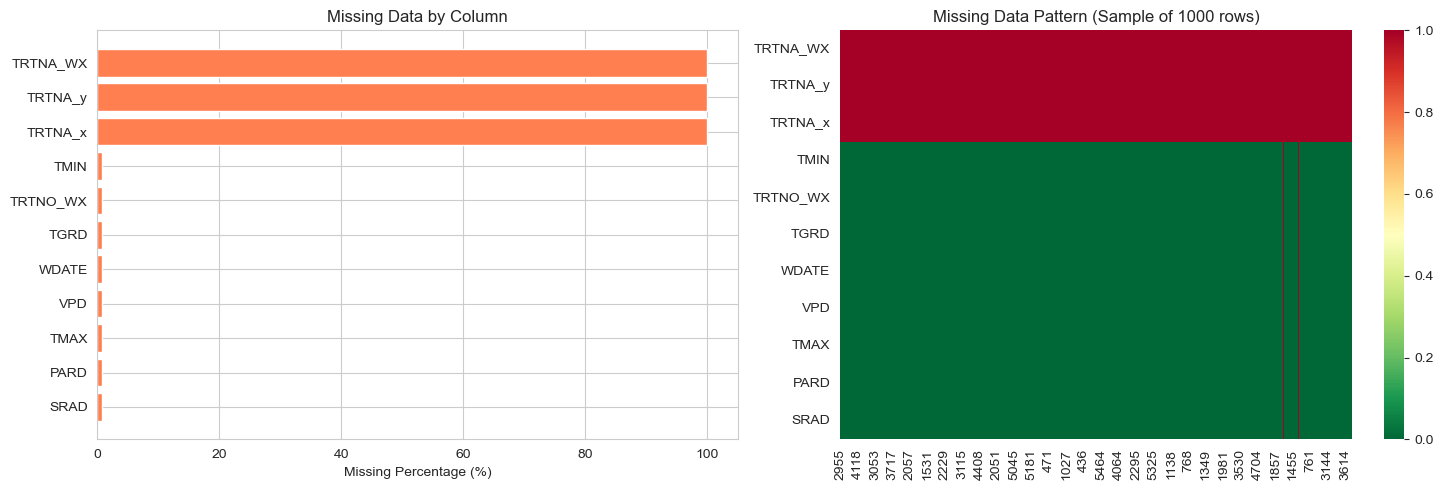


 Weather Data Missing Pattern:
  • Total rows affected: 40
  • Percentage: 0.72%
  • Affected RUNNO: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40)]
  • Affected DAP range: 0 - 0


In [4]:
# 3. MISSING VALUE ANALYSIS

missing_summary = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': df.isna().sum(),
    'Missing_Percentage': (df.isna().sum() / len(df)) * 100,
    'Data_Type': df.dtypes
}).sort_values('Missing_Count', ascending=False)

print("\n--- Missing Values Summary ---")
display(missing_summary[missing_summary['Missing_Count'] > 0])

if missing_summary['Missing_Count'].sum() == 0:
    print(" No missing values found!")

# Visualize missing data if any
if missing_summary['Missing_Count'].sum() > 0:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Bar plot
    missing_cols = missing_summary[missing_summary['Missing_Count'] > 0]
    axes[0].barh(missing_cols['Column'], missing_cols['Missing_Percentage'], color='coral')
    axes[0].set_xlabel('Missing Percentage (%)')
    axes[0].set_title('Missing Data by Column')
    axes[0].invert_yaxis()

    # Heatmap of missing patterns
    missing_mask = df[missing_cols['Column']].isna()
    if len(missing_mask) > 0:
        sample_size = min(1000, len(missing_mask))
        sns.heatmap(missing_mask.sample(sample_size).T, cbar=True,
                   yticklabels=True, cmap='RdYlGn_r', ax=axes[1])
        axes[1].set_title(f'Missing Data Pattern (Sample of {sample_size} rows)')

    plt.tight_layout()
    plt.show()

# Investigate weather data missing pattern
weather_cols = ['SRAD', 'PARD', 'TMAX', 'TMIN', 'VPD', 'WDATE', 'TGRD', 'TRTNO_WX']
existing_weather_cols = [col for col in weather_cols if col in df.columns]

if existing_weather_cols:
    weather_missing = df[df[existing_weather_cols].isnull().any(axis=1)]

    if len(weather_missing) > 0:
        print(f"\n Weather Data Missing Pattern:")
        print(f"  • Total rows affected: {len(weather_missing)}")
        print(f"  • Percentage: {len(weather_missing)/len(df)*100:.2f}%")
        if 'RUNNO' in df.columns:
            print(f"  • Affected RUNNO: {sorted(weather_missing['RUNNO'].unique())}")
        if 'DAP' in df.columns:
            print(f"  • Affected DAP range: {weather_missing['DAP'].min()} - {weather_missing['DAP'].max()}")

In [5]:
# 4. DUPLICATE ANALYSIS

# 4A. EXACT DUPLICATE ROWS

duplicates = df.duplicated().sum()
print(f"\n Total exact duplicate rows: {duplicates}")

if duplicates > 0:
    print(f"   Percentage: {(duplicates/len(df))*100:.2f}%")
    print("\n--- Sample Duplicate Rows ---")
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No exact duplicate rows found!")

# Check for duplicates on key columns
if 'RUNNO' in df.columns and 'DAP' in df.columns:
    key_dup = df.duplicated(subset=['RUNNO', 'DAP']).sum()
    print(f"\n Duplicates on [RUNNO, DAP]: {key_dup}")

    if key_dup > 0:
        print(" Warning: Same run measured multiple times on same day!")
        print("\n--- Sample Key Column Duplicates ---")
        display(df[df.duplicated(subset=['RUNNO', 'DAP'], keep=False)].sort_values(['RUNNO', 'DAP']).head(10))
    else:
        print("No duplicates on key columns [RUNNO, DAP]")

# 4B. EXACT DUPLICATE COLUMNS

def find_exact_duplicate_columns(dataframe):
    """
    Find columns that have exactly identical values (including NaN positions).
    Returns dictionary of duplicate groups.
    """
    duplicate_groups = {}
    cols = dataframe.columns.tolist()
    checked = set()

    for i, col1 in enumerate(cols):
        if col1 in checked:
            continue

        duplicates_found = [col1]

        for col2 in cols[i+1:]:
            if col2 in checked:
                continue

            # Check exact equality (handles NaN properly)
            if dataframe[col1].equals(dataframe[col2]):
                duplicates_found.append(col2)
                checked.add(col2)

        if len(duplicates_found) > 1:
            duplicate_groups[tuple(duplicates_found)] = len(duplicates_found)

        checked.add(col1)

    return duplicate_groups

# Find exact duplicate columns

duplicate_cols = find_exact_duplicate_columns(df)

if duplicate_cols:
    print(f"\n Found {len(duplicate_cols)} group(s) of exact duplicate columns:\n")

    total_duplicates = 0
    columns_to_drop = []

    for idx, (cols, count) in enumerate(duplicate_cols.items(), 1):
        print(f"Group {idx}: {list(cols)}")
        print(f"Number of identical columns: {count}")
        print(f"Recommendation: Keep '{cols[0]}', drop the rest")

        # Show sample values to verify
        print(f"Sample values: {df[cols[0]].dropna().head(3).tolist()}")
        print()

        # Track columns to drop (keep first, drop rest)
        columns_to_drop.extend(list(cols[1:]))
        total_duplicates += (count - 1)

    print(f"Summary:")
    print(f"Total duplicate column groups: {len(duplicate_cols)}")
    print(f"Total columns that can be dropped: {total_duplicates}")
    print(f"\n Columns to drop: {columns_to_drop}")

    # Create summary table
    dup_summary = []
    for cols in duplicate_cols.keys():
        dup_summary.append({
            'Keep': cols[0],
            'Drop': ', '.join(cols[1:]),
            'Num_Duplicates': len(cols)
        })

    print("\n--- Duplicate Columns Summary Table ---")
    dup_df = pd.DataFrame(dup_summary)
    display(dup_df)

else:
    print("No exact duplicate columns found!")
    print("All 46 columns contain unique data.")


 Total exact duplicate rows: 0
No exact duplicate rows found!

 Duplicates on [RUNNO, DAP]: 0
No duplicates on key columns [RUNNO, DAP]

 Found 3 group(s) of exact duplicate columns:

Group 1: ['TRTNO', 'TRTNO_x', 'TRTNO_y']
Number of identical columns: 3
Recommendation: Keep 'TRTNO', drop the rest
Sample values: [1, 1, 1]

Group 2: ['LAID', 'LAI']
Number of identical columns: 2
Recommendation: Keep 'LAID', drop the rest
Sample values: [0.0, 0.0, 0.0]

Group 3: ['TRTNA_x', 'TRTNA_y', 'TRTNA_WX']
Number of identical columns: 3
Recommendation: Keep 'TRTNA_x', drop the rest
Sample values: []

Summary:
Total duplicate column groups: 3
Total columns that can be dropped: 5

 Columns to drop: ['TRTNO_x', 'TRTNO_y', 'LAI', 'TRTNA_y', 'TRTNA_WX']

--- Duplicate Columns Summary Table ---


,Keep,Drop,Num_Duplicates
0,TRTNO,"TRTNO_x, TRTNO_y",3
1,LAID,LAI,2
2,TRTNA_x,"TRTNA_y, TRTNA_WX",3



--- Growth Stage Transition Matrix ---

Transition counts (rows=current stage, columns=next stage):


GSTD_next,0.0,1.0,3.0,5.0,7.0,8.0,NaN
GSTD,,,,,,,
0,1655,40,0,0,0,0,0
1,0,208,40,0,0,0,0
3,0,0,153,40,0,0,0
5,0,0,0,1332,40,0,0
7,0,0,0,0,560,40,0
8,0,0,0,0,0,1372,40



Transition probabilities (%):


GSTD_next,0.0,1.0,3.0,5.0,7.0,8.0,NaN
GSTD,,,,,,,
0,97.64,2.36,0.00,0.00,0.00,0.00,0.00
1,0.00,83.87,16.13,0.00,0.00,0.00,0.00
3,0.00,0.00,79.27,20.73,0.00,0.00,0.00
5,0.00,0.00,0.00,97.08,2.92,0.00,0.00
7,0.00,0.00,0.00,0.00,93.33,6.67,0.00
8,0.00,0.00,0.00,0.00,0.00,97.17,2.83


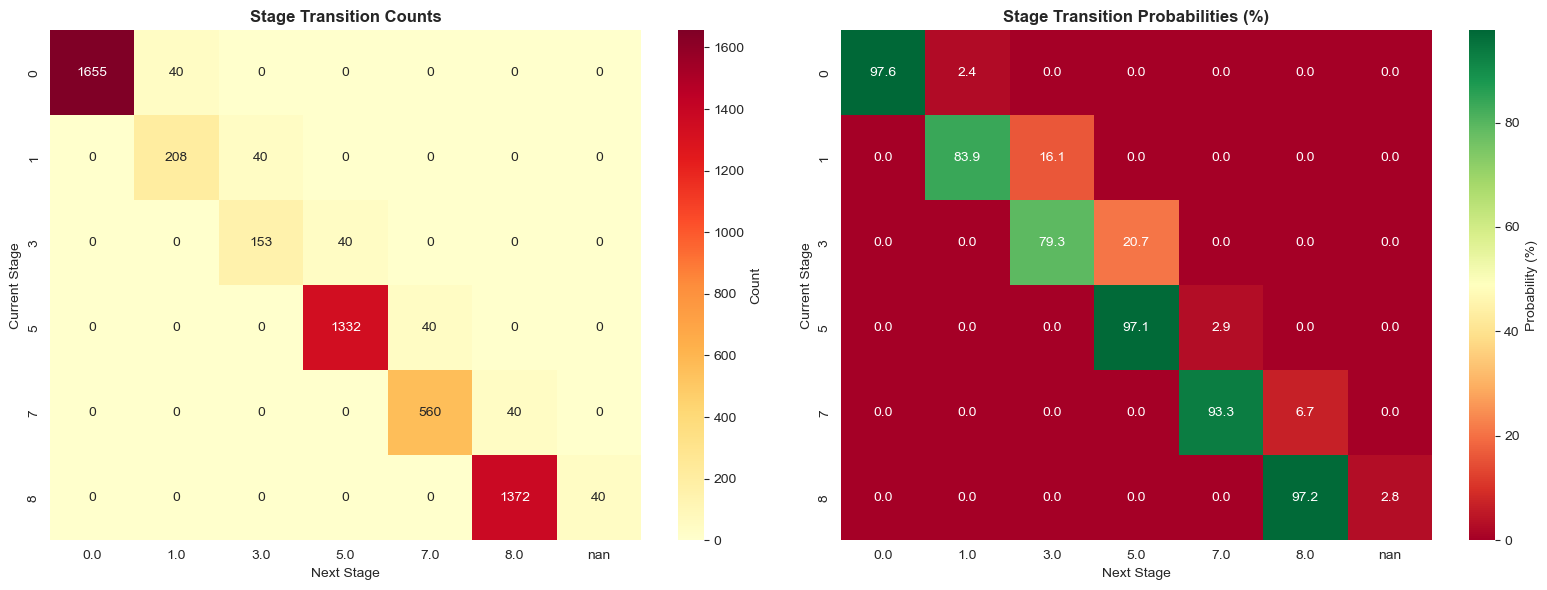


 Unusual Transition Patterns:
No stage reversals detected
Found 120 instances of plants skipping stages
Max jump: 2 stages

--- Days Spent in Each Growth Stage ---


,Occurrences,Mean_Days,Median_Days,Std_Days,Min_Days,Max_Days
GSTD,,,,,,
0,40,42.38,43.0,1.86,39,44
1,40,6.20,6.0,0.41,6,7
3,40,4.82,5.0,0.38,4,5
5,40,34.30,34.0,1.84,31,37
7,40,15.00,15.0,0.00,15,15
8,40,35.30,34.0,3.45,31,42


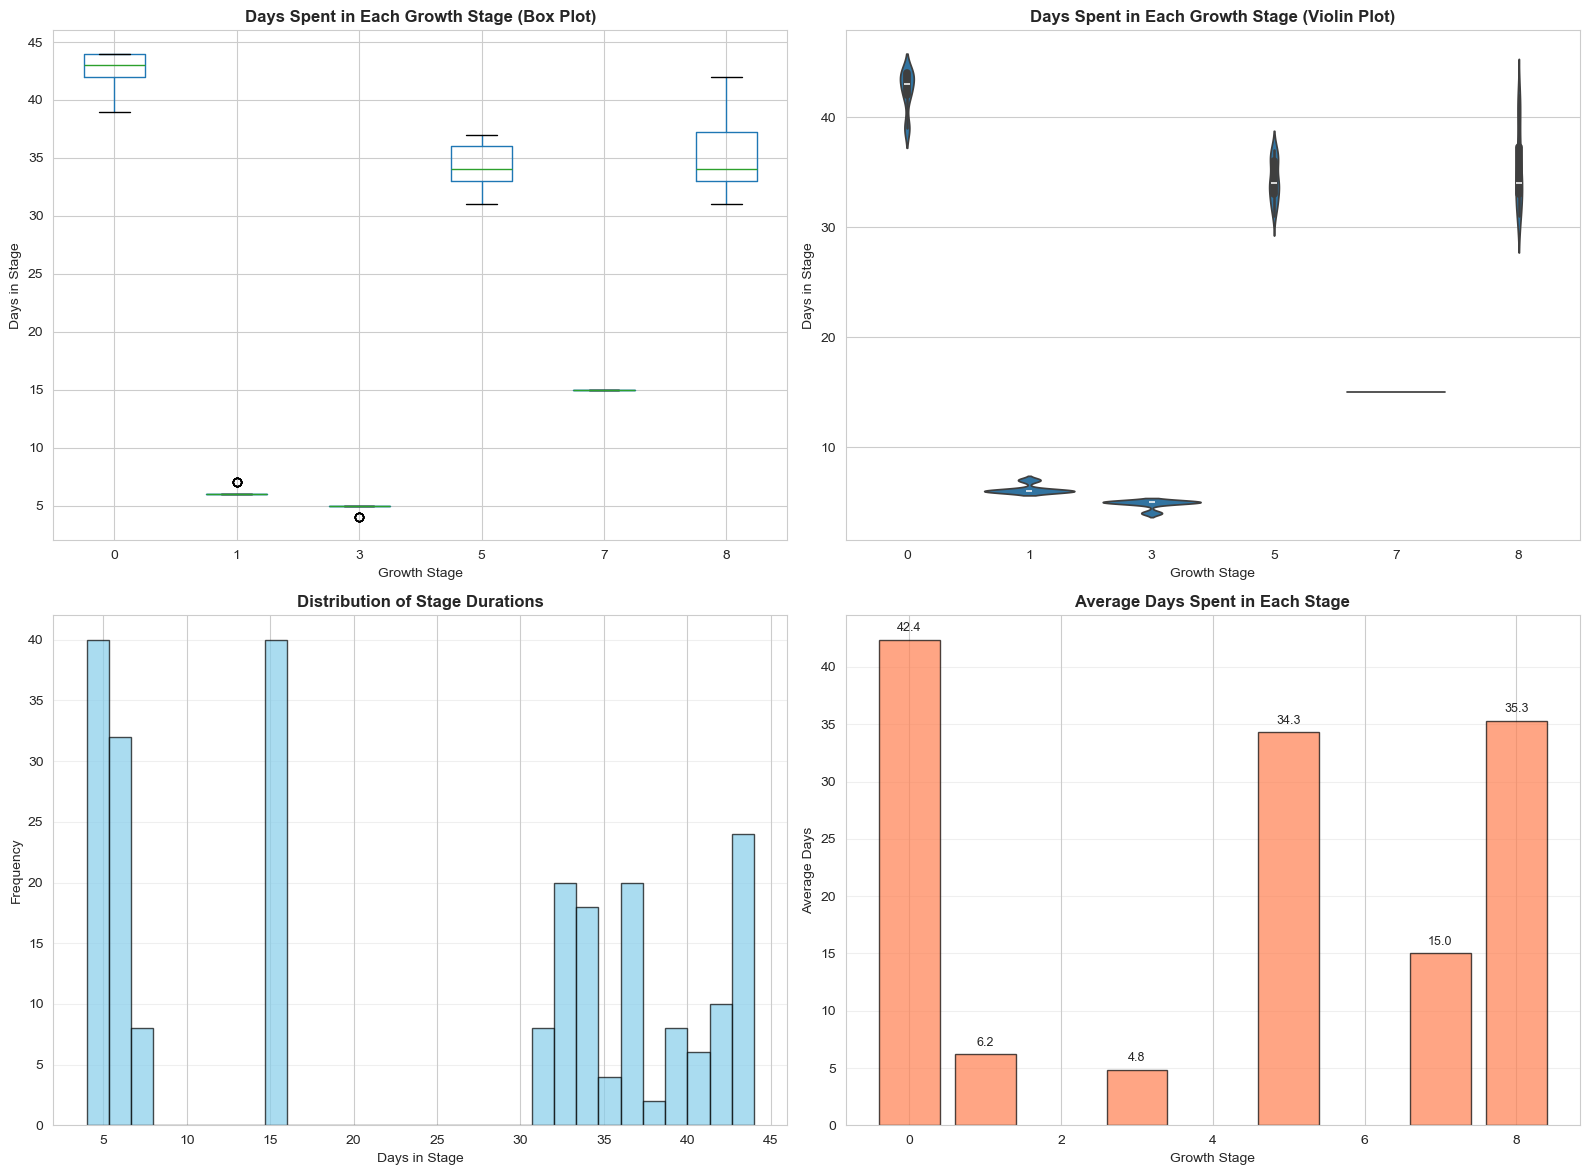


 Stage Duration Insights:
Fastest stage: 3 (4.8 days)
Slowest stage: 0 (42.4 days)

--- DAP When Each Stage is Reached ---


,Count,Mean_DAP,Median_DAP,Std_DAP,Min_DAP,Max_DAP
GSTD,,,,,,
0,40,0.00,0.0,0.00,0,0
1,40,42.38,43.0,1.86,39,44
3,40,48.58,49.0,2.06,45,51
5,40,53.40,54.0,1.88,50,55
7,40,87.70,89.0,3.45,81,92
8,40,102.70,104.0,3.45,96,107


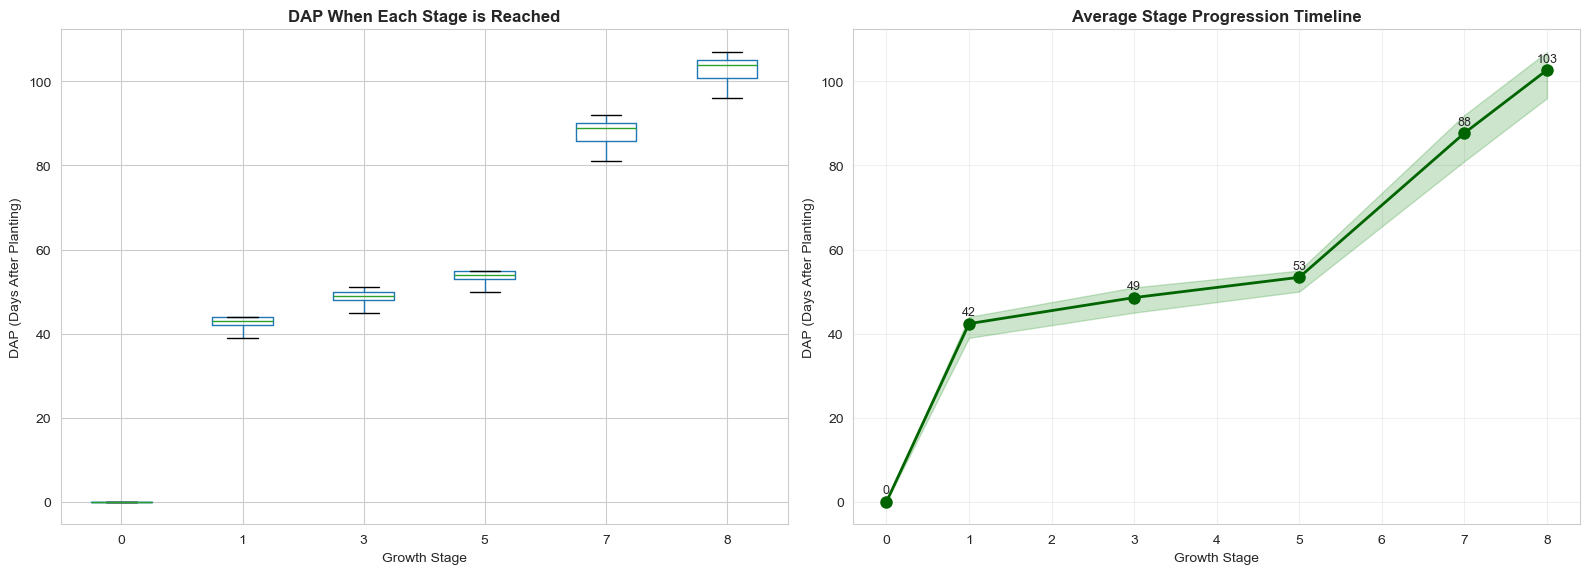

2.4 TREATMENT EFFECTS ON STAGE PROGRESSION

--- Average DAP at Each Stage by Treatment ---


GSTD,0,1,3,5,7,8
TRTNO,,,,,,
1,0.0,42.4,48.6,53.4,88.0,103.0
2,0.0,42.4,48.6,53.4,88.2,103.2
3,0.0,42.4,48.6,53.4,86.8,101.8
4,0.0,42.4,48.6,53.4,86.8,101.8
5,0.0,42.4,48.6,53.4,88.0,103.0
6,0.0,42.4,48.6,53.4,88.2,103.2
7,0.0,42.2,48.4,53.4,87.8,102.8
8,0.0,42.4,48.6,53.4,87.8,102.8


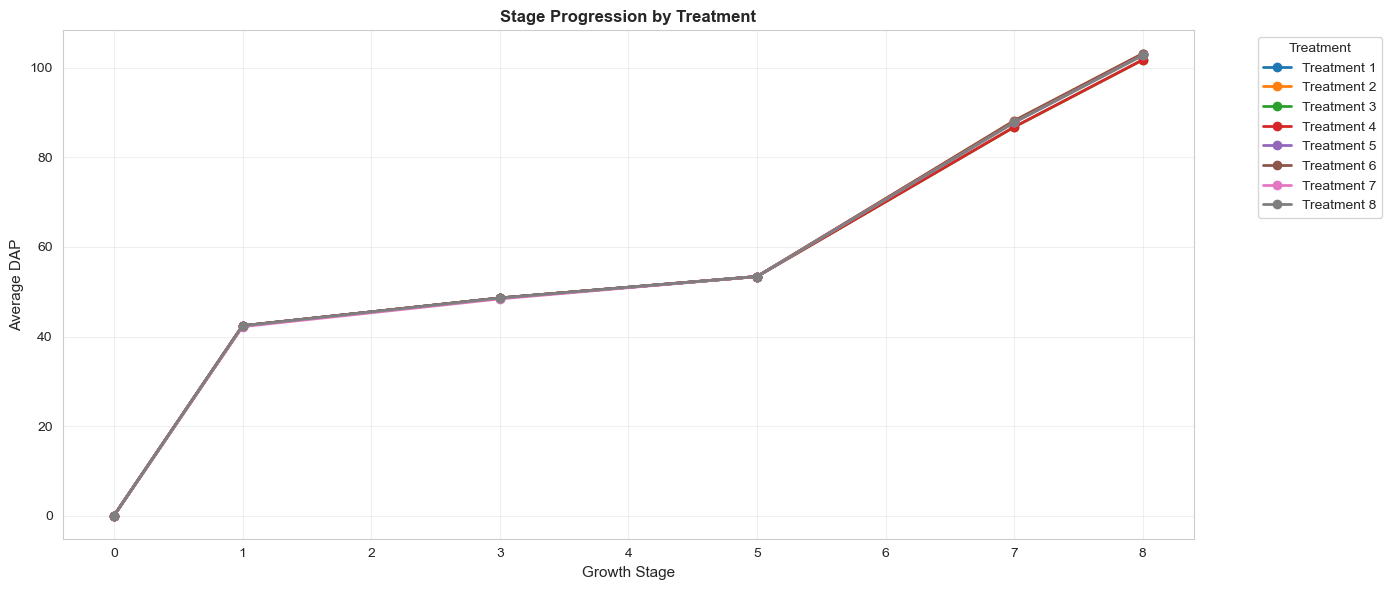


 Treatment Performance:
Fastest to final stage: Treatment 3
Slowest to final stage: Treatment 2

--- Percentage of Runs Reaching Each Stage ---


,Stage,Pct_Reached,Runs_Reached,Total_Runs
0,0,100.0,40,40
1,1,100.0,40,40
2,3,100.0,40,40
3,5,100.0,40,40
4,7,100.0,40,40
5,8,100.0,40,40


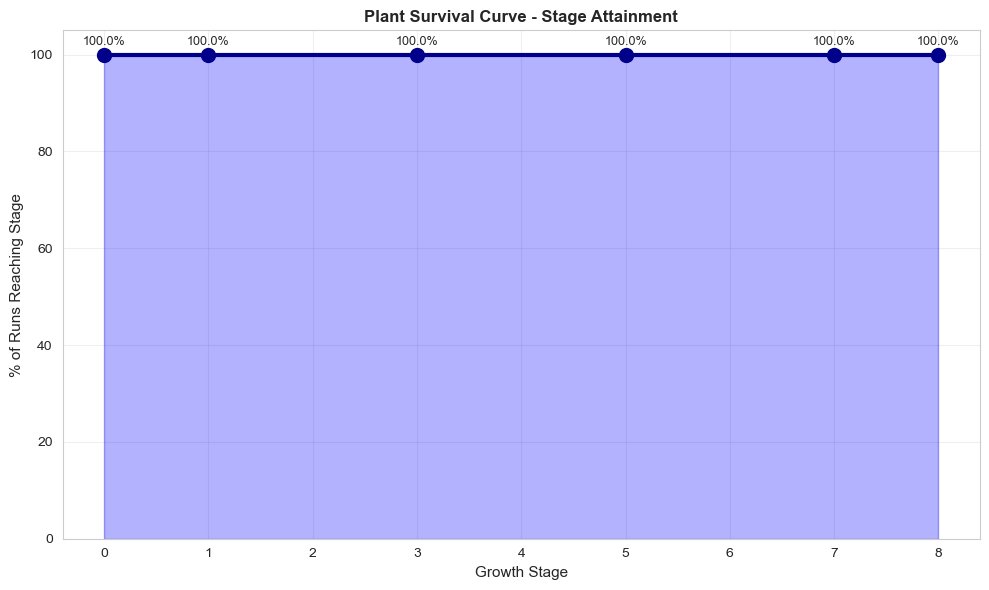


 All runs complete the full growth cycle


In [6]:
# SECTION 2: TARGET VARIABLE DEEP DIVE - STAGE TRANSITIONS

if 'GSTD' not in df.columns or 'DAP' not in df.columns or 'RUNNO' not in df.columns:
    print(" Required columns (GSTD, DAP, RUNNO) not found. Skipping this section.")
else:

    # 2.1 STAGE TRANSITION ANALYSIS

    print("\n--- Growth Stage Transition Matrix ---")

    # Calculate transitions for each run
    df_sorted = df.sort_values(['RUNNO', 'DAP'])
    df_sorted['GSTD_next'] = df_sorted.groupby('RUNNO')['GSTD'].shift(-1)

    # Create transition matrix (current stage -> next stage)
    transition_matrix = pd.crosstab(
        df_sorted['GSTD'],
        df_sorted['GSTD_next'],
        dropna=False
    )

    print("\nTransition counts (rows=current stage, columns=next stage):")
    display(transition_matrix)

    # Calculate transition probabilities
    transition_prob = transition_matrix.div(transition_matrix.sum(axis=1), axis=0) * 100
    print("\nTransition probabilities (%):")
    display(transition_prob.round(2))

    # Visualize transition matrix
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Heatmap of transition counts
    sns.heatmap(transition_matrix, annot=True, fmt='d', cmap='YlOrRd',
                ax=axes[0], cbar_kws={'label': 'Count'})
    axes[0].set_title('Stage Transition Counts', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Next Stage')
    axes[0].set_ylabel('Current Stage')

    # Heatmap of transition probabilities
    sns.heatmap(transition_prob, annot=True, fmt='.1f', cmap='RdYlGn',
                ax=axes[1], cbar_kws={'label': 'Probability (%)'})
    axes[1].set_title('Stage Transition Probabilities (%)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Next Stage')
    axes[1].set_ylabel('Current Stage')

    plt.tight_layout()
    plt.show()

    # Identify unusual transitions
    print("\n Unusual Transition Patterns:")

    # Check for stage reversals (going backwards)
    reversals = df_sorted[df_sorted['GSTD_next'] < df_sorted['GSTD']].dropna(subset=['GSTD_next'])
    if len(reversals) > 0:
        print(f"Found {len(reversals)} stage reversals (plants going backwards in growth)")
        print(f"Affected runs: {reversals['RUNNO'].unique()}")
    else:
        print("No stage reversals detected")

    # Check for stage skipping (jumping multiple stages)
    stage_jumps = df_sorted[df_sorted['GSTD_next'] - df_sorted['GSTD'] > 1].dropna(subset=['GSTD_next'])
    if len(stage_jumps) > 0:
        print(f"Found {len(stage_jumps)} instances of plants skipping stages")
        print(f"Max jump: {int((stage_jumps['GSTD_next'] - stage_jumps['GSTD']).max())} stages")
    else:
        print("No stage skipping detected")

    # 2.2 TIME TO TRANSITION - DAYS SPENT IN EACH STAGE

    # Calculate days spent in each stage for each run
    stage_duration = []

    for run in df['RUNNO'].unique():
        run_data = df[df['RUNNO'] == run].sort_values('DAP')

        # Find stage changes
        run_data['stage_changed'] = run_data['GSTD'].diff() != 0
        run_data['stage_group'] = run_data['stage_changed'].cumsum()

        # Calculate duration for each stage period
        for group_id, group in run_data.groupby('stage_group'):
            stage_duration.append({
                'RUNNO': run,
                'GSTD': group['GSTD'].iloc[0],
                'Start_DAP': group['DAP'].min(),
                'End_DAP': group['DAP'].max(),
                'Days_in_Stage': group['DAP'].max() - group['DAP'].min() + 1,
                'TRTNO': group['TRTNO'].iloc[0] if 'TRTNO' in df.columns else None
            })

    duration_df = pd.DataFrame(stage_duration)

    print("\n--- Days Spent in Each Growth Stage ---")
    stage_summary = duration_df.groupby('GSTD')['Days_in_Stage'].agg([
        'count', 'mean', 'median', 'std', 'min', 'max'
    ]).round(2)
    stage_summary.columns = ['Occurrences', 'Mean_Days', 'Median_Days', 'Std_Days', 'Min_Days', 'Max_Days']
    display(stage_summary)

    # Visualize stage durations
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Box plot of days in each stage
    duration_df.boxplot(column='Days_in_Stage', by='GSTD', ax=axes[0, 0])
    axes[0, 0].set_title('Days Spent in Each Growth Stage (Box Plot)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Growth Stage')
    axes[0, 0].set_ylabel('Days in Stage')
    axes[0, 0].get_figure().suptitle('')  # Remove default title

    # Violin plot for better distribution view
    sns.violinplot(data=duration_df, x='GSTD', y='Days_in_Stage', ax=axes[0, 1])
    axes[0, 1].set_title('Days Spent in Each Growth Stage (Violin Plot)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Growth Stage')
    axes[0, 1].set_ylabel('Days in Stage')

    # Histogram of all stage durations
    axes[1, 0].hist(duration_df['Days_in_Stage'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[1, 0].set_xlabel('Days in Stage')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Distribution of Stage Durations', fontsize=12, fontweight='bold')
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Average days in each stage (bar chart)
    stage_means = duration_df.groupby('GSTD')['Days_in_Stage'].mean()
    axes[1, 1].bar(stage_means.index, stage_means.values, color='coral', alpha=0.7, edgecolor='black')
    axes[1, 1].set_xlabel('Growth Stage')
    axes[1, 1].set_ylabel('Average Days')
    axes[1, 1].set_title('Average Days Spent in Each Stage', fontsize=12, fontweight='bold')
    axes[1, 1].grid(axis='y', alpha=0.3)

    # Add value labels on bars
    for i, v in enumerate(stage_means.values):
        axes[1, 1].text(stage_means.index[i], v + 0.5, f'{v:.1f}',
                       ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

    # Identify stages with high variability
    print("\n Stage Duration Insights:")
    high_var_stages = stage_summary[stage_summary['Std_Days'] > stage_summary['Mean_Days'] * 0.5]
    if len(high_var_stages) > 0:
        print(f"High variability stages (std > 50% of mean):")
        for stage in high_var_stages.index:
            print(f"Stage {stage}: {stage_summary.loc[stage, 'Mean_Days']:.1f} ± {stage_summary.loc[stage, 'Std_Days']:.1f} days")

    fastest_stage = stage_summary['Mean_Days'].idxmin()
    slowest_stage = stage_summary['Mean_Days'].idxmax()
    print(f"Fastest stage: {fastest_stage} ({stage_summary.loc[fastest_stage, 'Mean_Days']:.1f} days)")
    print(f"Slowest stage: {slowest_stage} ({stage_summary.loc[slowest_stage, 'Mean_Days']:.1f} days)")

    # 2.3 DAP AT EACH STAGE TRANSITION

    # Find the DAP when each stage is first reached for each run
    stage_entry = df.sort_values(['RUNNO', 'DAP']).groupby(['RUNNO', 'GSTD'])['DAP'].min().reset_index()
    stage_entry.columns = ['RUNNO', 'GSTD', 'Entry_DAP']

    print("\n--- DAP When Each Stage is Reached ---")
    dap_summary = stage_entry.groupby('GSTD')['Entry_DAP'].agg([
        'count', 'mean', 'median', 'std', 'min', 'max'
    ]).round(2)
    dap_summary.columns = ['Count', 'Mean_DAP', 'Median_DAP', 'Std_DAP', 'Min_DAP', 'Max_DAP']
    display(dap_summary)

    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Box plot of DAP at each stage entry
    stage_entry.boxplot(column='Entry_DAP', by='GSTD', ax=axes[0])
    axes[0].set_title('DAP When Each Stage is Reached', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Growth Stage')
    axes[0].set_ylabel('DAP (Days After Planting)')
    axes[0].get_figure().suptitle('')

    # Line plot showing progression
    stage_means_dap = stage_entry.groupby('GSTD')['Entry_DAP'].mean()
    axes[1].plot(stage_means_dap.index, stage_means_dap.values,
                marker='o', linewidth=2, markersize=8, color='darkgreen')
    axes[1].fill_between(stage_means_dap.index,
                         stage_entry.groupby('GSTD')['Entry_DAP'].min(),
                         stage_entry.groupby('GSTD')['Entry_DAP'].max(),
                         alpha=0.2, color='green')
    axes[1].set_xlabel('Growth Stage')
    axes[1].set_ylabel('DAP (Days After Planting)')
    axes[1].set_title('Average Stage Progression Timeline', fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3)

    # Add labels
    for stage, dap in stage_means_dap.items():
        axes[1].text(stage, dap + 2, f'{dap:.0f}', ha='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    # 2.4 TREATMENT EFFECTS ON STAGE PROGRESSION

    if 'TRTNO' in df.columns:
        print("2.4 TREATMENT EFFECTS ON STAGE PROGRESSION")

        # Compare stage progression across treatments
        treatment_stage = stage_entry.merge(
            df[['RUNNO', 'TRTNO']].drop_duplicates(),
            on='RUNNO'
        )

        print("\n--- Average DAP at Each Stage by Treatment ---")
        treatment_comparison = treatment_stage.pivot_table(
            index='TRTNO',
            columns='GSTD',
            values='Entry_DAP',
            aggfunc='mean'
        ).round(1)
        display(treatment_comparison)

        # Visualize treatment effects
        fig, ax = plt.subplots(figsize=(14, 6))

        for trt in treatment_stage['TRTNO'].unique():
            trt_data = treatment_stage[treatment_stage['TRTNO'] == trt].groupby('GSTD')['Entry_DAP'].mean()
            ax.plot(trt_data.index, trt_data.values, marker='o', label=f'Treatment {trt}', linewidth=2)

        ax.set_xlabel('Growth Stage', fontsize=11)
        ax.set_ylabel('Average DAP', fontsize=11)
        ax.set_title('Stage Progression by Treatment', fontsize=12, fontweight='bold')
        ax.legend(title='Treatment', bbox_to_anchor=(1.05, 1), loc='upper left')
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Identify fastest/slowest treatments
        final_stage_dap = treatment_stage[treatment_stage['GSTD'] == treatment_stage['GSTD'].max()]
        fastest_treatment = final_stage_dap.groupby('TRTNO')['Entry_DAP'].mean().idxmin()
        slowest_treatment = final_stage_dap.groupby('TRTNO')['Entry_DAP'].mean().idxmax()

        print(f"\n Treatment Performance:")
        print(f"Fastest to final stage: Treatment {fastest_treatment}")
        print(f"Slowest to final stage: Treatment {slowest_treatment}")

    # 2.5 SURVIVAL-STYLE ANALYSIS

    # Calculate what % of runs reach each stage
    max_stage_per_run = df.groupby('RUNNO')['GSTD'].max()

    survival_data = []
    for stage in sorted(df['GSTD'].unique()):
        pct_reached = (max_stage_per_run >= stage).sum() / len(max_stage_per_run) * 100
        survival_data.append({
            'Stage': stage,
            'Pct_Reached': pct_reached,
            'Runs_Reached': (max_stage_per_run >= stage).sum(),
            'Total_Runs': len(max_stage_per_run)
        })

    survival_df = pd.DataFrame(survival_data)

    print("\n--- Percentage of Runs Reaching Each Stage ---")
    display(survival_df)

    # Visualize survival curve
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(survival_df['Stage'], survival_df['Pct_Reached'],
           marker='o', linewidth=3, markersize=10, color='darkblue')
    ax.fill_between(survival_df['Stage'], survival_df['Pct_Reached'],
                    alpha=0.3, color='blue')
    ax.set_xlabel('Growth Stage', fontsize=11)
    ax.set_ylabel('% of Runs Reaching Stage', fontsize=11)
    ax.set_title('Plant Survival Curve - Stage Attainment', fontsize=12, fontweight='bold')
    ax.set_ylim([0, 105])
    ax.grid(True, alpha=0.3)

    # Add percentage labels
    for idx, row in survival_df.iterrows():
        ax.text(row['Stage'], row['Pct_Reached'] + 2,
               f"{row['Pct_Reached']:.1f}%",
               ha='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    # Check if all runs complete all stages
    if survival_df['Pct_Reached'].min() < 100:
        incomplete_stage = survival_df[survival_df['Pct_Reached'] < 100].iloc[0]
        print(f"\n Not all runs complete the growth cycle:")
        print(f"First incomplete stage: {incomplete_stage['Stage']}")
        print(f"Only {incomplete_stage['Pct_Reached']:.1f}% of runs reach this stage")
    else:
        print("\n All runs complete the full growth cycle")

SECTION 3: CORRELATION ANALYSIS
3.1 CORRELATION WITH TARGET VARIABLE (GSTD)

--- Top 15 Features Correlated with GSTD ---


,Feature,Spearman_Corr,Pearson_Corr,Abs_Spearman
0,GSTD,1.000000,1.000000,1.000000
1,DOY,0.966521,0.953117,0.966521
2,DAP,0.966521,0.953117,0.966521
3,GWAD,0.894109,0.833616,0.894109
4,TGRD,0.838356,0.806943,0.838356
5,TMAX,0.812442,0.777399,0.812442
6,CWAD,0.807729,0.776203,0.807729
7,TMIN,0.805904,0.757176,0.805904
8,NI9D,0.625761,0.583522,0.625761
40,SW2D,-0.568725,-0.584170,0.568725


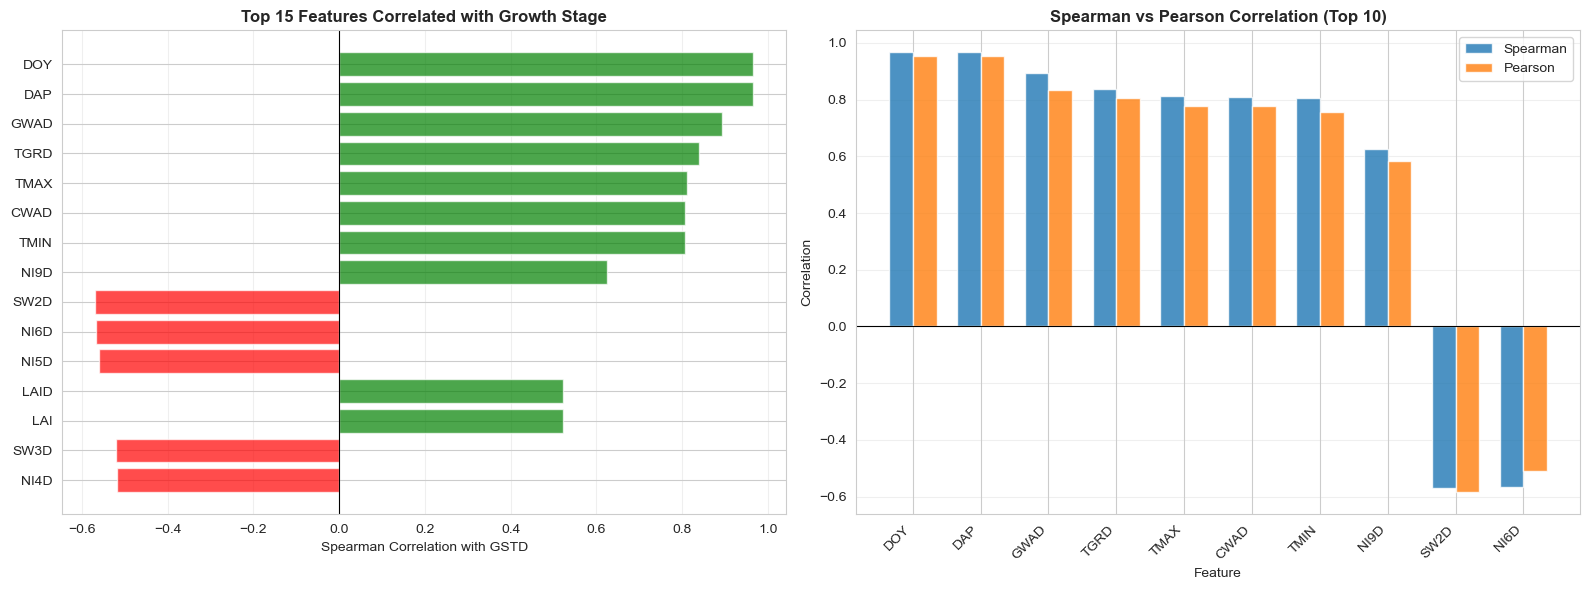


 Features with |correlation| > 0.5: 15

Strongly correlated features:
   • DOY: 0.967 (positive)
   • DAP: 0.967 (positive)
   • GWAD: 0.894 (positive)
   • TGRD: 0.838 (positive)
   • TMAX: 0.812 (positive)
   • CWAD: 0.808 (positive)
   • TMIN: 0.806 (positive)
   • NI9D: 0.626 (positive)
   • SW2D: -0.569 (negative)
   • NI6D: -0.568 (negative)
   • NI5D: -0.561 (negative)
   • LAID: 0.522 (positive)
   • LAI: 0.522 (positive)
   • SW3D: -0.520 (negative)
   • NI4D: -0.518 (negative)
3.2 OVERALL CORRELATION MATRIX

--- Correlation Matrix (15 key features) ---


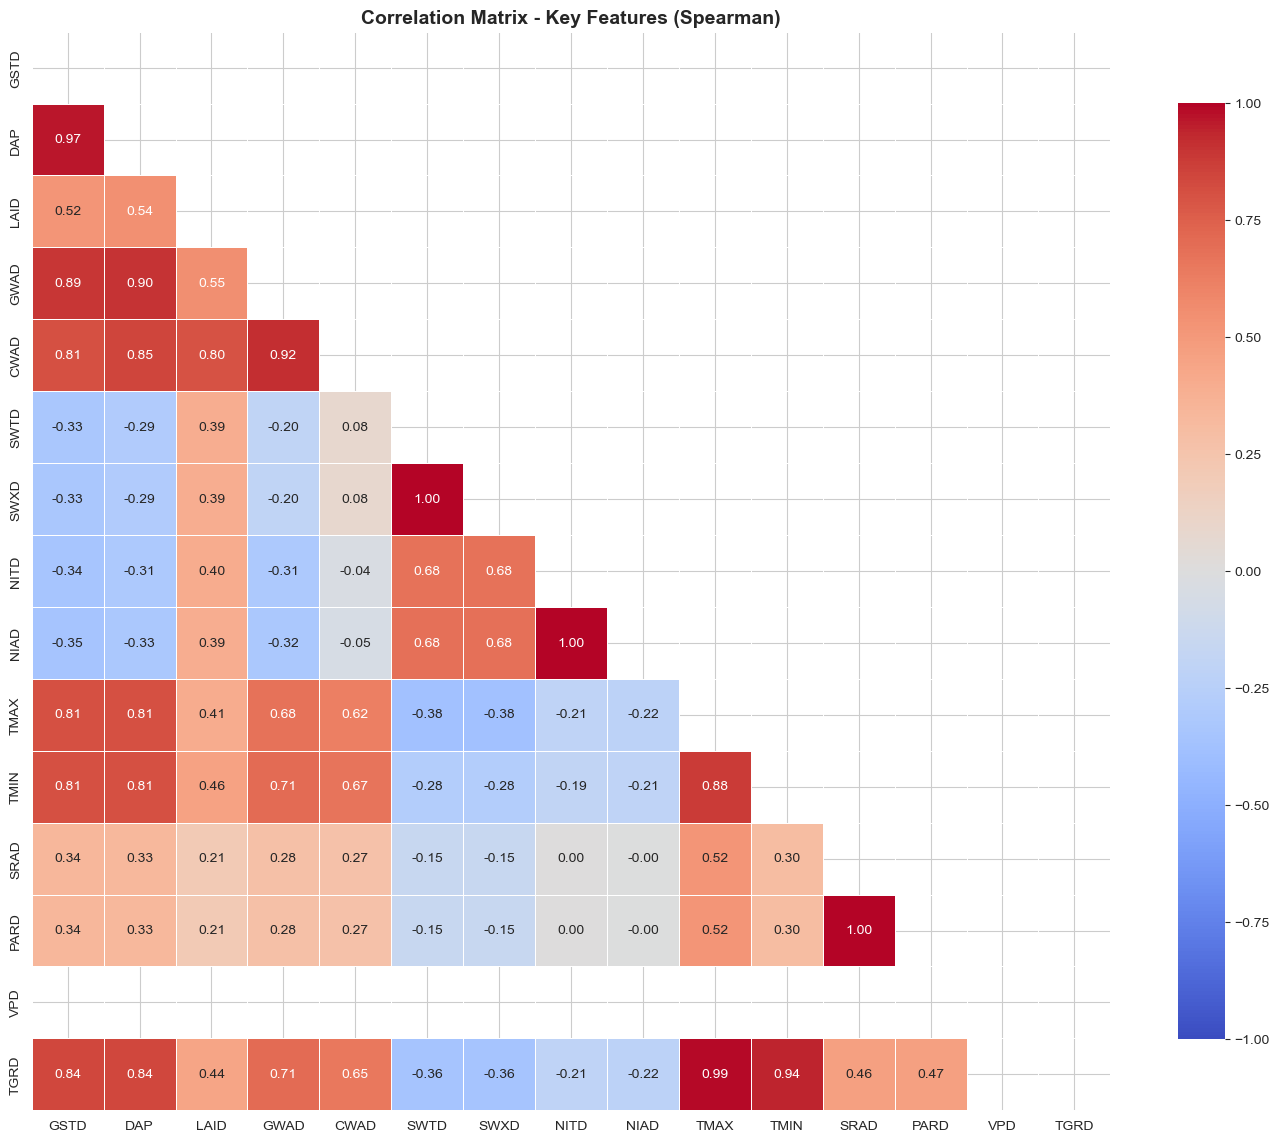


--- Highly Correlated Feature Pairs (|r| > 0.8) ---


,Feature_1,Feature_2,Correlation
17,SRAD,PARD,0.999944
12,SWTD,SWXD,0.999899
13,NITD,NIAD,0.997641
15,TMAX,TGRD,0.987363
0,GSTD,DAP,0.966521
16,TMIN,TGRD,0.939485
11,GWAD,CWAD,0.916167
6,DAP,GWAD,0.904604
1,GSTD,GWAD,0.894109
14,TMAX,TMIN,0.879549



 Found 18 highly correlated pairs - potential multicollinearity
3.3 SOIL LAYER CORRELATION PATTERNS

--- Soil Water Layers Correlation ---


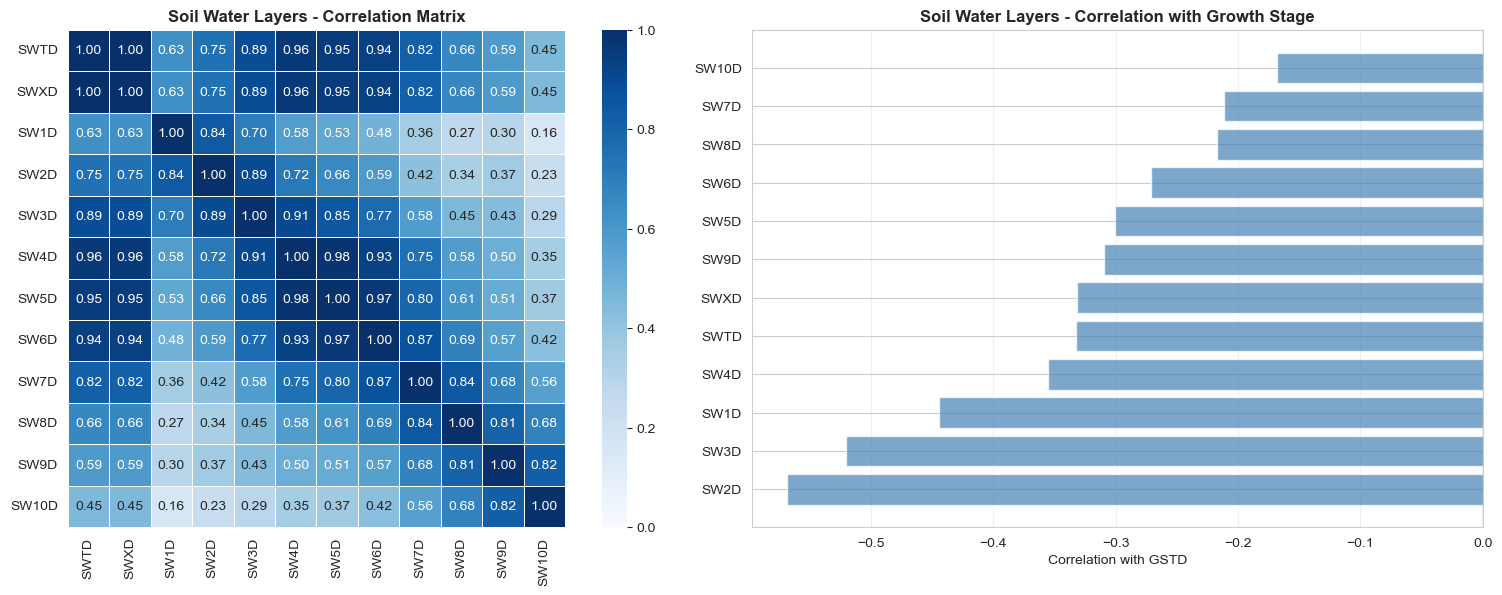


 Most important water layer: SW2D (r = -0.569)

--- Soil Nitrate Layers Correlation ---


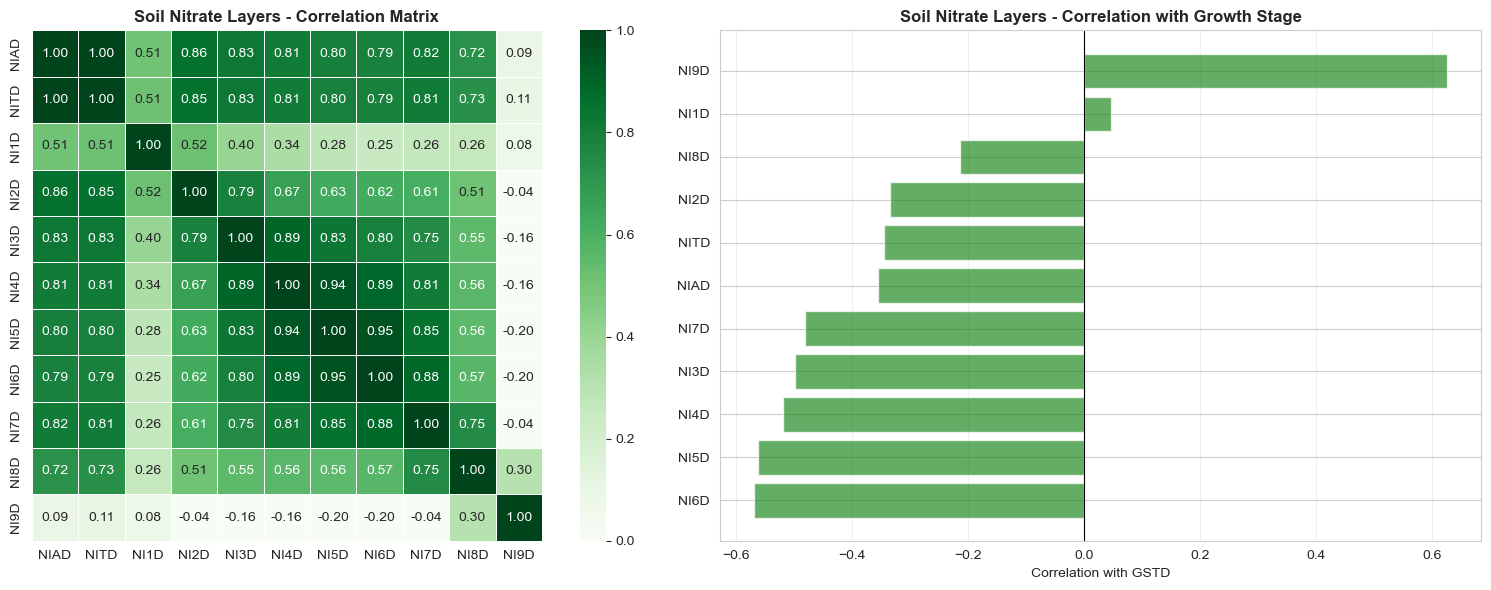


 Most important nitrate layer: NI9D (r = 0.626)
3.4 SCATTER PLOTS - KEY RELATIONSHIPS WITH GSTD


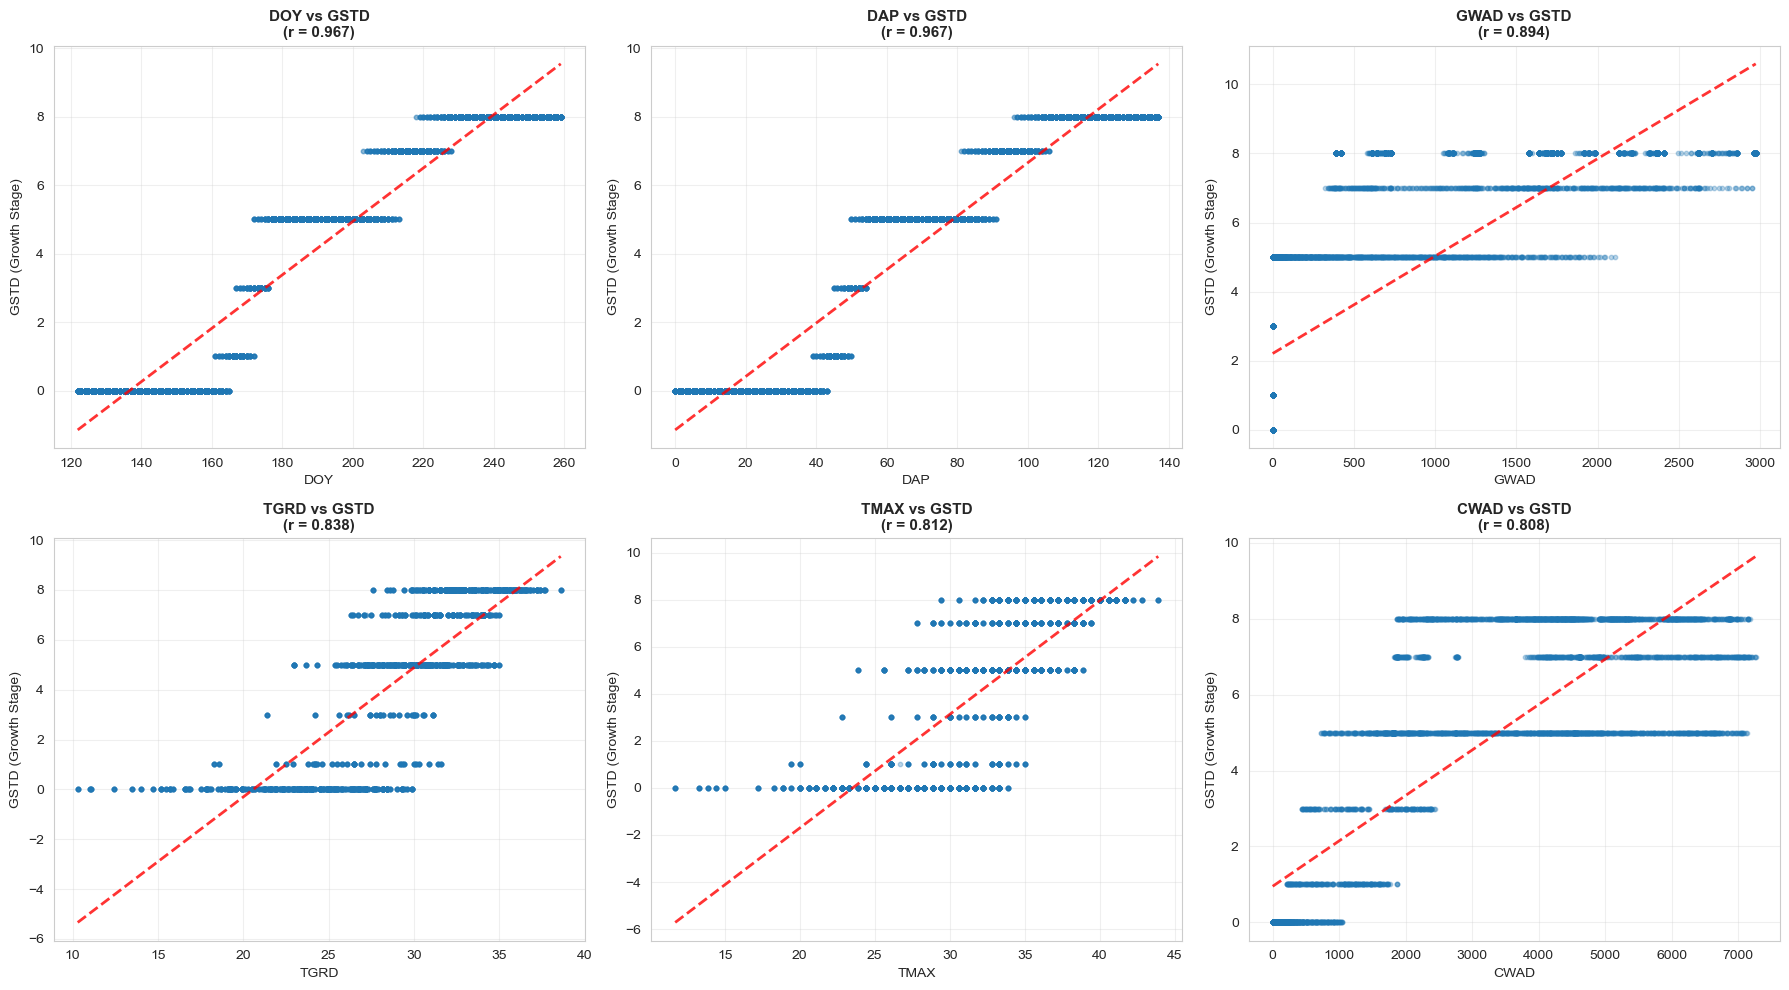

3.5 STAGE-SPECIFIC CORRELATIONS

--- How correlations change across growth stages ---


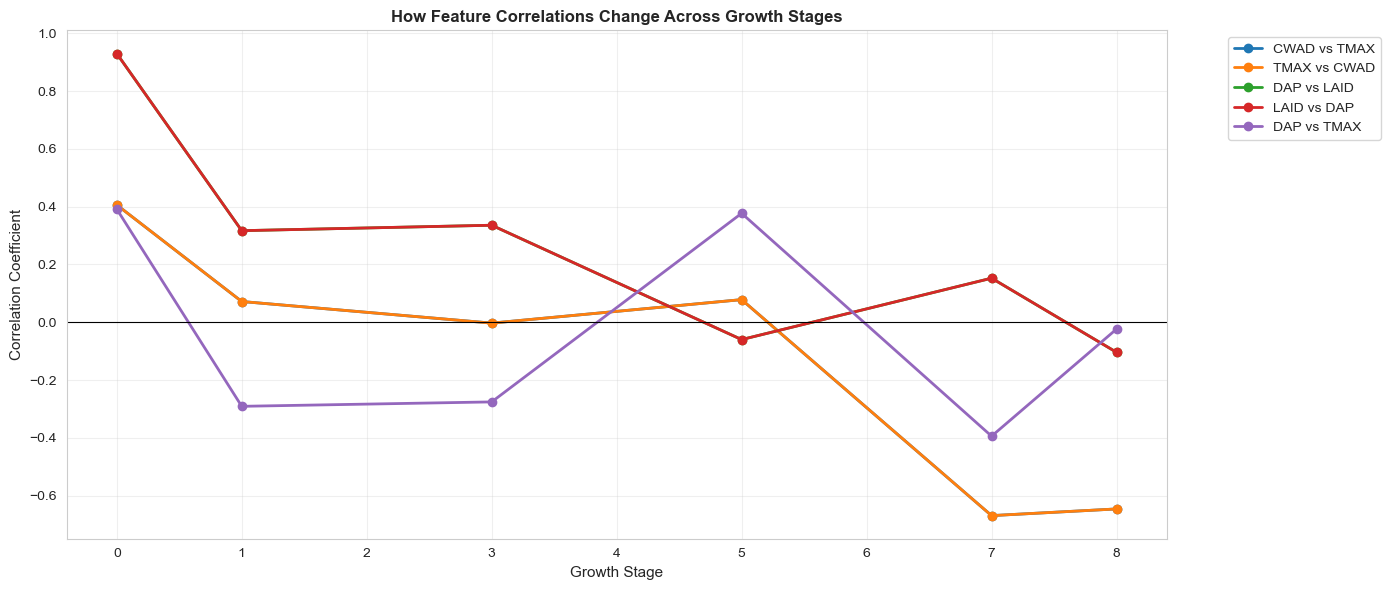


 Showing top 5 feature pairs with most variable correlations across stages


In [7]:
# SECTION 3: CORRELATION ANALYSIS

print("SECTION 3: CORRELATION ANALYSIS")

# 3.1 CORRELATION WITH TARGET (GSTD)

print("3.1 CORRELATION WITH TARGET VARIABLE (GSTD)")

# Select only numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if 'GSTD' in numeric_cols:
    # Calculate Spearman correlation (better for ordinal target)
    spearman_corr = df[numeric_cols].corr(method='spearman')['GSTD'].sort_values(ascending=False)

    # Calculate Pearson correlation for comparison
    pearson_corr = df[numeric_cols].corr(method='pearson')['GSTD'].sort_values(ascending=False)

    # Combine into summary
    corr_summary = pd.DataFrame({
        'Feature': spearman_corr.index,
        'Spearman_Corr': spearman_corr.values,
        'Pearson_Corr': pearson_corr.values,
        'Abs_Spearman': abs(spearman_corr.values)
    }).sort_values('Abs_Spearman', ascending=False)

    print("\n--- Top 15 Features Correlated with GSTD ---")
    display(corr_summary.head(15))

    # Visualize top correlations
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Bar plot of top positive and negative correlations
    top_n = 15
    top_corr = corr_summary[corr_summary['Feature'] != 'GSTD'].head(top_n)

    colors = ['green' if x > 0 else 'red' for x in top_corr['Spearman_Corr']]
    axes[0].barh(range(len(top_corr)), top_corr['Spearman_Corr'], color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(top_corr)))
    axes[0].set_yticklabels(top_corr['Feature'])
    axes[0].set_xlabel('Spearman Correlation with GSTD')
    axes[0].set_title(f'Top {top_n} Features Correlated with Growth Stage', fontsize=12, fontweight='bold')
    axes[0].axvline(x=0, color='black', linewidth=0.8)
    axes[0].grid(axis='x', alpha=0.3)
    axes[0].invert_yaxis()

    # Spearman vs Pearson comparison for top features
    top_10 = corr_summary[corr_summary['Feature'] != 'GSTD'].head(10)
    x = np.arange(len(top_10))
    width = 0.35

    axes[1].bar(x - width/2, top_10['Spearman_Corr'], width, label='Spearman', alpha=0.8)
    axes[1].bar(x + width/2, top_10['Pearson_Corr'], width, label='Pearson', alpha=0.8)
    axes[1].set_xlabel('Feature')
    axes[1].set_ylabel('Correlation')
    axes[1].set_title('Spearman vs Pearson Correlation (Top 10)', fontsize=12, fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(top_10['Feature'], rotation=45, ha='right')
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    axes[1].axhline(y=0, color='black', linewidth=0.8)

    plt.tight_layout()
    plt.show()

    # Identify strong correlations
    strong_corr = corr_summary[(corr_summary['Abs_Spearman'] > 0.5) & (corr_summary['Feature'] != 'GSTD')]
    print(f"\n Features with |correlation| > 0.5: {len(strong_corr)}")
    if len(strong_corr) > 0:
        print("\nStrongly correlated features:")
        for idx, row in strong_corr.iterrows():
            direction = "positive" if row['Spearman_Corr'] > 0 else "negative"
            print(f"   • {row['Feature']}: {row['Spearman_Corr']:.3f} ({direction})")

# 3.2 OVERALL CORRELATION MATRIX

print("3.2 OVERALL CORRELATION MATRIX")

# Focus on key features to avoid overcrowding
key_features = ['GSTD', 'DAP', 'LAID', 'GWAD', 'CWAD', 'SWTD', 'SWXD', 'NITD', 'NIAD',
                'TMAX', 'TMIN', 'SRAD', 'PARD', 'VPD', 'TGRD']
existing_key_features = [col for col in key_features if col in df.columns]

if len(existing_key_features) > 2:
    # Calculate correlation matrix
    corr_matrix = df[existing_key_features].corr(method='spearman')

    print(f"\n--- Correlation Matrix ({len(existing_key_features)} key features) ---")

    # Create heatmap
    fig, ax = plt.subplots(figsize=(14, 12))

    # Create mask for upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Plot heatmap
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
                cmap='coolwarm', center=0, square=True,
                linewidths=0.5, cbar_kws={"shrink": 0.8},
                vmin=-1, vmax=1, ax=ax)

    ax.set_title('Correlation Matrix - Key Features (Spearman)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Find highly correlated feature pairs (excluding GSTD)
    print("\n--- Highly Correlated Feature Pairs (|r| > 0.8) ---")
    high_corr_pairs = []

    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > 0.8:
                high_corr_pairs.append({
                    'Feature_1': corr_matrix.columns[i],
                    'Feature_2': corr_matrix.columns[j],
                    'Correlation': corr_matrix.iloc[i, j]
                })

    if high_corr_pairs:
        high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', ascending=False, key=abs)
        display(high_corr_df)
        print(f"\n Found {len(high_corr_pairs)} highly correlated pairs - potential multicollinearity")
    else:
        print("No highly correlated pairs found (threshold: 0.8)")

# 3.3 SOIL LAYER CORRELATIONS

print("3.3 SOIL LAYER CORRELATION PATTERNS")


# Water content layers
water_layers = [col for col in df.columns if col.startswith('SW') and col.endswith('D') and len(col) <= 5]
# Nitrate layers
nitrate_layers = [col for col in df.columns if col.startswith('NI') and col.endswith('D') and len(col) <= 5]

if water_layers and len(water_layers) > 2:
    print("\n--- Soil Water Layers Correlation ---")
    water_corr = df[water_layers].corr(method='spearman')

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Soil water heatmap
    sns.heatmap(water_corr, annot=True, fmt='.2f', cmap='Blues',
                square=True, linewidths=0.5, ax=axes[0],
                vmin=0, vmax=1)
    axes[0].set_title('Soil Water Layers - Correlation Matrix', fontsize=12, fontweight='bold')

    # Correlation with GSTD
    if 'GSTD' in df.columns:
        water_gstd_corr = df[water_layers + ['GSTD']].corr(method='spearman')['GSTD'].drop('GSTD').sort_values(ascending=False)

        axes[1].barh(range(len(water_gstd_corr)), water_gstd_corr.values,
                    color='steelblue', alpha=0.7)
        axes[1].set_yticks(range(len(water_gstd_corr)))
        axes[1].set_yticklabels(water_gstd_corr.index)
        axes[1].set_xlabel('Correlation with GSTD')
        axes[1].set_title('Soil Water Layers - Correlation with Growth Stage', fontsize=12, fontweight='bold')
        axes[1].axvline(x=0, color='black', linewidth=0.8)
        axes[1].grid(axis='x', alpha=0.3)
        axes[1].invert_yaxis()

    plt.tight_layout()
    plt.show()

    # Identify which layers matter most
    if 'GSTD' in df.columns:
        most_important_water = water_gstd_corr.abs().idxmax()
        print(f"\n Most important water layer: {most_important_water} (r = {water_gstd_corr[most_important_water]:.3f})")

if nitrate_layers and len(nitrate_layers) > 2:
    print("\n--- Soil Nitrate Layers Correlation ---")
    nitrate_corr = df[nitrate_layers].corr(method='spearman')

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Soil nitrate heatmap
    sns.heatmap(nitrate_corr, annot=True, fmt='.2f', cmap='Greens',
                square=True, linewidths=0.5, ax=axes[0],
                vmin=0, vmax=1)
    axes[0].set_title('Soil Nitrate Layers - Correlation Matrix', fontsize=12, fontweight='bold')

    # Correlation with GSTD
    if 'GSTD' in df.columns:
        nitrate_gstd_corr = df[nitrate_layers + ['GSTD']].corr(method='spearman')['GSTD'].drop('GSTD').sort_values(ascending=False)

        axes[1].barh(range(len(nitrate_gstd_corr)), nitrate_gstd_corr.values,
                    color='forestgreen', alpha=0.7)
        axes[1].set_yticks(range(len(nitrate_gstd_corr)))
        axes[1].set_yticklabels(nitrate_gstd_corr.index)
        axes[1].set_xlabel('Correlation with GSTD')
        axes[1].set_title('Soil Nitrate Layers - Correlation with Growth Stage', fontsize=12, fontweight='bold')
        axes[1].axvline(x=0, color='black', linewidth=0.8)
        axes[1].grid(axis='x', alpha=0.3)
        axes[1].invert_yaxis()

    plt.tight_layout()
    plt.show()

    # Identify which layers matter most
    if 'GSTD' in df.columns:
        most_important_nitrate = nitrate_gstd_corr.abs().idxmax()
        print(f"\n Most important nitrate layer: {most_important_nitrate} (r = {nitrate_gstd_corr[most_important_nitrate]:.3f})")

# 3.4 SCATTER PLOTS - TOP CORRELATED FEATURES

print("3.4 SCATTER PLOTS - KEY RELATIONSHIPS WITH GSTD")

if 'GSTD' in df.columns and len(corr_summary) > 1:
    # Get top 6 correlated features (excluding GSTD itself)
    top_6 = corr_summary[corr_summary['Feature'] != 'GSTD'].head(6)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, (_, row) in enumerate(top_6.iterrows()):
        feature = row['Feature']
        corr_val = row['Spearman_Corr']

        # Scatter plot with regression line
        axes[idx].scatter(df[feature], df['GSTD'], alpha=0.3, s=10)

        # Add trend line
        z = np.polyfit(df[feature].dropna(), df.loc[df[feature].notna(), 'GSTD'], 1)
        p = np.poly1d(z)
        x_line = np.linspace(df[feature].min(), df[feature].max(), 100)
        axes[idx].plot(x_line, p(x_line), "r--", linewidth=2, alpha=0.8)

        axes[idx].set_xlabel(feature, fontsize=10)
        axes[idx].set_ylabel('GSTD (Growth Stage)', fontsize=10)
        axes[idx].set_title(f'{feature} vs GSTD\n(r = {corr_val:.3f})', fontsize=11, fontweight='bold')
        axes[idx].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# 3.5 CORRELATION BY GROWTH STAGE

print("3.5 STAGE-SPECIFIC CORRELATIONS")

if 'GSTD' in df.columns and len(existing_key_features) > 5:
    print("\n--- How correlations change across growth stages ---")

    stages = sorted(df['GSTD'].unique())

    # Pick a few important features to track
    track_features = ['DAP', 'LAID', 'CWAD', 'SWTD', 'TMAX']
    track_features = [f for f in track_features if f in df.columns]

    if len(track_features) >= 3:
        stage_corr_data = []

        for stage in stages:
            stage_df = df[df['GSTD'] == stage]
            for feature in track_features:
                if feature in stage_df.columns and feature != 'GSTD':
                    # Correlation with other features at this stage
                    for other_feature in track_features:
                        if other_feature != feature and other_feature in stage_df.columns:
                            corr = stage_df[[feature, other_feature]].corr(method='spearman').iloc[0, 1]
                            stage_corr_data.append({
                                'Stage': stage,
                                'Feature_Pair': f'{feature} vs {other_feature}',
                                'Correlation': corr
                            })

        # Visualize how key correlations change by stage
        if stage_corr_data:
            stage_corr_df = pd.DataFrame(stage_corr_data)

            # Pick most interesting pairs (those that change the most)
            pair_variance = stage_corr_df.groupby('Feature_Pair')['Correlation'].std().sort_values(ascending=False).head(5)

            fig, ax = plt.subplots(figsize=(14, 6))

            for pair in pair_variance.index:
                pair_data = stage_corr_df[stage_corr_df['Feature_Pair'] == pair]
                ax.plot(pair_data['Stage'], pair_data['Correlation'],
                       marker='o', label=pair, linewidth=2)

            ax.set_xlabel('Growth Stage', fontsize=11)
            ax.set_ylabel('Correlation Coefficient', fontsize=11)
            ax.set_title('How Feature Correlations Change Across Growth Stages', fontsize=12, fontweight='bold')
            ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
            ax.grid(True, alpha=0.3)
            ax.axhline(y=0, color='black', linewidth=0.8)
            plt.tight_layout()
            plt.show()

            print(f"\n Showing top 5 feature pairs with most variable correlations across stages")

SECTION 4: FEATURE DISTRIBUTIONS & TREATMENT EFFECTS
4.1 UNIVARIATE DISTRIBUTIONS - KEY FEATURES

--- Distribution Analysis for 8 Key Features ---


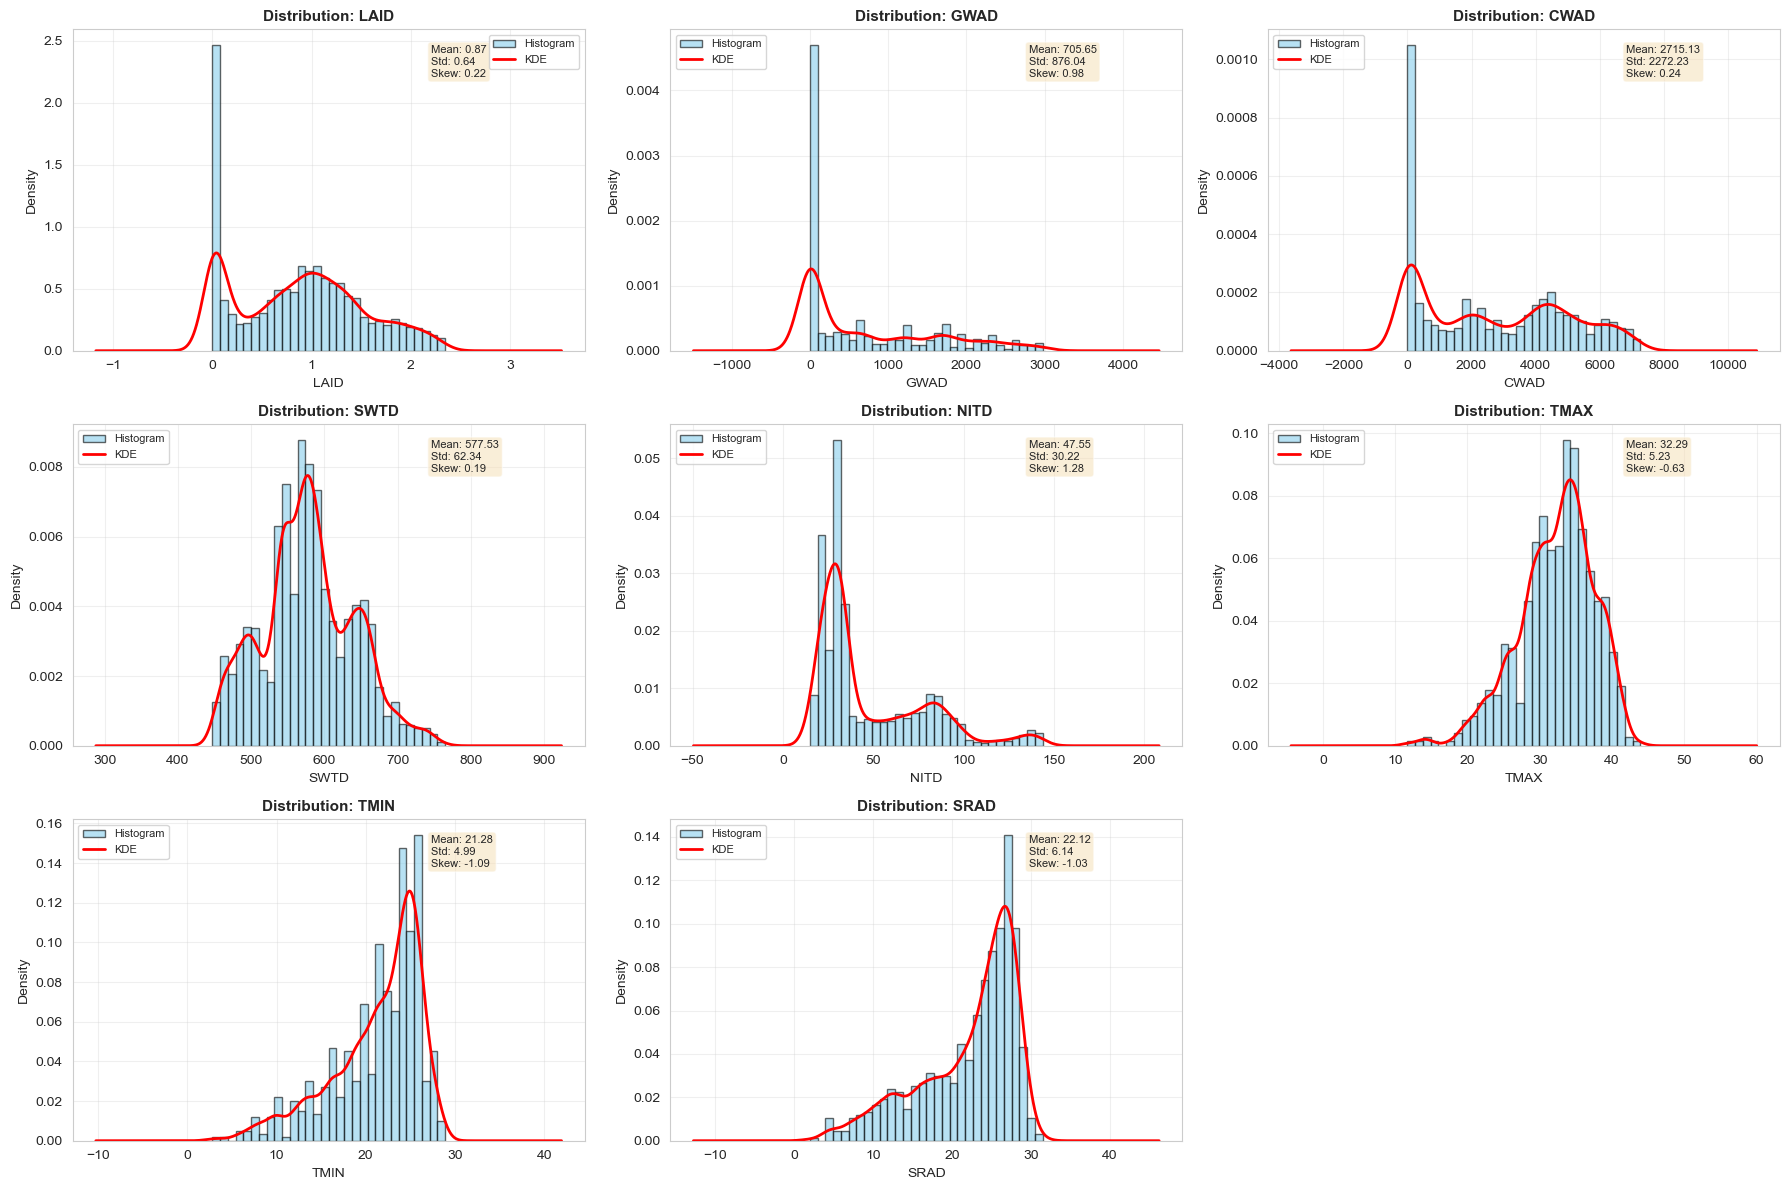


 Skewness Analysis:


,Feature,Skewness
4,NITD,1.280676
6,TMIN,-1.094564
7,SRAD,-1.032017
1,GWAD,0.981354
5,TMAX,-0.630923
2,CWAD,0.243219
0,LAID,0.221569
3,SWTD,0.189885



 Highly skewed features (|skew| > 1): 3
Recommendation: Consider log/sqrt transformation for these features
4.2 FEATURE DISTRIBUTIONS BY GROWTH STAGE

--- How key features vary across growth stages ---


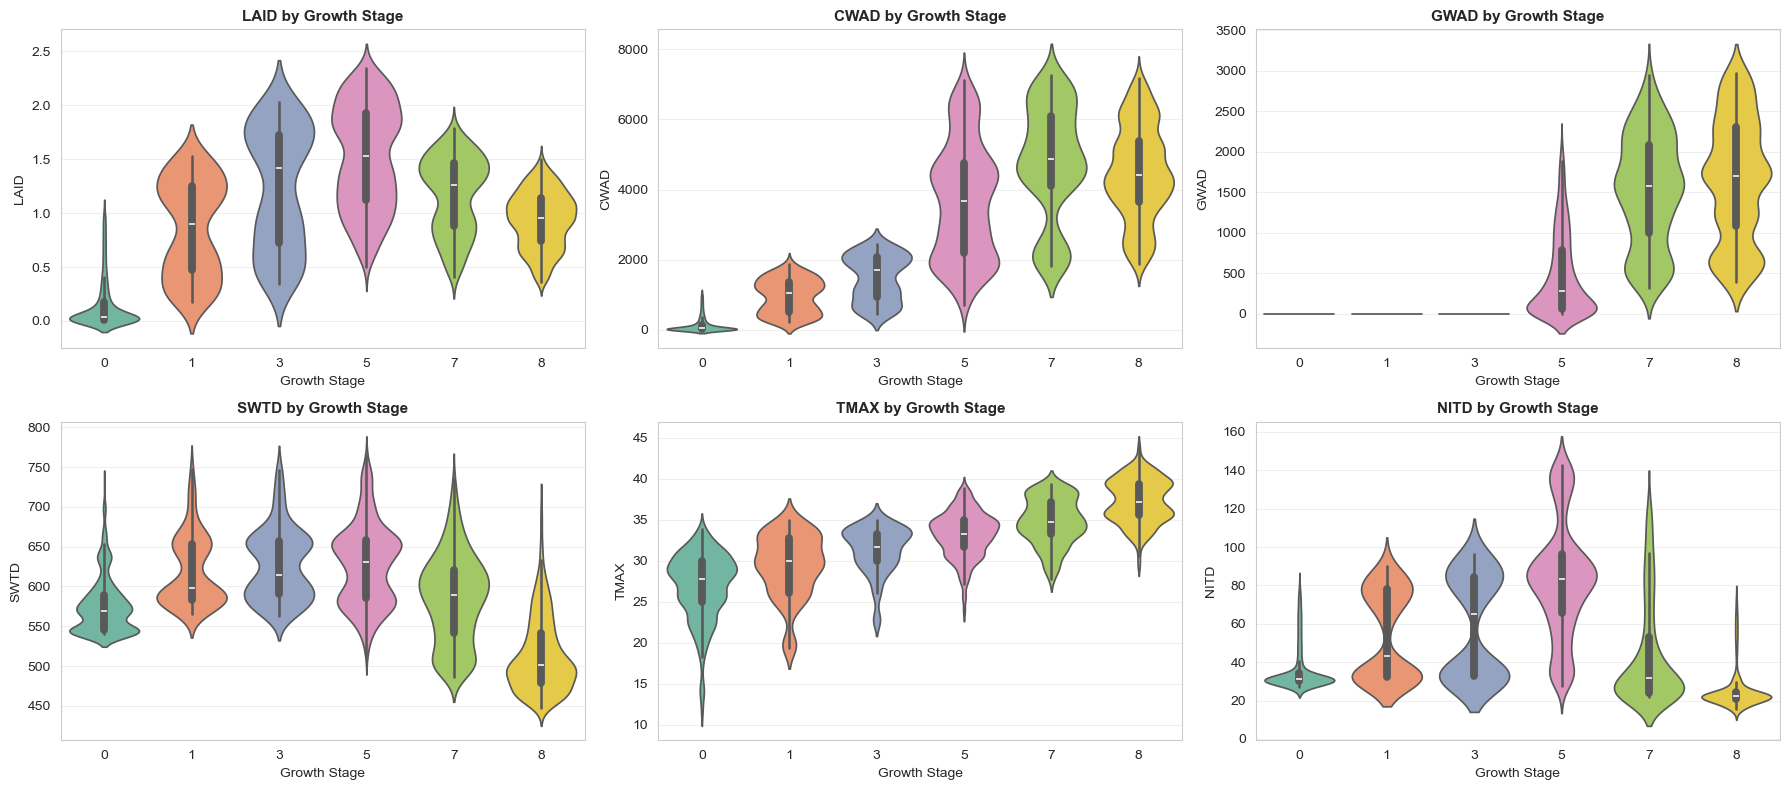


--- 4.3.1 Treatment Performance Comparison ---

 Treatment Performance Rankings:


,Max_Stage,Total_Days,Max_Grain,Max_Biomass,Max_LAI,Grain_per_Day,Stage_Rank,Grain_Rank,Overall_Rank
TRTNA,,,,,,,,,
CRGRO048,8,137,2974,7264,2.35,21.708,1.0,1.0,1.0


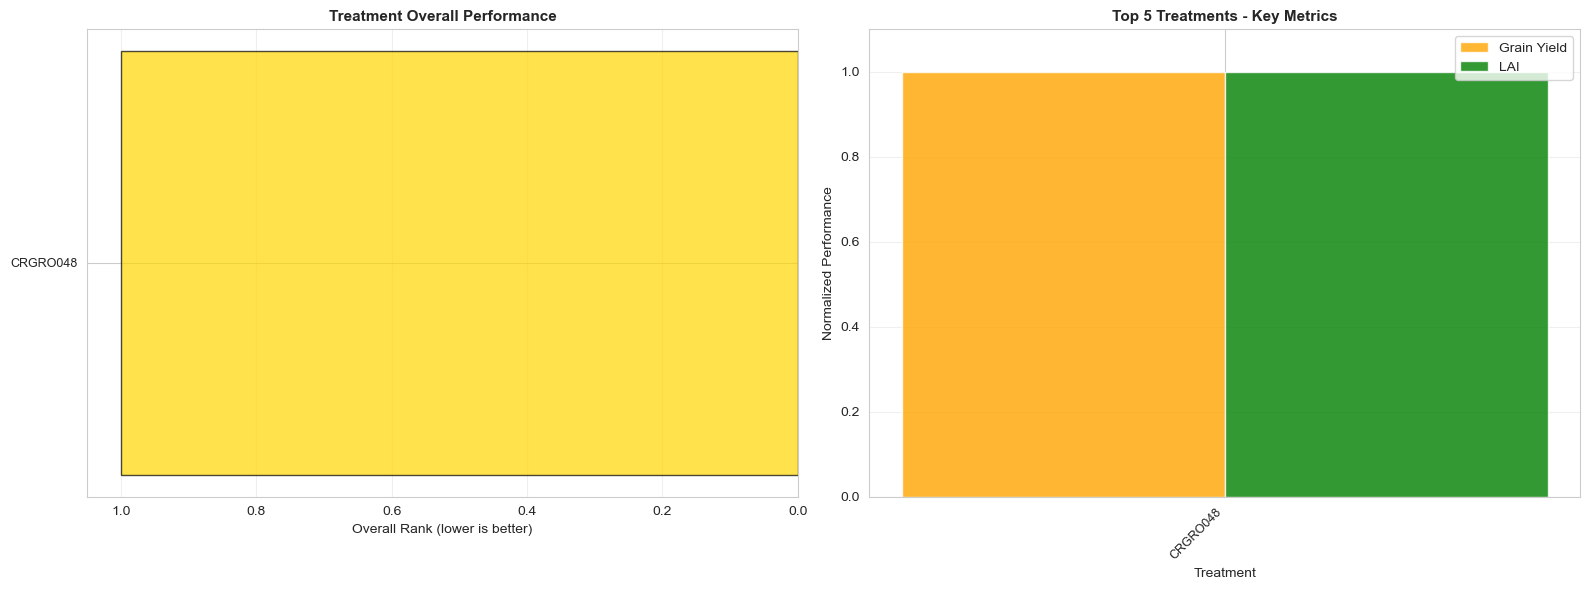


 Key Insights:
Best treatment: CRGRO048 (Rank: 1.0)
Worst treatment: CRGRO048 (Rank: 1.0)
 Grain yield improvement (best vs worst): 0.0%

--- 4.3.2 Treatment Effects on Growth Indicators ---
Treatment comparison skipped: only 1 unique treatment(s) found. Need at least 2.

--- 4.3.3 Statistical Significance of Treatment Effects ---
ANOVA skipped: only 1 unique treatment(s) found. Need at least 2.


In [8]:
# SECTION 4: FEATURE DISTRIBUTIONS & TREATMENT EFFECTS

print("SECTION 4: FEATURE DISTRIBUTIONS & TREATMENT EFFECTS")

# 4.1 UNIVARIATE DISTRIBUTIONS - KEY FEATURES

print("4.1 UNIVARIATE DISTRIBUTIONS - KEY FEATURES")

key_features = ['LAID', 'GWAD', 'CWAD', 'SWTD', 'NITD', 'TMAX', 'TMIN', 'SRAD']
existing_features = [col for col in key_features if col in df.columns]

if existing_features:
    print(f"\n--- Distribution Analysis for {len(existing_features)} Key Features ---")

    # Create subplots for distributions
    n_features = len(existing_features)
    n_cols = 3
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    axes = axes.flatten() if n_features > 1 else [axes]

    skewness_data = []

    for idx, feature in enumerate(existing_features):
        # Histogram with KDE
        axes[idx].hist(df[feature].dropna(), bins=30, alpha=0.6,
                      color='skyblue', edgecolor='black', density=True, label='Histogram')

        # Add KDE line
        df[feature].dropna().plot(kind='kde', ax=axes[idx], color='red',
                                  linewidth=2, label='KDE')

        axes[idx].set_xlabel(feature, fontsize=10)
        axes[idx].set_ylabel('Density', fontsize=10)
        axes[idx].set_title(f'Distribution: {feature}', fontsize=11, fontweight='bold')
        axes[idx].legend(fontsize=8)
        axes[idx].grid(alpha=0.3)

        # Calculate and store skewness
        skew_val = df[feature].skew()
        skewness_data.append({'Feature': feature, 'Skewness': skew_val})

        # Add statistics text
        stats_text = f"Mean: {df[feature].mean():.2f}\nStd: {df[feature].std():.2f}\nSkew: {skew_val:.2f}"
        axes[idx].text(0.70, 0.95, stats_text, transform=axes[idx].transAxes,
                      fontsize=8, verticalalignment='top',
                      bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    # Hide unused subplots
    for idx in range(len(existing_features), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

    # Skewness summary
    skewness_df = pd.DataFrame(skewness_data).sort_values('Skewness', key=abs, ascending=False)

    print("\n Skewness Analysis:")
    display(skewness_df)

    highly_skewed = skewness_df[abs(skewness_df['Skewness']) > 1]
    if len(highly_skewed) > 0:
        print(f"\n Highly skewed features (|skew| > 1): {len(highly_skewed)}")
        print("Recommendation: Consider log/sqrt transformation for these features")
    else:
        print("\n No highly skewed features detected")

# 4.2 FEATURE DISTRIBUTIONS BY GROWTH STAGE

print("4.2 FEATURE DISTRIBUTIONS BY GROWTH STAGE")

if 'GSTD' in df.columns:
    # Select most important features for stage comparison
    stage_features = ['LAID', 'CWAD', 'GWAD', 'SWTD', 'TMAX', 'NITD']
    stage_features = [f for f in stage_features if f in df.columns]

    if stage_features:
        print("\n--- How key features vary across growth stages ---")

        n_features = len(stage_features)
        n_cols = 3
        n_rows = (n_features + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
        axes = axes.flatten() if n_features > 1 else [axes]

        for idx, feature in enumerate(stage_features):
            # Violin plot (shows distribution better than box plot)
            sns.violinplot(data=df, x='GSTD', y=feature, hue='GSTD', ax=axes[idx], palette='Set2', legend=False)
            axes[idx].set_xlabel('Growth Stage', fontsize=10)
            axes[idx].set_ylabel(feature, fontsize=10)
            axes[idx].set_title(f'{feature} by Growth Stage', fontsize=11, fontweight='bold')
            axes[idx].grid(axis='y', alpha=0.3)

        # Hide unused subplots
        for idx in range(len(stage_features), len(axes)):
            axes[idx].axis('off')

        plt.tight_layout()
        plt.show()

# 4.3 TREATMENT EFFECTS ANALYSIS

if 'TRTNO' in df.columns and 'TRTNA' in df.columns:

    # 4.3.1 Treatment Performance Metrics

    print("\n--- 4.3.1 Treatment Performance Comparison ---")

    if 'GSTD' in df.columns and 'DAP' in df.columns:
        # Calculate comprehensive performance metrics
        performance_metrics = df.groupby('TRTNA').agg({
            'GSTD': 'max',
            'DAP': 'max',
            'GWAD': 'max' if 'GWAD' in df.columns else 'count',
            'CWAD': 'max' if 'CWAD' in df.columns else 'count',
            'LAID': 'max' if 'LAID' in df.columns else 'count'
        }).round(2)

        performance_metrics.columns = ['Max_Stage', 'Total_Days', 'Max_Grain', 'Max_Biomass', 'Max_LAI']

        # Calculate efficiency metrics
        if 'GWAD' in df.columns:
            performance_metrics['Grain_per_Day'] = (performance_metrics['Max_Grain'] / performance_metrics['Total_Days']).round(3)

        # Ranking
        performance_metrics['Stage_Rank'] = performance_metrics['Max_Stage'].rank(ascending=False)
        if 'GWAD' in df.columns:
            performance_metrics['Grain_Rank'] = performance_metrics['Max_Grain'].rank(ascending=False)
            performance_metrics['Overall_Rank'] = ((performance_metrics['Stage_Rank'] + performance_metrics['Grain_Rank']) / 2).round(1)
        else:
            performance_metrics['Overall_Rank'] = performance_metrics['Stage_Rank']

        performance_metrics = performance_metrics.sort_values('Overall_Rank')

        print("\n Treatment Performance Rankings:")
        display(performance_metrics)

        # Visualize top performers
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        # Overall ranking
        axes[0].barh(range(len(performance_metrics)),
                    performance_metrics['Overall_Rank'].values,
                    color='gold', alpha=0.7, edgecolor='black')
        axes[0].set_yticks(range(len(performance_metrics)))
        axes[0].set_yticklabels(performance_metrics.index, fontsize=9)
        axes[0].set_xlabel('Overall Rank (lower is better)', fontsize=10)
        axes[0].set_title('Treatment Overall Performance', fontsize=11, fontweight='bold')
        axes[0].invert_yaxis()
        axes[0].invert_xaxis()
        axes[0].grid(axis='x', alpha=0.3)

        # Key metrics comparison
        if 'GWAD' in df.columns and 'LAID' in df.columns:
            top_5 = performance_metrics.head(5)

            x = np.arange(len(top_5))
            width = 0.35

            # Normalize for comparison
            grain_norm = top_5['Max_Grain'] / top_5['Max_Grain'].max()
            lai_norm = top_5['Max_LAI'] / top_5['Max_LAI'].max()

            axes[1].bar(x - width/2, grain_norm, width, label='Grain Yield', alpha=0.8, color='orange')
            axes[1].bar(x + width/2, lai_norm, width, label='LAI', alpha=0.8, color='green')

            axes[1].set_xlabel('Treatment', fontsize=10)
            axes[1].set_ylabel('Normalized Performance', fontsize=10)
            axes[1].set_title('Top 5 Treatments - Key Metrics', fontsize=11, fontweight='bold')
            axes[1].set_xticks(x)
            axes[1].set_xticklabels(top_5.index, rotation=45, ha='right', fontsize=9)
            axes[1].legend()
            axes[1].grid(axis='y', alpha=0.3)
            axes[1].set_ylim([0, 1.1])

        plt.tight_layout()
        plt.show()

        # Insights
        best = performance_metrics.index[0]
        worst = performance_metrics.index[-1]

        print(f"\n Key Insights:")
        print(f"Best treatment: {best} (Rank: {performance_metrics['Overall_Rank'].iloc[0]:.1f})")
        print(f"Worst treatment: {worst} (Rank: {performance_metrics['Overall_Rank'].iloc[-1]:.1f})")

        if 'GWAD' in df.columns:
            grain_improvement = ((performance_metrics.loc[best, 'Max_Grain'] - performance_metrics.loc[worst, 'Max_Grain']) / performance_metrics.loc[worst, 'Max_Grain'] * 100)
            print(f" Grain yield improvement (best vs worst): {grain_improvement:.1f}%")

    # 4.3.2 Treatment Effects on Growth Indicators

print("\n--- 4.3.2 Treatment Effects on Growth Indicators ---")

growth_vars = ['LAID', 'GWAD', 'CWAD', 'GSTD']
growth_vars = [v for v in growth_vars if v in df.columns]

n_treatments = df['TRTNA'].nunique() if 'TRTNA' in df.columns else 0

if growth_vars and n_treatments > 1:
    treatment_means = df.groupby('TRTNA')[growth_vars].mean().round(2)

    print("\nMean values by treatment:")
    display(treatment_means)

    fig, ax = plt.subplots(figsize=(12, 8))

    std_vals = treatment_means.std().replace(0, np.nan)
    treatment_normalized = (treatment_means - treatment_means.mean()) / std_vals
    treatment_normalized = treatment_normalized.dropna(axis=0, how='all').dropna(axis=1, how='all')

    if not treatment_normalized.empty:
        aligned_means = treatment_means.loc[treatment_normalized.index, treatment_normalized.columns]

        sns.heatmap(
            treatment_normalized.T,
            annot=aligned_means.T.values,
            fmt='.1f',
            cmap='RdYlGn',
            center=0,
            xticklabels=aligned_means.index,
            yticklabels=aligned_means.columns,
            cbar_kws={'label': 'Std Deviations from Mean'},
            ax=ax,
            linewidths=0.5
        )

        ax.set_title('Treatment Effects Heatmap\n(values = actual means, colors = normalized)',
                     fontsize=12, fontweight='bold')
        ax.set_xlabel('Treatment', fontsize=11)
        ax.set_ylabel('Growth Indicator', fontsize=11)

        plt.tight_layout()
        plt.show()
    else:
        print("Heatmap skipped: normalized treatment matrix is empty or all NaN.")
else:
    print(f"Treatment comparison skipped: only {n_treatments} unique treatment(s) found. Need at least 2.")

    # 4.3.3 Statistical Significance Testing

print("\n--- 4.3.3 Statistical Significance of Treatment Effects ---")

from scipy import stats

n_treatments = df['TRTNA'].nunique() if 'TRTNA' in df.columns else 0
test_vars = ['GWAD', 'LAID', 'CWAD', 'GSTD']
test_vars = [v for v in test_vars if v in df.columns]

if n_treatments > 1 and test_vars:
    anova_results = []

    for var in test_vars:
        groups = [group[var].dropna().values for _, group in df.groupby('TRTNA')]
        groups = [g for g in groups if len(g) > 0]

        if len(groups) > 1:
            f_stat, p_value = stats.f_oneway(*groups)

            anova_results.append({
                'Variable': var,
                'F_statistic': round(f_stat, 4),
                'P_value': round(p_value, 6),
                'Significant_at_0.05': 'Yes' if p_value < 0.05 else 'No'
            })

    if anova_results:
        anova_df = pd.DataFrame(anova_results)

        print("\nANOVA Test Results - Treatment Effects:")
        display(anova_df)

        significant_count = sum(r['Significant_at_0.05'] == 'Yes' for r in anova_results)
        print(f"\n{significant_count}/{len(anova_results)} variables show statistically significant treatment effects (p < 0.05)")
    else:
        print("ANOVA skipped: not enough non-missing data across treatment groups.")
else:
    print(f"ANOVA skipped: only {n_treatments} unique treatment(s) found. Need at least 2.")

In [9]:
print(df['TRTNA'].nunique())
print(df['TRTNA'].value_counts(dropna=False))

1
TRTNA
CRGRO048    5520
Name: count, dtype: int64


SECTION 5: MULTIVARIATE PATTERNS & ADVANCED ANALYSIS
5.1 ENVIRONMENTAL INTERACTION EFFECTS

Mean values by Temperature x Water interaction:


GSTD  LAID     CWAD
TMAX_bin  SWTD_bin                       
Low_Temp  Low_Water   0.20  0.05   160.13
          Med_Water   0.78  0.34   618.31
          High_Water  2.36  0.97  1786.99
Med_Temp  Low_Water   6.21  0.83  4063.48
          Med_Water   4.13  1.05  3063.51
          High_Water  5.05  1.44  4067.89
High_Temp Low_Water   7.74  0.86  3723.33
          Med_Water   6.48  1.12  3868.52
          High_Water  6.08  1.50  5017.94

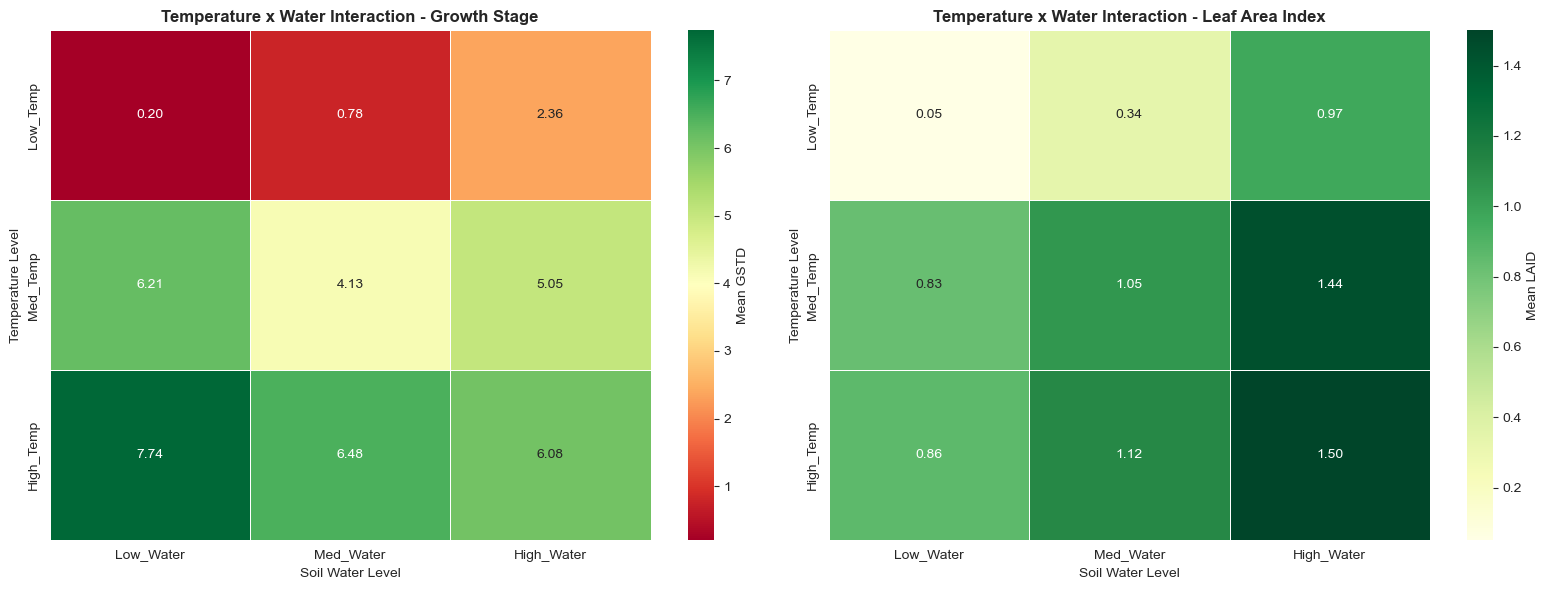


VPD vs LAI scatter skipped: VPD has no meaningful variation in the current dataset.
5.2 NUTRIENT x WATER INTERACTION

Mean Biomass (CWAD) by Nitrogen x Water levels:


SWTD_bin,Low_W,Med_W,High_W
NITD_bin,,,
Low_N,3296.53,4286.99,5784.37
Med_N,958.31,775.66,2057.52
High_N,2542.54,2623.97,3571.82


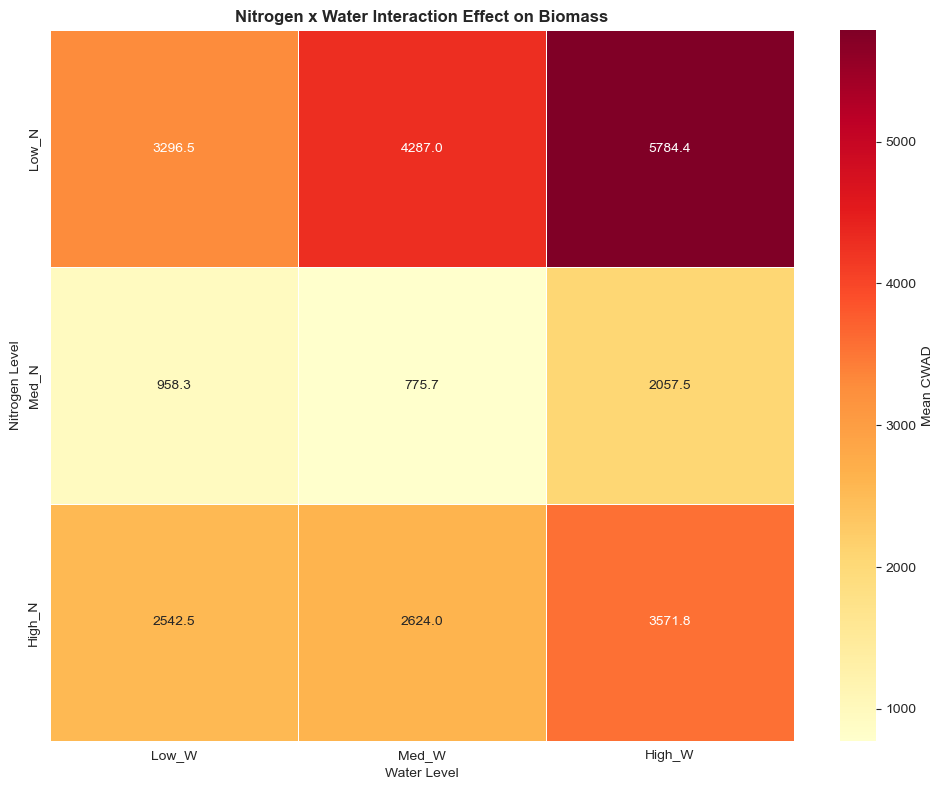

5.3 CLUSTERING ANALYSIS - PLANT BEHAVIOR GROUPS

Unique RUNNO groups available for clustering: 40


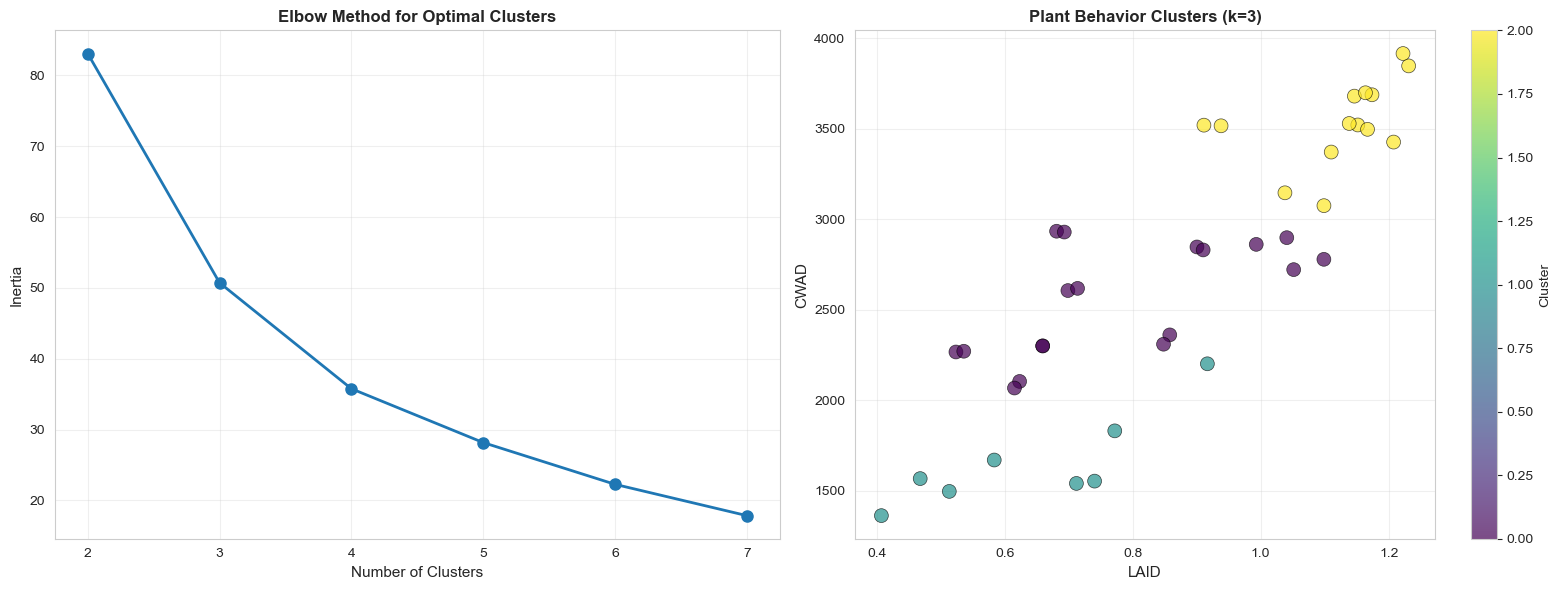


Cluster characteristics (k=3):


,LAID,CWAD,SWTD,TMAX
Cluster,,,,
0,0.78,2554.49,581.12,31.96
1,0.64,1651.42,528.54,34.89
2,1.12,3529.49,600.92,31.23



Cluster sizes:


Cluster
0    18
1     8
2    14
Name: count, dtype: int64

5.4 PRINCIPAL COMPONENT ANALYSIS - DIMENSIONALITY REDUCTION


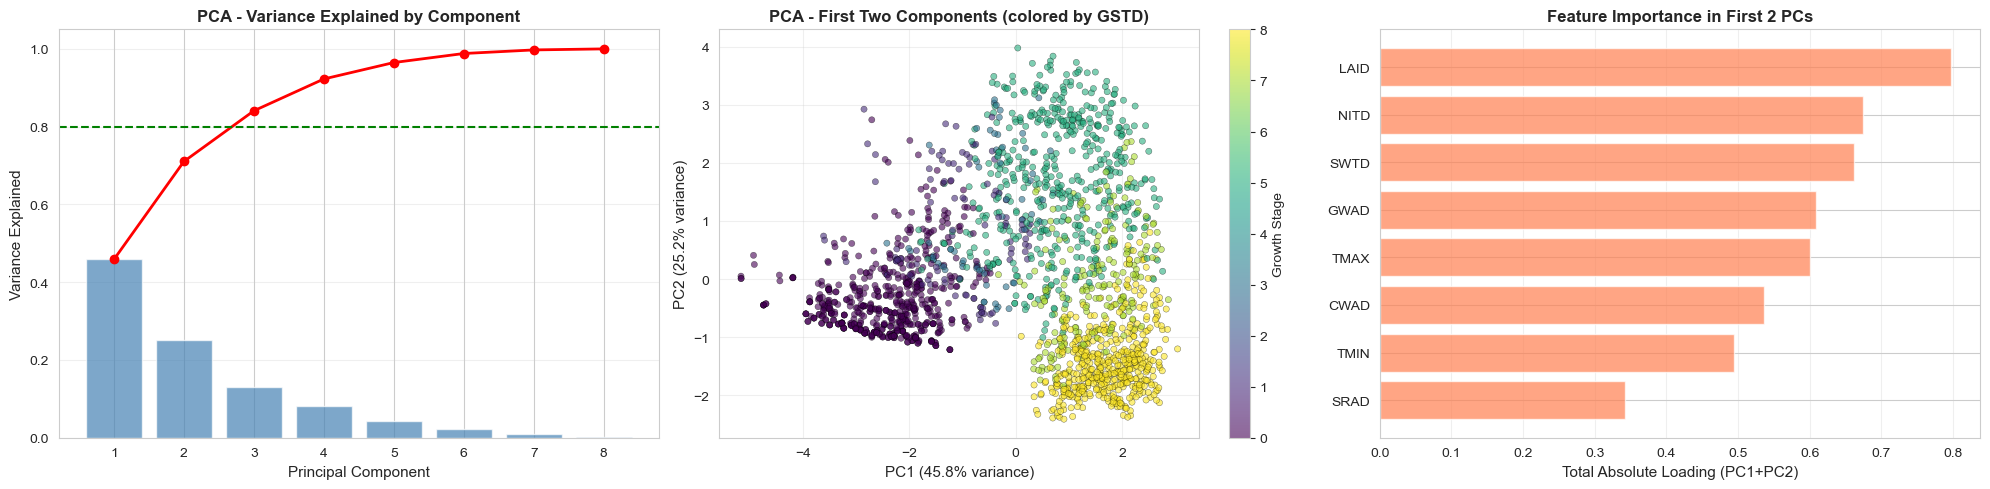


PCA Summary:
Number of components for 80% variance: 3
Total features: 8
Dimensionality reduction: 8 -> 3 (62.5% reduction)


In [10]:
# SECTION 5: MULTIVARIATE PATTERNS & ADVANCED ANALYSIS

print("SECTION 5: MULTIVARIATE PATTERNS & ADVANCED ANALYSIS")

import os
os.environ["OMP_NUM_THREADS"] = "1"

# 5.1 ENVIRONMENTAL INTERACTIONS
print("5.1 ENVIRONMENTAL INTERACTION EFFECTS")

if all(col in df.columns for col in ['TMAX', 'SWTD', 'GSTD']):

    df_temp = df.copy()

    # Safer qcut
    df_temp = df_temp.dropna(subset=['TMAX', 'SWTD', 'GSTD'])
    df_temp['TMAX_bin'] = pd.qcut(
        df_temp['TMAX'], q=3,
        labels=['Low_Temp', 'Med_Temp', 'High_Temp'],
        duplicates='drop'
    )
    df_temp['SWTD_bin'] = pd.qcut(
        df_temp['SWTD'], q=3,
        labels=['Low_Water', 'Med_Water', 'High_Water'],
        duplicates='drop'
    )

    interaction_table = df_temp.groupby(['TMAX_bin', 'SWTD_bin'], observed=False).agg({
        'GSTD': 'mean',
        'LAID': 'mean' if 'LAID' in df.columns else 'count',
        'CWAD': 'mean' if 'CWAD' in df.columns else 'count'
    }).round(2)

    print("\nMean values by Temperature x Water interaction:")
    display(interaction_table)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    pivot_gstd = interaction_table['GSTD'].unstack()
    sns.heatmap(
        pivot_gstd, annot=True, fmt='.2f', cmap='RdYlGn', ax=axes[0],
        cbar_kws={'label': 'Mean GSTD'}, linewidths=0.5
    )
    axes[0].set_title('Temperature x Water Interaction - Growth Stage', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Soil Water Level')
    axes[0].set_ylabel('Temperature Level')

    if 'LAID' in df.columns:
        pivot_lai = interaction_table['LAID'].unstack()
        sns.heatmap(
            pivot_lai, annot=True, fmt='.2f', cmap='YlGn', ax=axes[1],
            cbar_kws={'label': 'Mean LAID'}, linewidths=0.5
        )
        axes[1].set_title('Temperature x Water Interaction - Leaf Area Index', fontsize=12, fontweight='bold')
        axes[1].set_xlabel('Soil Water Level')
        axes[1].set_ylabel('Temperature Level')
    else:
        axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# VPD scatter only if VPD has variation
if all(col in df.columns for col in ['VPD', 'TMAX', 'LAID']):
    vpd_non_null = df['VPD'].dropna()

    if vpd_non_null.nunique() > 1:
        fig, ax = plt.subplots(figsize=(12, 6))

        scatter = ax.scatter(
            df['VPD'], df['LAID'], c=df['TMAX'],
            cmap='coolwarm', alpha=0.5, s=30, edgecolors='k', linewidth=0.3
        )

        ax.set_xlabel('VPD (Vapor Pressure Deficit)', fontsize=11)
        ax.set_ylabel('LAID (Leaf Area Index)', fontsize=11)
        ax.set_title('VPD vs LAI (colored by Temperature)', fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)

        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label('Temperature (TMAX)', fontsize=10)

        plt.tight_layout()
        plt.show()
    else:
        print("\nVPD vs LAI scatter skipped: VPD has no meaningful variation in the current dataset.")

# 5.2 NUTRIENT x WATER AVAILABILITY
print("5.2 NUTRIENT x WATER INTERACTION")

if all(col in df.columns for col in ['NITD', 'SWTD', 'CWAD']):

    df_temp = df.copy()
    df_temp = df_temp.dropna(subset=['NITD', 'SWTD', 'CWAD'])

    df_temp['NITD_bin'] = pd.qcut(
        df_temp['NITD'], q=3,
        labels=['Low_N', 'Med_N', 'High_N'],
        duplicates='drop'
    )
    df_temp['SWTD_bin'] = pd.qcut(
        df_temp['SWTD'], q=3,
        labels=['Low_W', 'Med_W', 'High_W'],
        duplicates='drop'
    )

    nutrient_water = df_temp.groupby(['NITD_bin', 'SWTD_bin'], observed=False)['CWAD'].mean().unstack()

    print("\nMean Biomass (CWAD) by Nitrogen x Water levels:")
    display(nutrient_water.round(2))

    fig, ax = plt.subplots(figsize=(10, 8))

    sns.heatmap(
        nutrient_water, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
        cbar_kws={'label': 'Mean CWAD'}, linewidths=0.5
    )
    ax.set_title('Nitrogen x Water Interaction Effect on Biomass', fontsize=12, fontweight='bold')
    ax.set_xlabel('Water Level')
    ax.set_ylabel('Nitrogen Level')

    plt.tight_layout()
    plt.show()

# 5.3 CLUSTERING ANALYSIS - IDENTIFYING PLANT GROUPS
print("5.3 CLUSTERING ANALYSIS - PLANT BEHAVIOR GROUPS")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_features = ['LAID', 'CWAD', 'SWTD', 'TMAX']
cluster_features = [f for f in cluster_features if f in df.columns]

if len(cluster_features) >= 3 and 'RUNNO' in df.columns:

    run_aggregates = df.groupby('RUNNO')[cluster_features].mean().dropna()
    n_runs = len(run_aggregates)

    print(f"\nUnique RUNNO groups available for clustering: {n_runs}")

    if n_runs >= 3:
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(run_aggregates)

        max_k = min(7, n_runs)
        K_range = range(2, max_k + 1)
        inertias = []

        for k in K_range:
            kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
            kmeans.fit(features_scaled)
            inertias.append(kmeans.inertia_)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        axes[0].plot(K_range, inertias, marker='o', linewidth=2, markersize=8)
        axes[0].set_xlabel('Number of Clusters', fontsize=11)
        axes[0].set_ylabel('Inertia', fontsize=11)
        axes[0].set_title('Elbow Method for Optimal Clusters', fontsize=12, fontweight='bold')
        axes[0].grid(alpha=0.3)

        optimal_k = min(3, n_runs)
        kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(features_scaled)
        run_aggregates['Cluster'] = clusters

        scatter = axes[1].scatter(
            run_aggregates[cluster_features[0]],
            run_aggregates[cluster_features[1]],
            c=clusters, cmap='viridis', s=100,
            alpha=0.7, edgecolors='k', linewidth=0.5
        )

        axes[1].set_xlabel(cluster_features[0], fontsize=11)
        axes[1].set_ylabel(cluster_features[1], fontsize=11)
        axes[1].set_title(f'Plant Behavior Clusters (k={optimal_k})', fontsize=12, fontweight='bold')
        axes[1].grid(alpha=0.3)

        cbar = plt.colorbar(scatter, ax=axes[1])
        cbar.set_label('Cluster', fontsize=10)

        plt.tight_layout()
        plt.show()

        print(f"\nCluster characteristics (k={optimal_k}):")
        cluster_summary = run_aggregates.groupby('Cluster')[cluster_features].mean()
        display(cluster_summary.round(2))

        cluster_sizes = run_aggregates['Cluster'].value_counts().sort_index()
        print("\nCluster sizes:")
        display(cluster_sizes)
    else:
        print("Clustering skipped: need at least 3 RUNNO groups for meaningful clustering.")

# 5.4 PRINCIPAL COMPONENT ANALYSIS
print("5.4 PRINCIPAL COMPONENT ANALYSIS - DIMENSIONALITY REDUCTION")

from sklearn.decomposition import PCA

pca_features = ['LAID', 'GWAD', 'CWAD', 'SWTD', 'NITD', 'TMAX', 'TMIN', 'SRAD']
pca_features = [f for f in pca_features if f in df.columns]

if len(pca_features) >= 4:

    df_pca = df[pca_features + ['GSTD']].dropna()

    if len(df_pca) > 1:
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(df_pca[pca_features])

        pca = PCA()
        pca_result = pca.fit_transform(features_scaled)

        explained_var = pca.explained_variance_ratio_
        cumsum_var = np.cumsum(explained_var)

        fig, axes = plt.subplots(1, 3, figsize=(20, 5))

        axes[0].bar(range(1, len(explained_var) + 1), explained_var, alpha=0.7, color='steelblue')
        axes[0].plot(range(1, len(explained_var) + 1), cumsum_var, 'r-o', linewidth=2, markersize=6)
        axes[0].axhline(y=0.8, color='green', linestyle='--', linewidth=1.5)
        axes[0].set_xlabel('Principal Component', fontsize=11)
        axes[0].set_ylabel('Variance Explained', fontsize=11)
        axes[0].set_title('PCA - Variance Explained by Component', fontsize=12, fontweight='bold')
        axes[0].grid(axis='y', alpha=0.3)

        sample_size = min(2000, len(df_pca))
        sample_indices = np.random.choice(len(df_pca), sample_size, replace=False)

        scatter = axes[1].scatter(
            pca_result[sample_indices, 0], pca_result[sample_indices, 1],
            c=df_pca['GSTD'].iloc[sample_indices], cmap='viridis',
            alpha=0.6, s=20, edgecolors='k', linewidth=0.3
        )
        axes[1].set_xlabel(f'PC1 ({explained_var[0]*100:.1f}% variance)', fontsize=11)
        axes[1].set_ylabel(f'PC2 ({explained_var[1]*100:.1f}% variance)', fontsize=11)
        axes[1].set_title('PCA - First Two Components (colored by GSTD)', fontsize=12, fontweight='bold')
        axes[1].grid(alpha=0.3)

        cbar = plt.colorbar(scatter, ax=axes[1])
        cbar.set_label('Growth Stage', fontsize=10)

        loadings = pca.components_[:2, :].T
        feature_importance = np.abs(loadings).sum(axis=1)
        feature_importance_df = pd.DataFrame({
            'Feature': pca_features,
            'Importance': feature_importance
        }).sort_values('Importance', ascending=True)

        axes[2].barh(
            feature_importance_df['Feature'],
            feature_importance_df['Importance'],
            color='coral', alpha=0.7
        )
        axes[2].set_xlabel('Total Absolute Loading (PC1+PC2)', fontsize=11)
        axes[2].set_title('Feature Importance in First 2 PCs', fontsize=12, fontweight='bold')
        axes[2].grid(axis='x', alpha=0.3)

        plt.tight_layout()
        plt.show()

        n_components_80 = np.argmax(cumsum_var >= 0.8) + 1
        print(f"\nPCA Summary:")
        print(f"Number of components for 80% variance: {n_components_80}")
        print(f"Total features: {len(pca_features)}")
        print(f"Dimensionality reduction: {len(pca_features)} -> {n_components_80} ({(1 - n_components_80/len(pca_features))*100:.1f}% reduction)")

In [11]:
print(f"{df['RUNNO'].nunique()} runs | {df['TRTNO'].nunique()} treatments")

40 runs | 8 treatments


In [14]:
# ============================================================
# OPTIONAL SETUP: INSTALL LIGHTGBM IF NEEDED
# ============================================================

import sys

try:
    import lightgbm as lgb
    print("LightGBM is already installed.")
except ImportError:
    print("LightGBM is not installed in this environment. Installing now...")
    !{sys.executable} -m pip install lightgbm


   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 1.5/1.5 MB 35.1 MB/s  0:00:00


In [15]:
import sys, site
print("python:", sys.executable)
print("site-packages:", site.getsitepackages())
!{sys.executable} -m pip show lightgbm

python: C:\Users\Jacob\anaconda3\python.exe
site-packages: ['C:\\Users\\Jacob\\anaconda3', 'C:\\Users\\Jacob\\anaconda3\\Lib\\site-packages']
Name: lightgbm
Version: 4.6.0
Summary: LightGBM Python-package
Home-page: https://github.com/microsoft/LightGBM
Author: 
Author-email: 
License: The MIT License (MIT)

Copyright (c) Microsoft Corporation

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDI

SECTION 7: BASELINE LIGHTGBM MODEL

7.1 PREPARING DATA
Dataset shape after creating target: (5480, 47)
Target distribution (GSTD_Next):
GSTD_Next
0    1655
1     248
3     193
5    1372
7     600
8    1412
Name: count, dtype: int64

7.2 DEFINING BASELINE FEATURES
Baseline features (37):
['TRTNO', 'DAP', 'LAID', 'GSTD', 'GWAD', 'CWAD', 'NIAD', 'NITD', 'NI1D', 'NI2D', 'NI3D', 'NI4D', 'NI5D', 'NI6D', 'NI7D', 'NI8D', 'NI9D', 'SWTD', 'SWXD', 'SW1D', 'SW2D', 'SW3D', 'SW4D', 'SW5D', 'SW6D', 'SW7D', 'SW8D', 'SW9D', 'SW10D', 'SRAD', 'PARD', 'TMAX', 'TMIN', 'VPD', 'TGRD', 'TRTNO_WX', 'LAI']

7.3 TRAIN/TEST SPLIT BY RUNNO
Total runs:  40
Train runs:  32 | Rows: 4384
Test runs:   8  | Rows: 1096

7.4 TRAINING LIGHTGBM BASELINE
Training until validation scores don't improve for 50 rounds
[100]	train's multi_logloss: 0.0012251	val's multi_logloss: 0.00764974
[200]	train's multi_logloss: 8.44311e-06	val's multi_logloss: 0.00444556
Early stopping, best iteration is:
[225]	train's multi_logloss: 4.9938

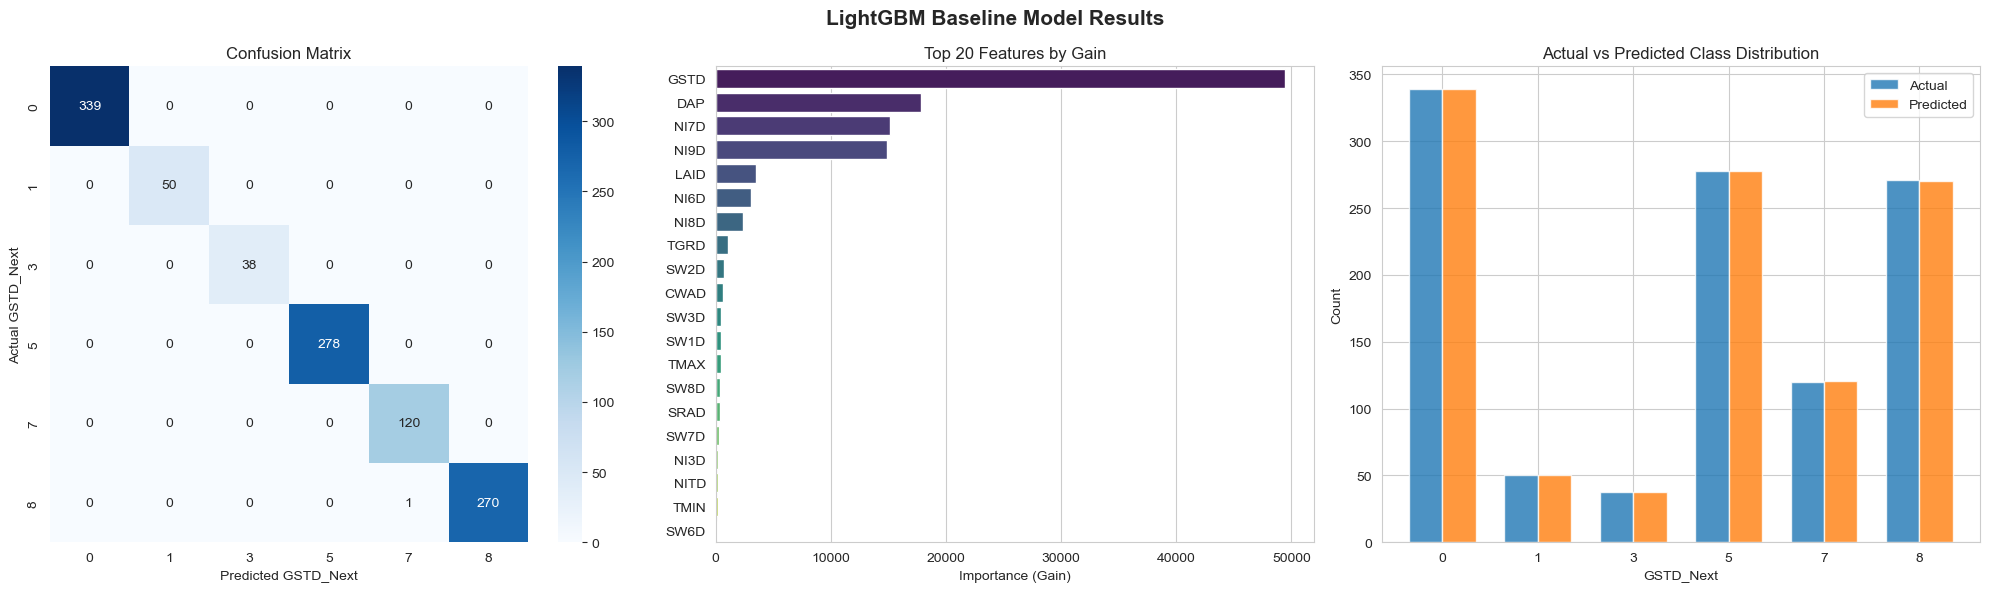


Top 10 features by gain:
Feature  Importance_Gain  Importance_Split
   GSTD     49480.195099              2189
    DAP     17811.543483              4460
   NI7D     15157.209071               832
   NI9D     14880.929214              2327
   LAID      3480.309189              1316
   NI6D      3067.851133               729
   NI8D      2345.112299              1141
   TGRD      1108.605627              1343
   SW2D       710.427045              1455
   CWAD       600.669637              1176

BASELINE LIGHTGBM MODEL COMPLETE
  Accuracy:      99.91%
  F1 (macro):    0.9990
  F1 (weighted): 0.9991


In [16]:
# ============================================================
# SECTION 7: BASELINE LIGHTGBM MODEL
# Predict the next GSTD value with a run-safe split.
# This was part of the early modeling exploration.
# Features use the original columns only, without engineered time-series variables.
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("SECTION 7: BASELINE LIGHTGBM MODEL")
print("=" * 60)

# 7.1 PREPARE DATA
print("\n7.1 PREPARING DATA")

df_model = df.copy()
df_model = df_model.sort_values(['RUNNO', 'DAP']).reset_index(drop=True)

# Create target: next day's GSTD
df_model['GSTD_Next'] = df_model.groupby('RUNNO')['GSTD'].shift(-1)

# Drop last row of each run (no next stage available)
df_model = df_model.dropna(subset=['GSTD_Next'])
df_model['GSTD_Next'] = df_model['GSTD_Next'].astype(int)

print(f"Dataset shape after creating target: {df_model.shape}")
print(f"Target distribution (GSTD_Next):\n{df_model['GSTD_Next'].value_counts().sort_index()}")

# 7.2 DEFINE FEATURES
print("\n7.2 DEFINING BASELINE FEATURES")

drop_cols = [
    'GSTD_Next',      # target
    'TRTNA',          # text version of TRTNO (redundant)
    'TRTNA_x',        # all nulls
    'TRTNA_y',        # all nulls
    'TRTNA_WX',       # all nulls
    'TRTNO_x',        # duplicate of TRTNO
    'TRTNO_y',        # duplicate of TRTNO
    'WDATE',          # date identifier
    'DOY',            # redundant with DAP
    'RUNNO',          # identifier — used for splitting only
]

# Drop only columns that actually exist (prevents KeyError across versions)
drop_cols = [c for c in drop_cols if c in df_model.columns]

feature_cols = [col for col in df_model.columns if col not in drop_cols]

# Handle missing values — forward fill then backfill within each run
df_model[feature_cols] = (
    df_model.groupby('RUNNO')[feature_cols]
    .transform(lambda x: x.ffill().bfill())
)

# Encode any remaining object columns
for col in df_model[feature_cols].select_dtypes(include='object').columns:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))

print(f"Baseline features ({len(feature_cols)}):")
print(feature_cols)

# 7.3 TRAIN / TEST SPLIT BY RUNNO
print("\n7.3 TRAIN/TEST SPLIT BY RUNNO")

all_runs = df_model['RUNNO'].unique()
np.random.seed(42)
n_test_runs = max(1, int(len(all_runs) * 0.2))
test_runs  = np.random.choice(all_runs, size=n_test_runs, replace=False)
train_runs = np.array([r for r in all_runs if r not in test_runs])

train_df = df_model[df_model['RUNNO'].isin(train_runs)]
test_df  = df_model[df_model['RUNNO'].isin(test_runs)]

X_train = train_df[feature_cols]
y_train = train_df['GSTD_Next']
X_test  = test_df[feature_cols]
y_test  = test_df['GSTD_Next']

print(f"Total runs:  {len(all_runs)}")
print(f"Train runs:  {len(train_runs)} | Rows: {len(X_train)}")
print(f"Test runs:   {len(test_runs)}  | Rows: {len(X_test)}")

# 7.4 TRAIN LIGHTGBM BASELINE
print("\n7.4 TRAINING LIGHTGBM BASELINE")

le_target = LabelEncoder()
y_train_enc = le_target.fit_transform(y_train)
y_test_enc  = le_target.transform(y_test)

params = {
    'objective':         'multiclass',
    'num_class':         len(le_target.classes_),
    'metric':            'multi_logloss',
    'learning_rate':     0.05,
    'num_leaves':        31,
    'max_depth':         -1,
    'min_child_samples': 20,
    'feature_fraction':  0.8,
    'bagging_fraction':  0.8,
    'bagging_freq':      5,
    'verbose':           -1,
    'random_state':      42,
}

dtrain = lgb.Dataset(X_train, label=y_train_enc)
dval   = lgb.Dataset(X_test,  label=y_test_enc, reference=dtrain)

callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=True),
    lgb.log_evaluation(period=100)
]

model = lgb.train(
    params,
    dtrain,
    num_boost_round=1000,
    valid_sets=[dtrain, dval],
    valid_names=['train', 'val'],
    callbacks=callbacks,
)

print(f"\nBest iteration: {model.best_iteration}")

# 7.5 EVALUATE
print("\n7.5 MODEL EVALUATION")

y_pred_proba = model.predict(X_test, num_iteration=model.best_iteration)
y_pred_enc   = np.argmax(y_pred_proba, axis=1)
y_pred       = le_target.inverse_transform(y_pred_enc)

acc         = accuracy_score(y_test, y_pred)
f1_macro    = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f"\n{'─'*40}")
print(f"  Accuracy:          {acc:.4f}  ({acc*100:.2f}%)")
print(f"  F1 (macro):        {f1_macro:.4f}")
print(f"  F1 (weighted):     {f1_weighted:.4f}")
print(f"{'─'*40}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 7.6 PLOTS (DISPLAY ONLY)
print("\n7.6 GENERATING PLOTS (DISPLAY ONLY)")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('LightGBM Baseline Model Results', fontsize=15, fontweight='bold')

# Confusion Matrix
labels_sorted = sorted(pd.Series(y_test).unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels_sorted,
    yticklabels=labels_sorted,
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted GSTD_Next')
axes[0].set_ylabel('Actual GSTD_Next')

# Feature Importance (top 20)
importance_df = pd.DataFrame({
    'Feature':    model.feature_name(),
    'Importance': model.feature_importance(importance_type='gain')
}).sort_values('Importance', ascending=False).head(20)

sns.barplot(
    data=importance_df, y='Feature', x='Importance',
    palette='viridis', ax=axes[1]
)
axes[1].set_title('Top 20 Features by Gain')
axes[1].set_xlabel('Importance (Gain)')
axes[1].set_ylabel('')

# Predicted vs Actual distribution
pred_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
actual_counts = pred_df['Actual'].value_counts().sort_index()
pred_counts   = pred_df['Predicted'].value_counts().sort_index()

x = np.arange(len(actual_counts))
width = 0.35
axes[2].bar(x - width/2, actual_counts.values, width, label='Actual', alpha=0.8)
axes[2].bar(
    x + width/2,
    pred_counts.reindex(actual_counts.index, fill_value=0).values,
    width,
    label='Predicted',
    alpha=0.8
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(actual_counts.index)
axes[2].set_title('Actual vs Predicted Class Distribution')
axes[2].set_xlabel('GSTD_Next')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.tight_layout()
plt.show()

# 7.7 OPTIONAL: VIEW FULL FEATURE IMPORTANCE TABLE (NO SAVE)
full_importance_df = pd.DataFrame({
    'Feature':          model.feature_name(),
    'Importance_Gain':  model.feature_importance(importance_type='gain'),
    'Importance_Split': model.feature_importance(importance_type='split'),
}).sort_values('Importance_Gain', ascending=False)

print("\nTop 10 features by gain:")
print(full_importance_df.head(10).to_string(index=False))

print("\n" + "=" * 60)
print("BASELINE LIGHTGBM MODEL COMPLETE")
print(f"  Accuracy:      {acc*100:.2f}%")
print(f"  F1 (macro):    {f1_macro:.4f}")
print(f"  F1 (weighted): {f1_weighted:.4f}")
print("=" * 60)

In [17]:
# ============================================================
# SECTION 8.1: BUILD 7-DAY GSTD 5 ENTRY LABEL
# y_enter5_7(t) = 1 if GSTD becomes 5 at any point in the next 7 days.
# We do not label rows that are already in GSTD 5 as new entry alerts.
# ============================================================

import numpy as np
import pandas as pd

H = 7
TARGET_STAGE = 5

# Start from raw df, sorted properly for time-series logic
df_s8 = df.copy().sort_values(["RUNNO", "DAP"]).reset_index(drop=True)

def label_enter_stage_within_horizon(group: pd.DataFrame, horizon: int, target_stage: int) -> pd.Series:
    """
    For each row i (day t), return 1 if target_stage appears in any of the next
    'horizon' days: (t, t+horizon]. Otherwise 0.
    """
    s = group["GSTD"].to_numpy()
    n = len(s)
    y = np.zeros(n, dtype=int)

    for i in range(n):
        j_end = min(n - 1, i + horizon)
        # look ahead only (exclude today i)
        future = s[i+1:j_end+1]
        y[i] = int(np.any(future == target_stage))
    return pd.Series(y, index=group.index)

# Create the stage-5 alert label
df_s8["y_enter5_7"] = (
    df_s8.groupby("RUNNO", group_keys=False)
         .apply(lambda g: label_enter_stage_within_horizon(g, H, TARGET_STAGE))
)

# Recommended: do not fire alerts on days already at stage 5
# (otherwise you’d keep alerting "you will enter stage 5" even after you're already there)
already_stage5 = (df_s8["GSTD"] == TARGET_STAGE)
df_s8.loc[already_stage5, "y_enter5_7"] = 0

print("y_enter5_7 distribution (stage 5 entry within 7 days):")
print(df_s8["y_enter5_7"].value_counts(dropna=False))
print("Positive rate:", df_s8["y_enter5_7"].mean().round(4))

# Sanity checks (helpful to confirm label behaves as expected)
print("\nSanity checks:")
print("Rows currently in stage 5:", int(already_stage5.sum()))
print("Positive labels among current stage 5 rows (should be 0):", int(df_s8.loc[already_stage5, "y_enter5_7"].sum()))

y_enter5_7 distribution (stage 5 entry within 7 days):
y_enter5_7
0    5240
1     280
Name: count, dtype: int64
Positive rate: 0.0507

Sanity checks:
Rows currently in stage 5: 1372
Positive labels among current stage 5 rows (should be 0): 0


In [18]:
# ============================================================
# SECTION 8.2: RUN-SAFE FEATURE FRAME FOR GSTD 5 ENTRY
# This prepares features for the 7-day alert model.
# We drop leakage-prone fields, identifiers, and merge artifacts before modeling.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df_s8b = df_s8.copy()  # df_s8 has y_enter5_7 and is sorted by RUNNO, DAP

# 1) Drop merge-artifact columns if present
artifact_cols = [c for c in df_s8b.columns if c.endswith("_x") or c.endswith("_y") or c.endswith("_WX")]

# 2) Define drop columns (honest) — updated target name
drop_cols = [
    "y_enter5_7",  # target
    "GSTD",        # leaky
    "DAP",         # leaky proxy
    "RUNNO",       # ID
    "DOY",         # time key (if present)
    "WDATE",       # time key (if present)
    "TRTNA",       # redundant text label (keep TRTNO numeric if useful)
]
drop_cols = [c for c in drop_cols if c in df_s8b.columns]

drop_all = list(set(drop_cols + artifact_cols))
feature_cols = [c for c in df_s8b.columns if c not in drop_all]

print(f"# Dropped columns: {len(drop_all)}")
print(f"# Features kept:   {len(feature_cols)}")

# 3) Fill missingness within each run
df_s8b[feature_cols] = (
    df_s8b.groupby("RUNNO")[feature_cols]
          .transform(lambda x: x.ffill().bfill())
)

# 4) Encode object columns (if any)
for col in df_s8b[feature_cols].select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    df_s8b[col] = le.fit_transform(df_s8b[col].astype(str))

# 5) Train/test split by RUNNO (same style as earlier)
all_runs = df_s8b["RUNNO"].unique()
np.random.seed(42)
n_test_runs = max(1, int(len(all_runs) * 0.2))
test_runs = np.random.choice(all_runs, size=n_test_runs, replace=False)
train_runs = np.array([r for r in all_runs if r not in test_runs])

train_df = df_s8b[df_s8b["RUNNO"].isin(train_runs)]
test_df  = df_s8b[df_s8b["RUNNO"].isin(test_runs)]

X_train = train_df[feature_cols]
X_test  = test_df[feature_cols]
y_train = train_df["y_enter5_7"].astype(int)
y_test  = test_df["y_enter5_7"].astype(int)

print("\nSplit summary:")
print(f"Total runs: {len(all_runs)}")
print(f"Train runs: {len(train_runs)} | rows: {len(train_df)} | pos rate: {y_train.mean():.4f}")
print(f"Test runs:  {len(test_runs)}  | rows: {len(test_df)}  | pos rate: {y_test.mean():.4f}")

# Optional quick check: remaining missingness in features
miss_rate = X_train.isna().mean().sort_values(ascending=False)
print("\nTop remaining missingness (train features):")
print(miss_rate.head(10))

# Dropped columns: 13
# Features kept:   34

Split summary:
Total runs: 40
Train runs: 32 | rows: 4416 | pos rate: 0.0507
Test runs:  8  | rows: 1104  | pos rate: 0.0507

Top remaining missingness (train features):
TRTNO    0.0
SW9D     0.0
SW3D     0.0
SW4D     0.0
SW5D     0.0
SW6D     0.0
SW7D     0.0
SW8D     0.0
SW10D    0.0
LAID     0.0
dtype: float64


SECTION 8.3: LIGHTGBM HONEST BASELINE — ENTER STAGE 5 WITHIN 7 DAYS
Train positives: 224 | negatives: 4192 | scale_pos_weight: 18.71
[200]	train's binary_logloss: 3.48262e-05	val's binary_logloss: 2.79911e-05
[400]	train's binary_logloss: 6.58994e-07	val's binary_logloss: 7.01378e-07
Best iteration: 500

=== RESULTS (Threshold = 0.50) ===
Accuracy:       1.0000
F1:             1.0000
ROC-AUC:        1.0000
Avg Precision:  1.0000

Classification Report:
                          precision    recall  f1-score   support

Not entering stage 5 ≤7d       1.00      1.00      1.00      1048
       Enter stage 5 ≤7d       1.00      1.00      1.00        56

                accuracy                           1.00      1104
               macro avg       1.00      1.00      1.00      1104
            weighted avg       1.00      1.00      1.00      1104



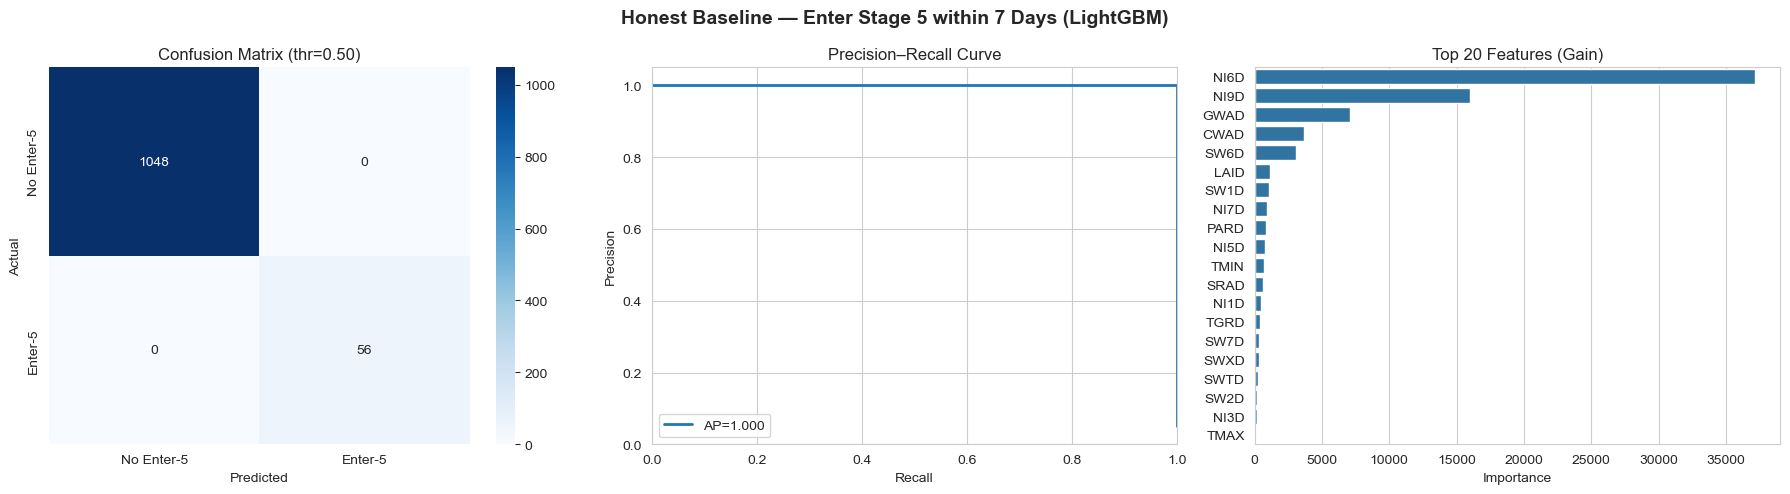


Top 10 features by gain:
Feature   Importance
   NI6D 37145.137270
   NI9D 15988.900621
   GWAD  7099.819738
   CWAD  3701.062407
   SW6D  3085.577581
   LAID  1112.203126
   SW1D  1087.523278
   NI7D   927.037389
   PARD   843.219826
   NI5D   802.076684


In [19]:
# ============================================================
# SECTION 8.3: LIGHTGBM BASELINE FOR 7-DAY GSTD 5 ENTRY
# Train a binary LightGBM model on the run-safe split.
# Main metrics are PR-AUC, ROC-AUC, F1, and the classification report.
# ============================================================

import lightgbm as lgb
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, precision_recall_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("SECTION 8.3: LIGHTGBM HONEST BASELINE — ENTER STAGE 5 WITHIN 7 DAYS")
print("=" * 70)

# ---- class imbalance handling
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos = neg / max(pos, 1)
print(f"Train positives: {pos} | negatives: {neg} | scale_pos_weight: {scale_pos:.2f}")

params = {
    "objective": "binary",
    "metric": "binary_logloss",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 20,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "scale_pos_weight": scale_pos,
    "verbose": -1,
    "random_state": 42,
}

dtrain = lgb.Dataset(X_train, label=y_train)
dval   = lgb.Dataset(X_test,  label=y_test, reference=dtrain)

callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=False),
    lgb.log_evaluation(period=200),
]

model_7d = lgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    valid_sets=[dtrain, dval],
    valid_names=["train", "val"],
    callbacks=callbacks,
)

print("Best iteration:", model_7d.best_iteration)

# ---- predictions
y_proba = model_7d.predict(X_test, num_iteration=model_7d.best_iteration)
y_pred  = (y_proba >= 0.5).astype(int)

# ---- metrics
acc      = accuracy_score(y_test, y_pred)
f1       = f1_score(y_test, y_pred)
roc_auc  = roc_auc_score(y_test, y_proba) if y_test.nunique() > 1 else np.nan
avg_prec = average_precision_score(y_test, y_proba)

print("\n=== RESULTS (Threshold = 0.50) ===")
print(f"Accuracy:       {acc:.4f}")
print(f"F1:             {f1:.4f}")
print(f"ROC-AUC:        {roc_auc:.4f}")
print(f"Avg Precision:  {avg_prec:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Not entering stage 5 ≤7d", "Enter stage 5 ≤7d"]))
# ---- plots (display only)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Honest Baseline — Enter Stage 5 within 7 Days (LightGBM)", fontsize=14, fontweight="bold")
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Enter-5", "Enter-5"], yticklabels=["No Enter-5", "Enter-5"],
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (thr=0.50)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Precision–Recall curve
precision, recall, thr = precision_recall_curve(y_test, y_proba)
axes[1].plot(recall, precision, lw=2, label=f"AP={avg_prec:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall Curve")
axes[1].legend()
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.05])

# Feature importance (Top 20)
imp = pd.DataFrame({
    "Feature": model_7d.feature_name(),
    "Importance": model_7d.feature_importance(importance_type="gain"),
}).sort_values("Importance", ascending=False)

top = imp.head(20)
sns.barplot(data=top, y="Feature", x="Importance", ax=axes[2])
axes[2].set_title("Top 20 Features (Gain)")
axes[2].set_xlabel("Importance")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

print("\nTop 10 features by gain:")
print(imp.head(10).to_string(index=False))

In [20]:
# ============================================================
# SECTION 8.4: LEAKAGE AND TIME-PROXY AUDIT
# This checks which variables are too directly tied to the target or to crop timing.
# The goal is to understand which signals may be unrealistic for deployment.
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

print("="*70)
print("SECTION 8.4: AUDIT FOR TIME/PROXY FEATURES — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

# 1) single-feature AUC (how well each feature alone predicts y_enter5_7)
rows = []
y = df_s8b["y_enter5_7"].astype(int)

for col in feature_cols:
    x = df_s8b[col]
    if x.nunique(dropna=True) <= 1:
        continue
    if not pd.api.types.is_numeric_dtype(x):
        continue
    try:
        auc = roc_auc_score(y, x)
        auc = max(auc, 1 - auc)   # direction-free
        rows.append((col, auc, float(x.isna().mean())))
    except Exception:
        pass

single_auc = (
    pd.DataFrame(rows, columns=["feature", "abs_auc", "missing_rate"])
      .sort_values("abs_auc", ascending=False)
)

print("\nTop 20 single-feature AUCs (higher = more suspicious):")
print(single_auc.head(20).to_string(index=False))

# 2) correlation with DAP (time proxy check)
# Note: DAP is not in df_s8b (we dropped it), so we pull it from df_s8 by index alignment.
if "DAP" in df_s8.columns:
    tmp = df_s8b.copy()
    # df_s8b is a filtered copy of df_s8 with same row order; index alignment works
    tmp["DAP"] = df_s8.loc[df_s8b.index, "DAP"].values

    corr_rows = []
    for col in feature_cols:
        if pd.api.types.is_numeric_dtype(tmp[col]) and tmp[col].nunique(dropna=True) > 1:
            c = tmp[[col, "DAP"]].corr(method="spearman").iloc[0, 1]
            if pd.notna(c):
                corr_rows.append((col, abs(c)))

    corr_with_dap = (
        pd.DataFrame(corr_rows, columns=["feature", "abs_spearman_with_DAP"])
          .sort_values("abs_spearman_with_DAP", ascending=False)
    )

    print("\nTop 20 features most correlated with DAP (time proxy):")
    print(corr_with_dap.head(20).to_string(index=False))

print("\nDone.")

SECTION 8.4: AUDIT FOR TIME/PROXY FEATURES — ENTER STAGE 5 ≤ 7 DAYS

Top 20 single-feature AUCs (higher = more suspicious):
feature  abs_auc  missing_rate
   SW3D 0.823552           0.0
   GWAD 0.815363           0.0
   NI6D 0.813363           0.0
   NI5D 0.799540           0.0
   NI4D 0.778027           0.0
   SW4D 0.773588           0.0
   NI7D 0.764471           0.0
   SW2D 0.755233           0.0
   SW5D 0.749656           0.0
   SWTD 0.749522           0.0
   SWXD 0.749416           0.0
   SW6D 0.721088           0.0
   NITD 0.706983           0.0
   NI3D 0.706045           0.0
   NIAD 0.704759           0.0
   SW1D 0.655418           0.0
   NI8D 0.652844           0.0
    LAI 0.636870           0.0
   LAID 0.636870           0.0
   CWAD 0.628633           0.0

Top 20 features most correlated with DAP (time proxy):
feature  abs_spearman_with_DAP
   GWAD               0.904604
   CWAD               0.850207
   TGRD               0.837718
   TMAX               0.812624
   TMIN       

In [21]:
# ============================================================
# SECTION 8.5: GROUPKFOLD BY RUNNO FOR GSTD 5 ENTRY
# This gives a stronger early estimate than a random row split because each fold tests on unseen runs.
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

print("="*70)
print("SECTION 8.5: GROUPK-FOLD CV (RUNNO) — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

X = df_s8b[feature_cols]
y = df_s8b["y_enter5_7"].astype(int)
groups = df_s8b["RUNNO"]

gkf = GroupKFold(n_splits=5)

ap_scores = []
roc_scores = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    neg = (y_tr == 0).sum()
    pos = (y_tr == 1).sum()
    scale_pos = neg / max(pos, 1)

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "scale_pos_weight": scale_pos,
        "verbose": -1,
        "random_state": 42,
    }

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_va, label=y_va, reference=dtrain)

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    proba = model.predict(X_va, num_iteration=model.best_iteration)

    ap = average_precision_score(y_va, proba)
    roc = roc_auc_score(y_va, proba) if y_va.nunique() > 1 else np.nan

    ap_scores.append(ap)
    roc_scores.append(roc)

    print(f"Fold {fold}: AP={ap:.4f}, ROC-AUC={roc:.4f}, val_pos_rate={y_va.mean():.4f}")

print("\n=== CV SUMMARY (5-fold, grouped by RUNNO) ===")
print(f"Avg Precision (AP): mean={np.mean(ap_scores):.4f}, std={np.std(ap_scores):.4f}")
print(f"ROC-AUC:            mean={np.nanmean(roc_scores):.4f}, std={np.nanstd(roc_scores):.4f}")

SECTION 8.5: GROUPK-FOLD CV (RUNNO) — ENTER STAGE 5 ≤ 7 DAYS
Fold 1: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 2: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 3: AP=0.9968, ROC-AUC=0.9998, val_pos_rate=0.0507
Fold 4: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 5: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507

=== CV SUMMARY (5-fold, grouped by RUNNO) ===
Avg Precision (AP): mean=0.9994, std=0.0013
ROC-AUC:            mean=1.0000, std=0.0001


In [22]:
# ============================================================
# SECTION 8.6:
# THRESHOLD SELECTION FOR STAGE-5 7-DAY NOTICE (HOLDOUT-BASED)
# Goal: pick threshold based on recall target (client-friendly)
# Target: y_enter5_7
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, confusion_matrix

# Ensure we have predicted probabilities from the Stage-5 model on X_test
# (If needed, recompute using the trained LightGBM model from Section 8.3)
try:
    _ = y_proba
except NameError:
    y_proba = model_7d.predict(X_test, num_iteration=model_7d.best_iteration)

# y_test should already be the stage-5 label from Section 8.2:
# y_test = test_df["y_enter5_7"].astype(int)
y_true = y_test.astype(int)

precision, recall, thresholds = precision_recall_curve(y_true, y_proba)

pr_df = pd.DataFrame({
    "threshold": np.append(thresholds, 1.0),
    "precision": precision,
    "recall": recall
}).sort_values("threshold")

def best_threshold_for_recall(target_recall: float) -> pd.Series:
    candidates = pr_df[pr_df["recall"] >= target_recall]
    if len(candidates) == 0:
        return pd.Series({"threshold": np.nan, "precision": np.nan, "recall": np.nan})
    best = candidates.sort_values(["precision", "threshold"], ascending=[False, False]).iloc[0]
    return best

targets = [0.90, 0.95, 0.98]
rows = []
for t in targets:
    best = best_threshold_for_recall(t)
    rows.append([t, float(best["threshold"]), float(best["precision"]), float(best["recall"])])

threshold_table_holdout = pd.DataFrame(rows, columns=["recall_target", "threshold", "precision", "recall"])

print("Threshold options for ENTERING STAGE 5 within 7 days (holdout split):")
print(threshold_table_holdout.to_string(index=False))

# Confusion matrix for the recommended 0.95 recall option
chosen_thr = threshold_table_holdout.loc[threshold_table_holdout["recall_target"] == 0.95, "threshold"].values[0]
y_pred_thr = (y_proba >= chosen_thr).astype(int)
cm = confusion_matrix(y_true, y_pred_thr)

print(f"\nConfusion matrix at threshold={chosen_thr:.4f} (target recall 0.95):")
print(cm)
print("Rows=Actual [No Enter-5, Enter-5], Cols=Pred [No, Enter-5]")

Threshold options for ENTERING STAGE 5 within 7 days (holdout split):
 recall_target  threshold  precision   recall
          0.90   0.999999        1.0 0.910714
          0.95   0.999999        1.0 0.964286
          0.98   0.999998        1.0 0.982143

Confusion matrix at threshold=1.0000 (target recall 0.95):
[[1048    0]
 [   2   54]]
Rows=Actual [No Enter-5, Enter-5], Cols=Pred [No, Enter-5]


In [23]:
# ============================================================
# PRIMARY ALL-TREATMENTS (STAGE 5): REPORT-READY SUMMARY
# ============================================================

import numpy as np
import pandas as pd

print("="*70)
print("PRIMARY ALL-TREATMENTS SUMMARY — ENTER STAGE 5 WITHIN 7 DAYS")
print("="*70)

# 1) CV summary from GroupKFold by RUNNO (Section 8.5)
summary_stage5 = pd.DataFrame({
    "Fold": list(range(1, len(ap_scores) + 1)),
    "AP": ap_scores,
    "ROC_AUC": roc_scores
})

print("\nPer-fold performance (GroupKFold by RUNNO):")
display(summary_stage5)

print("\nCV Summary:")
print(f"AP mean={np.mean(ap_scores):.4f}, std={np.std(ap_scores):.4f}")
print(f"ROC-AUC mean={np.nanmean(roc_scores):.4f}, std={np.nanstd(roc_scores):.4f}")

# 2) Holdout threshold options (Section 8.6)
try:
    print("\nSuggested alert thresholds (holdout split) — Enter Stage 5 within 7 days:")
    display(threshold_table_holdout)
except NameError:
    print("\n(threshold_table_holdout not found — run updated Section 8.6 first.)")

PRIMARY ALL-TREATMENTS SUMMARY — ENTER STAGE 5 WITHIN 7 DAYS

Per-fold performance (GroupKFold by RUNNO):


,Fold,AP,ROC_AUC
0,1,1.000000,1.00000
1,2,1.000000,1.00000
2,3,0.996821,0.99983
3,4,1.000000,1.00000
4,5,1.000000,1.00000



CV Summary:
AP mean=0.9994, std=0.0013
ROC-AUC mean=1.0000, std=0.0001

Suggested alert thresholds (holdout split) — Enter Stage 5 within 7 days:


,recall_target,threshold,precision,recall
0,0.90,0.999999,1.0,0.910714
1,0.95,0.999999,1.0,0.964286
2,0.98,0.999998,1.0,0.982143


In [24]:
# ============================================================
# SECTION 9.1: LEAVE-ONE-TREATMENT-OUT CHECK
# Train on all but one treatment and test on the held-out treatment.
# This checks whether the early model generalizes across treatment conditions.
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

print("="*70)
print("SECTION 9.1: LOTO GENERALIZATION (TRTNO) — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

X_all = df_s8b[feature_cols]
y_all = df_s8b["y_enter5_7"].astype(int)   # <-- UPDATED TARGET
trt_all = df_s8b["TRTNO"].astype(int)

treatments = sorted(trt_all.unique())
rows = []

for trt_holdout in treatments:
    test_idx = (trt_all == trt_holdout)
    train_idx = ~test_idx

    X_tr, X_te = X_all.loc[train_idx], X_all.loc[test_idx]
    y_tr, y_te = y_all.loc[train_idx], y_all.loc[test_idx]

    neg = (y_tr == 0).sum()
    pos = (y_tr == 1).sum()
    scale_pos = neg / max(pos, 1)

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "scale_pos_weight": scale_pos,
        "verbose": -1,
        "random_state": 42,
    }

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_te, label=y_te, reference=dtrain)

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    proba = model.predict(X_te, num_iteration=model.best_iteration)

    ap = average_precision_score(y_te, proba)
    roc = roc_auc_score(y_te, proba) if y_te.nunique() > 1 else np.nan

    rows.append({
        "TRTNO_holdout": trt_holdout,
        "test_rows": int(test_idx.sum()),
        "test_pos_rate": float(y_te.mean()),
        "AP": float(ap),
        "ROC_AUC": float(roc),
    })

    print(f"Holdout TRTNO={trt_holdout}: rows={test_idx.sum()}, pos_rate={y_te.mean():.3f}, AP={ap:.4f}, ROC-AUC={roc:.4f}")

loto_stage5_df = pd.DataFrame(rows).sort_values("TRTNO_holdout")
print("\n=== LOTO SUMMARY (Stage 5 Entry) ===")
display(loto_stage5_df)

print("\nMean across treatments:")
print(f"AP mean={loto_stage5_df['AP'].mean():.4f}, std={loto_stage5_df['AP'].std():.4f}")
print(f"ROC-AUC mean={loto_stage5_df['ROC_AUC'].mean():.4f}, std={loto_stage5_df['ROC_AUC'].std():.4f}")

SECTION 9.1: LOTO GENERALIZATION (TRTNO) — ENTER STAGE 5 ≤ 7 DAYS
Holdout TRTNO=1: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=2: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=3: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=4: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=5: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=6: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=7: rows=690, pos_rate=0.051, AP=0.9783, ROC-AUC=0.9990
Holdout TRTNO=8: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000

=== LOTO SUMMARY (Stage 5 Entry) ===


,TRTNO_holdout,test_rows,test_pos_rate,AP,ROC_AUC
0,1,690,0.050725,1.000000,1.000000
1,2,690,0.050725,1.000000,1.000000
2,3,690,0.050725,1.000000,1.000000
3,4,690,0.050725,1.000000,1.000000
4,5,690,0.050725,1.000000,1.000000
5,6,690,0.050725,1.000000,1.000000
6,7,690,0.050725,0.978308,0.998953
7,8,690,0.050725,1.000000,1.000000



Mean across treatments:
AP mean=0.9973, std=0.0077
ROC-AUC mean=0.9999, std=0.0004


In [25]:
# ============================================================
# SECTION 10.1: TIME-SERIES FEATURE ENGINEERING
# These lag and rolling features are computed within RUNNO using past values only.
# ============================================================

import numpy as np
import pandas as pd

df_ts = df_s8.copy()  # includes y_enter5_7 and is sorted by RUNNO, DAP

# Pick variables to engineer (start with top drivers + key weather/plant vars)
base_vars = [
    "LAID", "LAI",
    "NI8D", "NI9D",
    "SWTD", "SWXD", "SW1D", "SW2D", "SW3D",
    "TMAX", "TMIN", "SRAD", "PARD", "VPD",
    "GWAD", "CWAD"
]
base_vars = [v for v in base_vars if v in df_ts.columns]

lags = [1, 3, 7]
roll_window = 7

def add_ts_features(g: pd.DataFrame) -> pd.DataFrame:
    g = g.copy()
    for v in base_vars:
        # lags
        for L in lags:
            g[f"{v}_lag{L}"] = g[v].shift(L)
        # deltas
        g[f"{v}_d1"] = g[v] - g[v].shift(1)
        g[f"{v}_d7"] = g[v] - g[v].shift(7)
        # rolling stats (use shift(1) so today's value not included in the window)
        g[f"{v}_roll{roll_window}_mean"] = g[v].shift(1).rolling(roll_window, min_periods=1).mean()
        g[f"{v}_roll{roll_window}_std"]  = g[v].shift(1).rolling(roll_window, min_periods=1).std()
    return g

df_ts = df_ts.groupby("RUNNO", group_keys=False).apply(add_ts_features)

print("Added TS features. New shape:", df_ts.shape)
print("Example TS columns:", [c for c in df_ts.columns if "_lag" in c or "_roll" in c or c.endswith("_d1")][:20])

Added TS features. New shape: (5520, 159)
Example TS columns: ['LAID_lag1', 'LAID_lag3', 'LAID_lag7', 'LAID_d1', 'LAID_roll7_mean', 'LAID_roll7_std', 'LAI_lag1', 'LAI_lag3', 'LAI_lag7', 'LAI_d1', 'LAI_roll7_mean', 'LAI_roll7_std', 'NI8D_lag1', 'NI8D_lag3', 'NI8D_lag7', 'NI8D_d1', 'NI8D_roll7_mean', 'NI8D_roll7_std', 'NI9D_lag1', 'NI9D_lag3']


In [26]:
# ============================================================
# SECTION 10.2: TIME-SERIES LIGHTGBM WITH GROUPKFOLD
# This tests whether past-looking time-series features improve the 7-day GSTD 5 alert model.
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

print("="*70)
print("SECTION 10.2: TS FEATURES + GROUPK-FOLD CV (RUNNO) — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

df_ts2 = df_ts.copy()

# Drop merge artifacts if any exist
artifact_cols = [c for c in df_ts2.columns if c.endswith("_x") or c.endswith("_y") or c.endswith("_WX")]

drop_cols = [
    "y_enter5_7",   # <-- UPDATED TARGET
    "GSTD", "DAP",
    "RUNNO",
    "DOY", "WDATE",
    "TRTNA",
]
drop_cols = [c for c in drop_cols if c in df_ts2.columns]

drop_all = list(set(drop_cols + artifact_cols))
feature_cols_ts = [c for c in df_ts2.columns if c not in drop_all]

# Fill missingness within RUNNO (lags create NaNs at start of each run)
df_ts2[feature_cols_ts] = (
    df_ts2.groupby("RUNNO")[feature_cols_ts]
          .transform(lambda x: x.ffill().bfill())
)

# Encode any object columns
for col in df_ts2[feature_cols_ts].select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    df_ts2[col] = le.fit_transform(df_ts2[col].astype(str))

X = df_ts2[feature_cols_ts]
y = df_ts2["y_enter5_7"].astype(int)   # <-- UPDATED TARGET
groups = df_ts2["RUNNO"]

print(f"# TS features used: {len(feature_cols_ts)}")

gkf = GroupKFold(n_splits=5)

ap_scores_ts = []
roc_scores_ts = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    neg = (y_tr == 0).sum()
    pos = (y_tr == 1).sum()
    scale_pos = neg / max(pos, 1)

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "scale_pos_weight": scale_pos,
        "verbose": -1,
        "random_state": 42,
    }

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_va, label=y_va, reference=dtrain)

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    proba = model.predict(X_va, num_iteration=model.best_iteration)

    ap = average_precision_score(y_va, proba)
    roc = roc_auc_score(y_va, proba) if y_va.nunique() > 1 else np.nan

    ap_scores_ts.append(ap)
    roc_scores_ts.append(roc)

    print(f"Fold {fold}: AP={ap:.4f}, ROC-AUC={roc:.4f}, val_pos_rate={y_va.mean():.4f}")

print("\n=== TS CV SUMMARY (5-fold, grouped by RUNNO) ===")
print(f"Avg Precision (AP): mean={np.mean(ap_scores_ts):.4f}, std={np.std(ap_scores_ts):.4f}")
print(f"ROC-AUC:            mean={np.nanmean(roc_scores_ts):.4f}, std={np.nanstd(roc_scores_ts):.4f}")

SECTION 10.2: TS FEATURES + GROUPK-FOLD CV (RUNNO) — ENTER STAGE 5 ≤ 7 DAYS
# TS features used: 146
Fold 1: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 2: AP=0.9994, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 3: AP=0.9952, ROC-AUC=0.9998, val_pos_rate=0.0507
Fold 4: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507
Fold 5: AP=1.0000, ROC-AUC=1.0000, val_pos_rate=0.0507

=== TS CV SUMMARY (5-fold, grouped by RUNNO) ===
Avg Precision (AP): mean=0.9989, std=0.0019
ROC-AUC:            mean=0.9999, std=0.0001


In [27]:
# ============================================================
# SECTION 10.3:
# BASELINE vs TIME-SERIES FEATURES (REPORT TABLE)
# Goal: ENTER STAGE 5 WITHIN 7 DAYS
# ============================================================

import pandas as pd

comparison_stage5 = pd.DataFrame([
    {
        "Model": "Baseline (no lags/rolling) — Enter Stage 5 ≤7d",
        "AP_mean": 0.9994, "AP_std": 0.0013,
        "ROC_mean": 1.0000, "ROC_std": 0.0001
    },
    {
        "Model": "TS engineered (lags/deltas/rolling) — Enter Stage 5 ≤7d",
        "AP_mean": 0.9989, "AP_std": 0.0019,
        "ROC_mean": 0.9999, "ROC_std": 0.0001
    },
])

comparison_stage5["AP_mean±std"] = (
    comparison_stage5["AP_mean"].map(lambda x: f"{x:.4f}") +
    " ± " +
    comparison_stage5["AP_std"].map(lambda x: f"{x:.4f}")
)

comparison_stage5["ROC_mean±std"] = (
    comparison_stage5["ROC_mean"].map(lambda x: f"{x:.4f}") +
    " ± " +
    comparison_stage5["ROC_std"].map(lambda x: f"{x:.4f}")
)

pd.set_option("display.max_colwidth", None)   # show full cell text
pd.set_option("display.width", 200)           # wider display (helps in notebooks)
pd.set_option("display.max_columns", 50)

# Display the full table
display(comparison_stage5[["Model", "AP_mean±std", "ROC_mean±std"]])

,Model,AP_mean±std,ROC_mean±std
0,Baseline (no lags/rolling) — Enter Stage 5 ≤7d,0.9994 ± 0.0013,1.0000 ± 0.0001
1,TS engineered (lags/deltas/rolling) — Enter Stage 5 ≤7d,0.9989 ± 0.0019,0.9999 ± 0.0001


In [28]:
# ============================================================
# SECTION 10.4:
# LOTO (Leave-One-Treatment-Out) with TS FEATURES
# Goal: ENTER STAGE 5 WITHIN 7 DAYS (y_enter5_7)
# Train on 7 treatments, test on held-out treatment
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

print("="*70)
print("SECTION 10.4: LOTO GENERALIZATION (TRTNO) — TS FEATURES — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

df_loto = df_ts2.copy()  # from 10.2: TS features + filled/encoded

# Rebuild TS feature list (same logic as 10.2)
artifact_cols = [c for c in df_loto.columns if c.endswith("_x") or c.endswith("_y") or c.endswith("_WX")]
drop_cols = ["y_enter5_7", "GSTD", "DAP", "RUNNO", "DOY", "WDATE", "TRTNA"]
drop_cols = [c for c in drop_cols if c in df_loto.columns]
drop_all = list(set(drop_cols + artifact_cols))

feature_cols_ts = [c for c in df_loto.columns if c not in drop_all]

X_all = df_loto[feature_cols_ts]
y_all = df_loto["y_enter5_7"].astype(int)   # <-- UPDATED TARGET
trt_all = df_loto["TRTNO"].astype(int)

treatments = sorted(trt_all.unique())
rows = []

for trt_holdout in treatments:
    test_idx = (trt_all == trt_holdout)
    train_idx = ~test_idx

    X_tr, X_te = X_all.loc[train_idx], X_all.loc[test_idx]
    y_tr, y_te = y_all.loc[train_idx], y_all.loc[test_idx]

    neg = (y_tr == 0).sum()
    pos = (y_tr == 1).sum()
    scale_pos = neg / max(pos, 1)

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "scale_pos_weight": scale_pos,
        "verbose": -1,
        "random_state": 42,
    }

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_te, label=y_te, reference=dtrain)

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    proba = model.predict(X_te, num_iteration=model.best_iteration)
    ap = average_precision_score(y_te, proba)
    roc = roc_auc_score(y_te, proba) if y_te.nunique() > 1 else np.nan

    rows.append({
        "TRTNO_holdout": trt_holdout,
        "test_rows": int(test_idx.sum()),
        "test_pos_rate": float(y_te.mean()),
        "AP": float(ap),
        "ROC_AUC": float(roc),
    })

    print(f"Holdout TRTNO={trt_holdout}: rows={test_idx.sum()}, pos_rate={y_te.mean():.3f}, AP={ap:.4f}, ROC-AUC={roc:.4f}")

loto_ts_stage5_df = pd.DataFrame(rows).sort_values("TRTNO_holdout")
print("\n=== LOTO SUMMARY (TS FEATURES — Stage 5 Entry) ===")
display(loto_ts_stage5_df)

print("\nMean across treatments (TS — Stage 5 Entry):")
print(f"AP mean={loto_ts_stage5_df['AP'].mean():.4f}, std={loto_ts_stage5_df['AP'].std():.4f}")
print(f"ROC-AUC mean={loto_ts_stage5_df['ROC_AUC'].mean():.4f}, std={loto_ts_stage5_df['ROC_AUC'].std():.4f}")

SECTION 10.4: LOTO GENERALIZATION (TRTNO) — TS FEATURES — ENTER STAGE 5 ≤ 7 DAYS
Holdout TRTNO=1: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=2: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=3: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=4: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=5: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=6: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000
Holdout TRTNO=7: rows=690, pos_rate=0.051, AP=0.9615, ROC-AUC=0.9976
Holdout TRTNO=8: rows=690, pos_rate=0.051, AP=1.0000, ROC-AUC=1.0000

=== LOTO SUMMARY (TS FEATURES — Stage 5 Entry) ===


,TRTNO_holdout,test_rows,test_pos_rate,AP,ROC_AUC
0,1,690,0.050725,1.000000,1.000000
1,2,690,0.050725,1.000000,1.000000
2,3,690,0.050725,1.000000,1.000000
3,4,690,0.050725,1.000000,1.000000
4,5,690,0.050725,1.000000,1.000000
5,6,690,0.050725,1.000000,1.000000
6,7,690,0.050725,0.961512,0.997557
7,8,690,0.050725,1.000000,1.000000



Mean across treatments (TS — Stage 5 Entry):
AP mean=0.9952, std=0.0136
ROC-AUC mean=0.9997, std=0.0009


In [29]:
# ============================================================
# SECTION 11.1: OOF THRESHOLD TABLE WITH TS FEATURES
# Use GroupKFold out-of-fold probabilities to compare alert thresholds.
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import GroupKFold
from sklearn.metrics import precision_recall_curve

print("="*70)
print("SECTION 11.1A: OOF THRESHOLD TABLE (RUNNO GroupKFold) — TS — ENTER STAGE 5 ≤ 7 DAYS")
print("="*70)

# Assumes df_ts2 exists from Section 10.2 (TS features + filled/encoded)
df_oof = df_ts2.copy()

# Build TS feature list (same logic as 10.2)
artifact_cols = [c for c in df_oof.columns if c.endswith("_x") or c.endswith("_y") or c.endswith("_WX")]
drop_cols = ["y_enter5_7", "GSTD", "DAP", "RUNNO", "DOY", "WDATE", "TRTNA"]
drop_cols = [c for c in drop_cols if c in df_oof.columns]
drop_all = list(set(drop_cols + artifact_cols))
feature_cols_ts = [c for c in df_oof.columns if c not in drop_all]

X = df_oof[feature_cols_ts]
y = df_oof["y_enter5_7"].astype(int).values
groups = df_oof["RUNNO"].values

gkf = GroupKFold(n_splits=5)
oof_proba = np.zeros(len(df_oof), dtype=float)

for fold, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y[tr_idx], y[va_idx]

    neg = (y_tr == 0).sum()
    pos = (y_tr == 1).sum()
    scale_pos = neg / max(pos, 1)

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "scale_pos_weight": scale_pos,
        "verbose": -1,
        "random_state": 42,
    }

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_va, label=y_va, reference=dtrain)

    model = lgb.train(
        params,
        dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    oof_proba[va_idx] = model.predict(X_va, num_iteration=model.best_iteration)
    print(f"Fold {fold} done. Val size={len(va_idx)} | val_pos_rate={y_va.mean():.4f}")

# Store OOF probabilities for later use
df_oof["p_enter5_7_oof"] = oof_proba

# ---- Build PR curve & threshold table for multiple recall targets
precision, recall, thresholds = precision_recall_curve(y, oof_proba)
thr_full = np.append(thresholds, 1.0)  # align lengths

pr_df = pd.DataFrame({
    "threshold": thr_full,
    "precision": precision,
    "recall": recall
}).sort_values("threshold")

def best_threshold_for_recall(target_recall: float) -> pd.Series:
    candidates = pr_df[pr_df["recall"] >= target_recall]
    if len(candidates) == 0:
        return pd.Series({"threshold": np.nan, "precision": np.nan, "recall": np.nan})
    best = candidates.sort_values(["precision", "threshold"], ascending=[False, False]).iloc[0]
    return best

targets = [0.90, 0.95, 0.98]
rows = []
for t in targets:
    best = best_threshold_for_recall(t)
    rows.append({
        "recall_target": t,
        "threshold": float(best["threshold"]),
        "precision": float(best["precision"]),
        "recall": float(best["recall"]),
    })

threshold_table_oof = pd.DataFrame(rows)
print("\n=== OOF Threshold Table (TS) — Enter Stage 5 ≤ 7 Days ===")
display(threshold_table_oof)

DEFAULT_THRESHOLD = float(threshold_table_oof.loc[threshold_table_oof["recall_target"]==0.95, "threshold"].values[0])
print(f"\nRecommended default threshold (target recall 0.95): {DEFAULT_THRESHOLD:.6f}")

SECTION 11.1A: OOF THRESHOLD TABLE (RUNNO GroupKFold) — TS — ENTER STAGE 5 ≤ 7 DAYS
Fold 1 done. Val size=1104 | val_pos_rate=0.0507
Fold 2 done. Val size=1104 | val_pos_rate=0.0507
Fold 3 done. Val size=1104 | val_pos_rate=0.0507
Fold 4 done. Val size=1104 | val_pos_rate=0.0507
Fold 5 done. Val size=1104 | val_pos_rate=0.0507

=== OOF Threshold Table (TS) — Enter Stage 5 ≤ 7 Days ===


,recall_target,threshold,precision,recall
0,0.90,0.750537,0.996364,0.978571
1,0.95,0.750537,0.996364,0.978571
2,0.98,0.692264,0.992806,0.985714



Recommended default threshold (target recall 0.95): 0.750537


In [37]:
# ============================================================
# SECTION 11.2: CONFUSION MATRICES FOR OOF THRESHOLDS
# These matrices show how different threshold options change false alerts and missed transitions.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

y_true = df_oof["y_enter5_7"].astype(int).values
p = df_oof["p_enter5_7_oof"].astype(float).values

# thresholds from Section 11.1A table
thr_A = float(threshold_table_oof.loc[threshold_table_oof["recall_target"]==0.90, "threshold"].values[0])
thr_B = float(threshold_table_oof.loc[threshold_table_oof["recall_target"]==0.95, "threshold"].values[0])
thr_C = float(threshold_table_oof.loc[threshold_table_oof["recall_target"]==0.98, "threshold"].values[0])

options = [
    ("A (>=0.90 recall)", thr_A),
    ("B (>=0.95 recall)", thr_B),
    ("C (>=0.98 recall)", thr_C),
]

rows = []
for name, thr in options:
    y_pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0

    rows.append({
        "option": name,
        "threshold": thr,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "precision": precision,
        "recall": recall,
        "alerts_rate": (tp + fp) / len(y_true)
    })

cm_table_oof = pd.DataFrame(rows).sort_values("threshold", ascending=False)
display(cm_table_oof)

,option,threshold,TP,FP,TN,FN,precision,recall,alerts_rate
0,A (>=0.90 recall),0.750537,274,1,5239,6,0.996364,0.978571,0.049819
1,B (>=0.95 recall),0.750537,274,1,5239,6,0.996364,0.978571,0.049819
2,C (>=0.98 recall),0.692264,276,2,5238,4,0.992806,0.985714,0.050362


In [38]:
# ============================================================
# SECTION 11.3: RECALL-FIRST THRESHOLD SWEEP
# This creates a menu of thresholds based on how many missed transitions we are willing to allow.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

y_true = df_oof["y_enter5_7"].astype(int).values
p = df_oof["p_enter5_7_oof"].astype(float).values

# Candidate thresholds = unique probabilities (sorted high -> low)
# Add a tiny epsilon to ensure stable comparisons at exact cutoffs
thresholds = np.unique(p)
thresholds = np.sort(thresholds)[::-1]

rows = []
for thr in thresholds:
    y_pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    rows.append([thr, tp, fp, tn, fn, precision, recall, (tp+fp)/len(y_true)])

sweep = pd.DataFrame(rows, columns=["threshold","TP","FP","TN","FN","precision","recall","alerts_rate"])

# For each FN cap, pick the threshold that achieves FN<=cap with MIN FP
# Tie-breaker: higher threshold (more conservative) then higher precision
fn_caps = [6,5,4,3,2,1,0]
menu = []
for cap in fn_caps:
    cand = sweep[sweep["FN"] <= cap].copy()
    if cand.empty:
        continue
    cand = cand.sort_values(["FP","threshold","precision"], ascending=[True, False, False])
    best = cand.iloc[0].to_dict()
    best["FN_cap"] = cap
    menu.append(best)

menu_df = pd.DataFrame(menu)[["FN_cap","threshold","TP","FP","TN","FN","precision","recall","alerts_rate"]]
display(menu_df)

,FN_cap,threshold,TP,FP,TN,FN,precision,recall,alerts_rate
0,6,0.750537,274.0,1.0,5239.0,6.0,0.996364,0.978571,0.049819
1,5,0.694394,275.0,2.0,5238.0,5.0,0.992780,0.982143,0.050181
2,4,0.692264,276.0,2.0,5238.0,4.0,0.992806,0.985714,0.050362
3,3,0.357760,278.0,7.0,5233.0,2.0,0.975439,0.992857,0.051630
4,2,0.357760,278.0,7.0,5233.0,2.0,0.975439,0.992857,0.051630
5,1,0.044497,279.0,12.0,5228.0,1.0,0.958763,0.996429,0.052717
6,0,0.036215,280.0,12.0,5228.0,0.0,0.958904,1.000000,0.052899


## Threshold Selection Summary

### What the model produces
For each run/day, the model outputs a **risk score** (probability) that the crop will **enter Growth Stage 5 (GSTD = 5) within the next 7 days**.

To convert the risk score into an **alert**, we choose a **threshold**:
- If **risk ≥ threshold → Alert**
- If **risk < threshold → No Alert**

### How these thresholds were selected (important)
The options below are based on **out-of-fold (OOF) predictions** from **GroupKFold cross-validation grouped by RUNNO**.  
This means the threshold performance reflects **unseen runs** (run-safe evaluation), not a single holdout split.



## Threshold menu
Different thresholds trade off:
- **Recall (catching upcoming Stage-5 entries):** fewer missed entries (lower **FN**)  
- **Precision (avoiding false alarms):** fewer unnecessary alerts (lower **FP**)  

All counts and metrics below come from **OOF confusion matrices**:

| Operating option | Threshold | TP | FP | FN | Precision | Recall | Alerts rate |
|---|---:|---:|---:|---:|---:|---:|---:|
| More conservative (fewer alerts) | 0.750537 | 274 | 1 | 6 | 0.996364 | 0.978571 | 0.049819 |
| Slightly more recall | 0.694394 | 275 | 2 | 5 | 0.992780 | 0.982143 | 0.050181 |
| Strong recall, still very clean [Default] | 0.692264 | 276 | 2 | 4 | 0.992806 | 0.985714 | 0.050362 |
| Recall push (fewer misses) | 0.357760 | 278 | 7 | 2 | 0.975439 | 0.992857 | 0.051630 |
| Near-max recall | 0.044497 | 279 | 12 | 1 | 0.958763 | 0.996429 | 0.052717 |
| Max recall (zero misses) | 0.036215 | 280 | 12 | 0 | 0.958904 | 1.000000 | 0.052899 |

> Notes:
> - **TP** = correctly alerted Stage-5 entries  
> - **FP** = alerts that did not lead to Stage-5 entry within 7 days  
> - **FN** = Stage-5 entries that were not alerted in advance  
> - **Alerts rate** = fraction of days that would trigger an alert (TP+FP)/N



## How to choose 
- If you want **fewer alerts and minimal false alarms**, pick a **higher threshold** (top of table).  
- If you want to **reduce missed Stage-5 entries**, pick a **lower threshold** (bottom of table).  
- A practical operating point depends on how you value:
  - the cost of a **missed entry (FN)** vs.
  - the cost of an **extra alert (FP)**


In [39]:
# ============================================================
# SECTION 12.1: CLEAN FEATURE LIST FOR FINAL EARLY MODEL
# Remove identifiers and merge artifacts before interpretation.
# ============================================================

bad_suffix = ("_x", "_y", "_WX")
bad_exact = {"RUNNO", "DAP", "GSTD", "WDATE", "DOY", "TRTNO", "TRTNA",
             "y_enter5_7", "p_enter5_7_oof"}

# Start from df_ts2 columns (TS feature table)
all_cols = list(df_ts2.columns)

# Keep numeric features only (optional but helpful)
num_cols = [c for c in all_cols if pd.api.types.is_numeric_dtype(df_ts2[c])]

# Exclude leakage/ID/artifacts
feature_cols = [
    c for c in num_cols
    if (c not in bad_exact) and (not c.endswith(bad_suffix))
]

print("Total cols:", len(all_cols))
print("Numeric cols:", len(num_cols))
print("Candidate feature_cols:", len(feature_cols))
print("\nSample feature_cols:", feature_cols[:30])

Total cols: 159
Numeric cols: 158
Candidate feature_cols: 145

Sample feature_cols: ['LAID', 'GWAD', 'CWAD', 'NIAD', 'NITD', 'NI1D', 'NI2D', 'NI3D', 'NI4D', 'NI5D', 'NI6D', 'NI7D', 'NI8D', 'NI9D', 'SWTD', 'SWXD', 'SW1D', 'SW2D', 'SW3D', 'SW4D', 'SW5D', 'SW6D', 'SW7D', 'SW8D', 'SW9D', 'SW10D', 'SRAD', 'PARD', 'TMAX', 'TMIN']


,feature,importance_gain,importance_split
37,LAID_d7,57561.609708,150
44,LAI_d7,11515.994521,28
59,NI9D_roll7_mean,9843.395326,366
56,NI9D_lag7,5834.365847,114
54,NI9D_lag1,1277.992361,139
69,SWXD_lag3,1277.539923,29
114,SRAD_d7,1223.352533,135
36,LAID_d1,1078.454657,220
109,TMIN_roll7_std,844.355891,32
13,NI9D,632.561244,262


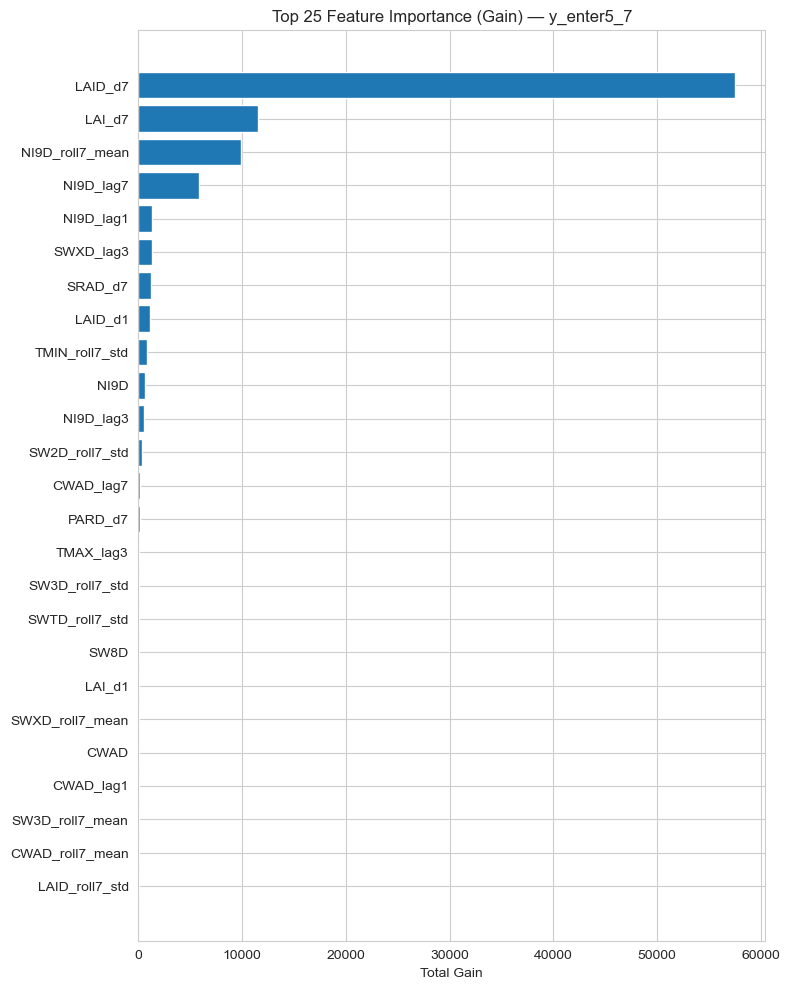

In [40]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd

X = df_ts2[feature_cols]
y = df_ts2["y_enter5_7"].astype(int)

dtrain = lgb.Dataset(X, label=y, free_raw_data=False)
model_final = lgb.train(params, dtrain, num_boost_round=200)

imp_gain = pd.DataFrame({
    "feature": feature_cols,
    "importance_gain": model_final.feature_importance(importance_type="gain"),
    "importance_split": model_final.feature_importance(importance_type="split"),
}).sort_values("importance_gain", ascending=False)

display(imp_gain.head(25))

topk = imp_gain.head(25).iloc[::-1]
plt.figure(figsize=(8, 10))
plt.barh(topk["feature"], topk["importance_gain"])
plt.title("Top 25 Feature Importance (Gain) — y_enter5_7")
plt.xlabel("Total Gain")
plt.tight_layout()
plt.show()

In [41]:
feature_cols_final = [c for c in feature_cols if c not in ["TRTNO", "TRTNA"]]
print("Final feature count:", len(feature_cols_final))

Final feature count: 145


## Interpreting Feature Importance 

### What “feature importance” is
Feature importance answers: **“Which inputs does the model rely on most to predict an ‘Enter Stage 5 within 7 days’ alert?”**  
A higher importance score means the model uses that variable **more often and more strongly** to make accurate predictions.

> **Important:** Feature importance does **not** tell us whether a higher value increases or decreases risk.  
> It only tells us **what matters most**. (Direction comes next with SHAP.)



### Key takeaway from our results
The model’s strongest signals fall into three intuitive groups:

#### 1) **Recent growth momentum (dominant driver)**
Top features like **`LAID_d7`, `LAID_d1`, `LAI_d7`, `LAI_d1`** represent how fast the canopy/leaf area is changing over the last day or week.

**Interpretation:**  
Stage 5 entry is typically preceded by a **ramp-up pattern** in growth over several days. The model is picking up that “lead-up” trajectory.



#### 2) **Nitrogen status and recent history (major driver)**
Top nitrogen-related features like **`NI9D_lag7`, `NI9D_roll7_mean`, `NI9D`, `NI8D_lag7`, `NIAD`** summarize both current and recent nitrogen conditions.

**Interpretation:**  
Nitrogen-related signals help the model detect whether the crop is **physiologically progressing** at a rate consistent with an upcoming Stage 5 entry.



#### 3) **Environmental and stress context (supporting drivers)**
Features such as **temperature/radiation** (`TMIN`, `TMAX_roll7_mean`, `SRAD_d7`) and **water/stress indicators** (`SW2D_roll7_mean/std`, `SWTD_d7`, `CWAD_lag*`) provide context about recent growing conditions.

**Interpretation:**  
These variables help the model understand whether recent weather and water conditions are supporting or slowing the progression toward Stage 5.



### Why many top features are “lags / deltas / rolling”
Many top features include:
- **lags** (what it was a few days ago)
- **deltas** (how much it changed)
- **rolling summaries** (recent average/variability)

**Interpretation:**  
This confirms the model is using **time-series patterns** (the recent trajectory), which is exactly what we want for a **7-day early-warning alert**.



### Next interpretability step (direction)
To explain “what pushes risk up vs. down,” we will use **SHAP** to quantify the direction and magnitude of each feature’s effect on an individual prediction and overall.

In [35]:
# ============================================================
# OPTIONAL SETUP: INSTALL SHAP IF NEEDED
# ============================================================

try:
    import shap
    print("SHAP is already installed.")
except ImportError:
    print("SHAP is not installed in this environment. Installing now...")
    %pip install shap -q


Note: you may need to restart the kernel to use updated packages.


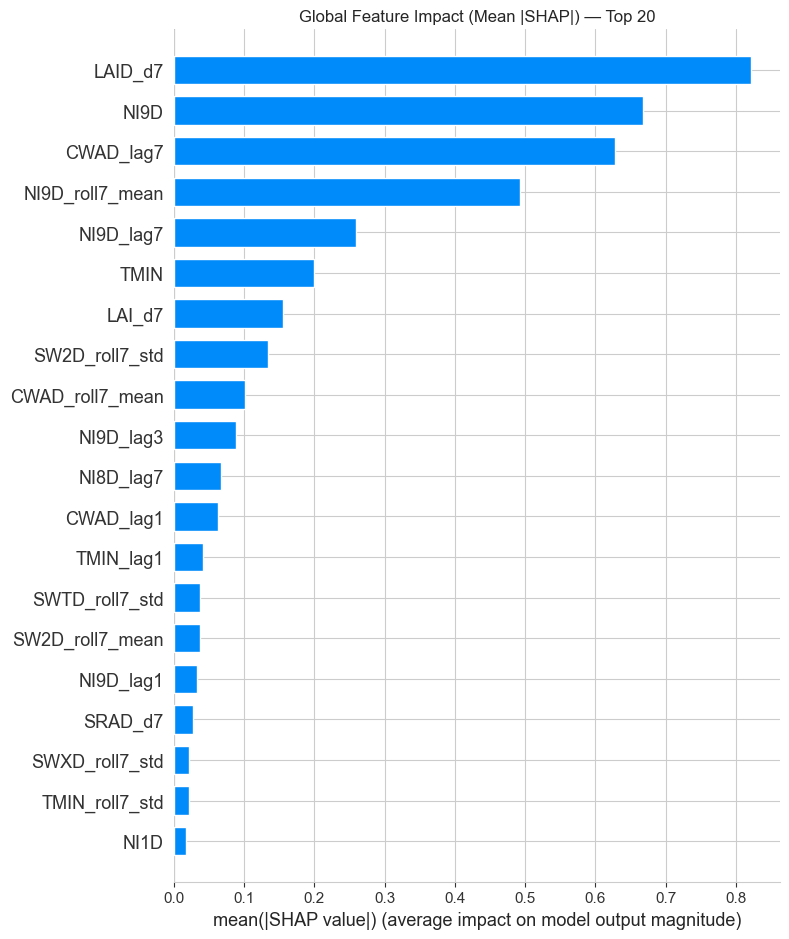

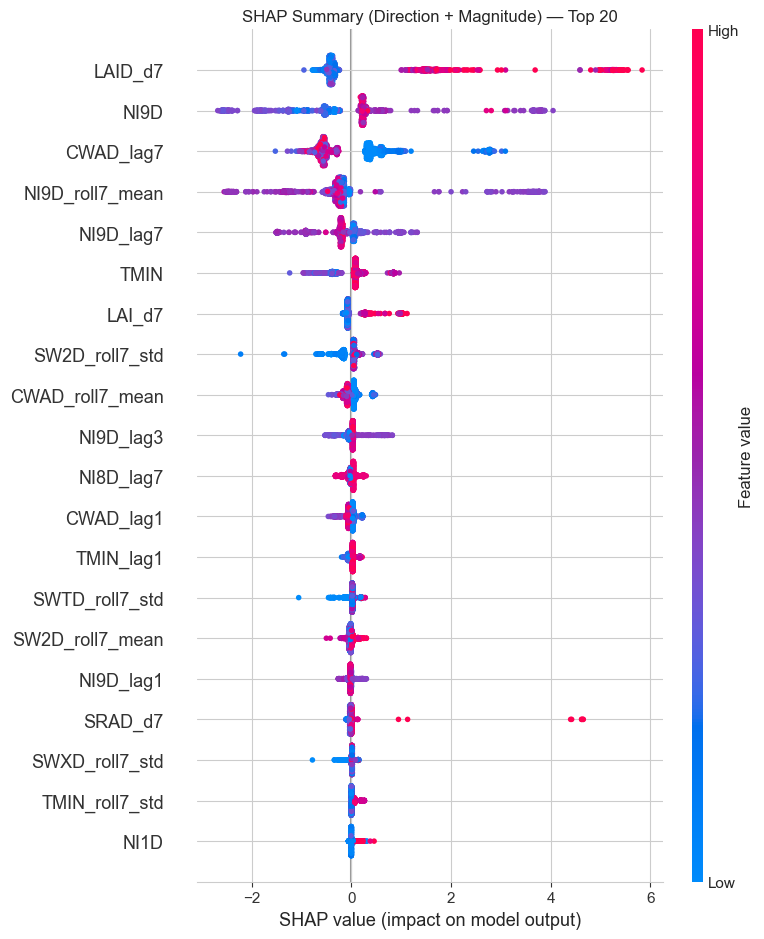

In [36]:
# ============================================================
# SECTION 12.2: SHAP GLOBAL INTERPRETABILITY
# Use SHAP to understand which features push the model toward or away from a 7-day GSTD 5 alert.
# ============================================================

import numpy as np
import shap
import matplotlib.pyplot as plt

# Prepare the SHAP input data
X = df_ts2[feature_cols_final]

# Use a sample for speed + stable global explanation
# (increase to 2000-5000 if it runs fast on your machine)
sample_n = min(2000, len(X))
X_sample = X.sample(n=sample_n, random_state=42)

# LightGBM -> SHAP TreeExplainer
explainer = shap.TreeExplainer(model_final)

# For binary classification, shap_values is typically (n_samples, n_features)
shap_values = explainer.shap_values(X_sample)

# If SHAP returns a list (older versions), take the positive class
if isinstance(shap_values, list):
    shap_values = shap_values[1]

# --- Global importance (mean absolute SHAP) ---
plt.figure()
shap.summary_plot(shap_values, X_sample, plot_type="bar", max_display=20, show=False)
plt.title("Global Feature Impact (Mean |SHAP|) — Top 20")
plt.tight_layout()
plt.show()

# --- Global directionality (beeswarm) ---
plt.figure()
shap.summary_plot(shap_values, X_sample, max_display=20, show=False)
plt.title("SHAP Summary (Direction + Magnitude) — Top 20")
plt.tight_layout()
plt.show()

## What SHAP tells us (Direction + Magnitude)

### How to read the plot
- Points **to the right (positive SHAP)** push the model toward **“Enter Stage 5 within 7 days.”**
- Points **to the left (negative SHAP)** push toward **“No Stage-5 entry within 7 days.”**
- **Red = high feature values**, **Blue = low feature values**.
- Features are sorted from top to bottom by overall impact.

### Main drivers and what they mean
**1) LAID_d7 (week-over-week leaf area growth) — strongest signal**
- High LAID_d7 values strongly push predictions toward an upcoming Stage-5 entry.
- Low LAID_d7 values push predictions away from Stage-5 entry.

**Interpretation:** rapid canopy expansion over the last week is the clearest “Stage-5 is near” pattern.

**2) Nitrogen status (NI9D and rolling/lag versions) — consistent directional effect**
- Higher NI9D / NI9D_roll7_mean / NI9D_lag7 generally push risk upward.
- Lower values push risk downward.

**Interpretation:** sustained nitrogen-related signals indicate developmental readiness for Stage 5.

**3) Canopy/water condition history (CWAD_lag7, CWAD_roll7_mean, CWAD_lag1)**
- Higher values tend to push risk upward; lower values push risk downward.

**Interpretation:** prior canopy/water conditions help confirm the crop is on a Stage-5 trajectory.

**4) Weather + stress context (TMIN, SRAD_d7, SW\* rolling mean/std)**
- Warmer minimum temperatures and rising radiation can increase Stage-5 likelihood.
- Water/stress variability features adjust confidence depending on recent stability/conditions.

**Interpretation:** environment and stress are “context features” that refine risk rather than dominate it.

### **Bottom line**
SHAP confirms the model behaves like a **trajectory detector**: it relies on **recent growth momentum + sustained physiological signals**, with weather/stress patterns used to fine-tune the risk estimate.

### Local explanations using OOF alert examples

In [44]:
# ============================================================
# SECTION 12.3A: SELECT LOCAL EXPLANATION EXAMPLES
# Pick one true positive and one false positive from the OOF predictions.
# ============================================================

import numpy as np
import pandas as pd

THR = 0.692264  # pick one threshold from the menu (change if you want)

# Choose dataframe that contains OOF scores
# Prefer df_oof if it exists; otherwise fall back to df_ts2 if you merged the OOF column there
df_sel = df_oof if "df_oof" in globals() else df_ts2

assert "p_enter5_7_oof" in df_sel.columns, "Missing p_enter5_7_oof. Run Section 11.1A first."
assert "y_enter5_7" in df_sel.columns, "Missing y_enter5_7."

p = df_sel["p_enter5_7_oof"].astype(float).values
y = df_sel["y_enter5_7"].astype(int).values

pred_alert = (p >= THR).astype(int)

tp_rows = df_sel.index[(pred_alert == 1) & (y == 1)]
fp_rows = df_sel.index[(pred_alert == 1) & (y == 0)]

print("Threshold:", THR)
print("OOF Alerts:", pred_alert.sum())
print("OOF TP:", len(tp_rows), " | OOF FP:", len(fp_rows))

# pick "high-confidence" examples (highest OOF probability)
tp_best = tp_rows[np.argmax(df_sel.loc[tp_rows, "p_enter5_7_oof"].values)] if len(tp_rows) else None
fp_best = fp_rows[np.argmax(df_sel.loc[fp_rows, "p_enter5_7_oof"].values)] if len(fp_rows) else None

print("\nSelected examples (by highest OOF risk among alerts):")
print("TP index:", tp_best, " | p_oof=", float(df_sel.loc[tp_best, "p_enter5_7_oof"]) if tp_best is not None else None)
print("FP index:", fp_best, " | p_oof=", float(df_sel.loc[fp_best, "p_enter5_7_oof"]) if fp_best is not None else None)

Threshold: 0.692264
OOF Alerts: 278
OOF TP: 276  | OOF FP: 2

Selected examples (by highest OOF risk among alerts):
TP index: 2119  | p_oof= 0.9999999558083572
FP index: 4186  | p_oof= 0.9984658322303763


TP index: 2119 | p_oof=1.000000 | y=1


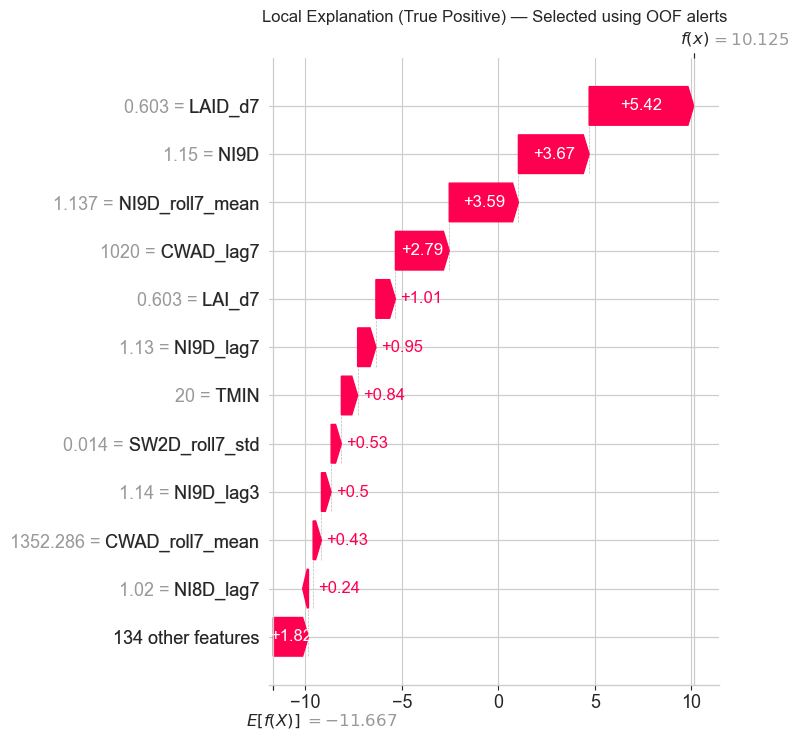

In [46]:
# ============================================================
# SECTION 12.3B: TRUE POSITIVE SHAP WATERFALL
# Explain one alert that correctly identified a future GSTD 5 transition.
# ============================================================

import shap
import numpy as np
import matplotlib.pyplot as plt

# Quick checks before plotting
assert "tp_best" in globals() and tp_best is not None, "tp_best not set. Run OOF selection cell first."
assert "model_final" in globals(), "model_final not found."
assert "df_ts2" in globals(), "df_ts2 not found."
assert "feature_cols_final" in globals(), "feature_cols_final not found."

X_all = df_ts2[feature_cols_final]
explainer = shap.TreeExplainer(model_final)

idx = tp_best
x_row = X_all.loc[[idx]]

shap_vals = explainer.shap_values(x_row)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]

base = explainer.expected_value
if isinstance(base, (list, np.ndarray)):
    base = base[1]

exp = shap.Explanation(
    values=shap_vals[0],
    base_values=base,
    data=x_row.values[0],
    feature_names=X_all.columns.tolist()
)

print(f"TP index: {idx} | p_oof={df_oof.loc[idx, 'p_enter5_7_oof']:.6f} | y={int(df_oof.loc[idx, 'y_enter5_7'])}")

plt.figure(figsize=(8, 5))
shap.plots.waterfall(exp, max_display=12, show=False)
plt.title("Local Explanation (True Positive) — Selected using OOF alerts")
plt.tight_layout()
plt.show()

### Example 1 — True Positive (Alert was correct)

**What happened:** The model triggered an alert, and the crop **did enter Stage 5 within 7 days**.

**Why the model alerted (top drivers pushing risk up):**
- **`LAID_d7` (weekly leaf-area growth)** strongly increased risk → rapid canopy expansion is a strong “Stage-5 is near” signal.
- **Nitrogen status + persistence** (**`NI9D`**, **`NI9D_roll7_mean`**, **`NI9D_lag7`**, **`NI9D_lag3`**) increased risk → sustained nitrogen-related signals align with developmental readiness.
- **Canopy/water history** (**`CWAD_lag7`**, **`CWAD_roll7_mean`**) reinforced the growth trajectory pattern.
- **Temperature context** (**`TMIN`**) further increased confidence.

**Takeaway:** This TP shows the model behaves like a **trajectory detector**: it combines **recent growth momentum + sustained physiological signals** to forecast near-term Stage-5 entry.

FP index: 4186 | p_oof=0.998466 | y=0


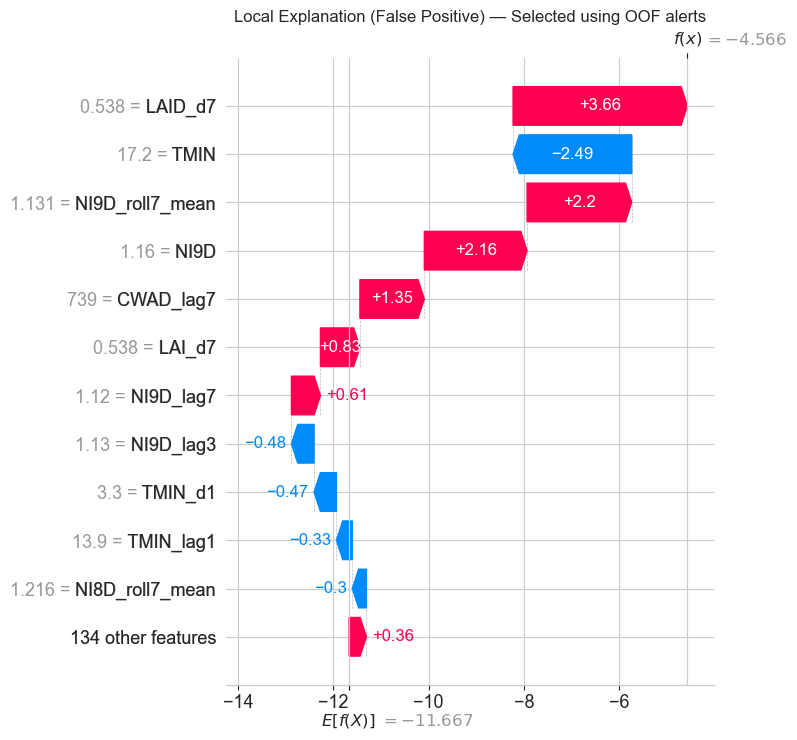

In [47]:
# ============================================================
# SECTION 12.3C: FALSE POSITIVE SHAP WATERFALL
# Explain one alert that did not lead to GSTD 5 within the 7-day window.
# ============================================================

import shap
import numpy as np
import matplotlib.pyplot as plt

# Quick checks before plotting
assert "fp_best" in globals() and fp_best is not None, "fp_best not set (or no FP at this threshold). Run OOF selection cell first."
assert "model_final" in globals(), "model_final not found."
assert "df_ts2" in globals(), "df_ts2 not found."
assert "feature_cols_final" in globals(), "feature_cols_final not found."

df_meta = df_oof if "df_oof" in globals() else df_ts2
assert "p_enter5_7_oof" in df_meta.columns and "y_enter5_7" in df_meta.columns, "Missing OOF metadata columns."

X_all = df_ts2[feature_cols_final]
explainer = shap.TreeExplainer(model_final)

idx = fp_best
x_row = X_all.loc[[idx]]

shap_vals = explainer.shap_values(x_row)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]

base = explainer.expected_value
if isinstance(base, (list, np.ndarray)):
    base = base[1]

exp = shap.Explanation(
    values=shap_vals[0],
    base_values=base,
    data=x_row.values[0],
    feature_names=X_all.columns.tolist()
)

print(f"FP index: {idx} | p_oof={df_meta.loc[idx, 'p_enter5_7_oof']:.6f} | y={int(df_meta.loc[idx, 'y_enter5_7'])}")

plt.figure(figsize=(8, 5))
shap.plots.waterfall(exp, max_display=12, show=False)
plt.title("Local Explanation (False Positive) — Selected using OOF alerts")
plt.tight_layout()
plt.show()

### Example 2 — False Positive (Alert triggered, but Stage 5 did not occur)
*(Insert/keep the FP SHAP waterfall plot directly above this text.)*

**What happened:** The model triggered an alert, but the crop **did not enter Stage 5 within 7 days** (false alarm).

**Why it looked like Stage 5 was near (drivers pushing risk up):**
- **`LAID_d7`** was high and pushed risk up → strong weekly growth acceleration.
- **Nitrogen signals** (**`NI9D`**, **`NI9D_roll7_mean`**) also pushed risk up.
- **`CWAD_lag7`** and **`LAI_d7`** supported the “approaching stage” trajectory.

**Why the model’s confidence was pulled down (drivers pushing risk down):**
- **`TMIN`** had a large negative effect here → cooler minimum temperatures can slow development and delay stage entry.
- Related temperature-history terms (**`TMIN_d1`**, **`TMIN_lag1`**) also reduced risk.

**Takeaway:** This FP illustrates the real early-warning tradeoff: the crop showed **strong growth + nitrogen patterns**, but **environmental conditions (especially minimum temperature)** likely delayed Stage-5 entry beyond the 7-day window.

### Note on interpreting the SHAP waterfall numbers 

- The value at the top of the waterfall (**f(x)**) is the model’s **internal score** (typically **log-odds / raw score** for LightGBM), **not** a probability.  
  - Large positive **f(x)** → probability near 1  
  - Negative **f(x)** → probability near 0

- The model starts from a baseline shown at the bottom (**E[f(X)]**). In our case it is very negative (≈ **−11.667**) because **entering Stage 5 within 7 days is a rare event (~5%)**.  
  The red and blue bars show how features push the score **up (red)** or **down (blue)** from that baseline.

- In the **True Positive** example, multiple strong positive contributors (e.g., `LAID_d7`, `NI9D`, `NI9D_roll7_mean`, `CWAD_lag7`) push the score from the low baseline to a large positive value (**f(x)=10.125**), indicating very high risk.

- In the **False Positive** example, several features push the score upward (growth and nitrogen signals), but a few **strong negative** contributors (especially `TMIN` and related temperature-history terms) push downward. Because the baseline is already very low, these negative effects can keep the final score negative (**f(x)=−4.566**) even if there are several red bars.

- The alert decision in our evaluation is based on the **out-of-fold (OOF) predicted probability** (`p_enter5_7_oof`) from GroupKFold by RUNNO. The waterfall plot explains the refit model’s internal scoring behavior for that row, so the displayed **f(x)** may not numerically match the exact OOF probability used to select the example.